In [3]:
import numpy as np
from scipy.special import softmax
import pandas as pd
import seaborn as sns
import pylab as pl
from scipy.optimize import minimize, differential_evolution
# import belief_mix_model as bmm
# import belief_mix_model_reward_comparison as bmm_spat
# import belief_mix_model_reward_comparison_more_models as bmm_spat_wo_effort
# import belief_mix_model_reward_comparison_more_models_with_effort as bmm_spat_with_effort
# import belief_mix_model_reward_comparison_more_models_with_effort_wo_reward as bmm_spat_with_effort_wo_rew
from scipy.spatial.distance import cdist,pdist,euclidean
from collections import Counter
import scipy as sp
import matplotlib.cm as cm
from matplotlib.patches import Ellipse
import scipy.stats as sp_st
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D      


In [31]:
data_dir = "../../../../Lucas_Cecile/"
fig_dir = "../figures/"

In [32]:
# processed_data = pd.read_csv(data_dir+"extracted_trajs.csv")
processed_data = pd.read_csv(data_dir+"extracted_trajs_updated.csv")
random_agent = pd.read_csv(data_dir+"random_agent.csv")

DIRECTIONS = {
    "left":       (0, -1),
    "right":      (0, 1),
    "up":          (-1, 0),
    "down":        (1, 0),
    "up_left":     (-1, -1),
    "up_right":    (-1, 1),
    "down_left":   (1, -1),
    "down_right":  (1, 1),
}
MODEL_C_NAMES = [
    "left", "right", "up", "down",
    "clockwise_spiral", "counter_clockwise_spiral"
]

all_data = pd.concat([processed_data, random_agent])

In [33]:
k_per_model=dict({'A':9,'A(effort)':10,'B':13,'B(effort)': 14,'C':11, 'C(effort)':12,'A(effort_wo_reward)':9,'B(effort_wo_reward)':13,'C(effort_wo_reward)':11 })
marker_model = dict({'A':'p','B':'D','C':'o'})

In [34]:

all_model_fittings = pd.read_csv(data_dir+"all_model_fits.csv")

In [35]:
all_model_fittings.columns

Index(['Unnamed: 0', 'Model', 'Subject', 'Phase', 'Species', 'NLL',
       'NLL_per_choice', 'Random_NLL_per_choice', 'nchoices', 'success',
       'WS(row)', 'WS(column)', 'WS(cw_spiral)', 'WS(ccw_spiral)',
       'W(spatial_bias)', 'W(reward)', 'W(memory)', 'memory_recall', 'beta',
       'WS(left)', 'WS(right)', 'WS(up)', 'WS(down)', 'WS(up_left)',
       'WS(up_right)', 'WS(down_left)', 'WS(down_right)',
       'WS(clockwise_spiral)', 'WS(counter_clockwise_spiral)', 'BIC',
       'W(effort)'],
      dtype='object')

In [36]:
all_model_fittings.iloc[0]

Unnamed: 0                                   0
Model                                        A
Subject                                Amidala
Phase                              Habituation
Species                         Macaca_mulatta
NLL                                 229.022001
NLL_per_choice                        2.410758
Random_NLL_per_choice                 3.218876
nchoices                                    95
success                                   True
WS(row)                               0.387741
WS(column)                            0.365405
WS(cw_spiral)                         0.027199
WS(ccw_spiral)                        0.219655
W(spatial_bias)                        4.63319
W(reward)                             4.316753
W(memory)                             8.026957
memory_recall                         0.921152
beta                                  4.394497
WS(left)                                   NaN
WS(right)                                  NaN
WS(up)       

In [37]:
# recovery_df = pd.read_csv(data_dir+"recovery_reward_models_A_B.csv")
# recovery_df

In [38]:
# model_fittings = model_fittings.loc[model_fittings['Model']!='C']
# model_fittings = model_fittings.loc[model_fittings['Model']=='A']

In [39]:
# recovery_df = recovery_df.loc[recovery_df['Model']!='C']
# recovery_df_A = recovery_df.loc[recovery_df['Model']=='A']

In [40]:
phase_order = ['Habituation', 'Test','Post-test']
cmap1 = 'Accent'
colors_acc = [cm.get_cmap('Accent',10)(0), cm.get_cmap('Accent',10)(3) ]

cmap2 = 'tab10'
cmap3 = 'prism'
colors =[ cm.get_cmap('gist_rainbow',10)(i) for i in range(10)] #[cm.get_cmap('prism',10)(0),cm.get_cmap('prism',10)(1),cm.get_cmap('prism',10)(2),cm.get_cmap('prism',10)(3),cm.get_cmap('prism',10)(4),cm.get_cmap('prism',10)(5) ]
cmap4 = dict({'data':'hotpink','model - A':colors[0], 'model - B':colors[1], 'model - C':colors[2],'model - A(effort)':colors[3], 'model - B(effort)':colors[4], 'model - C(effort)':colors[5],'model - A(effort_wo_reward)':colors[6], 'model - B(effort_wo_reward)':colors[7], 'model - C(effort_wo_reward)':colors[8] })

/tmp/ipykernel_975429/140345194.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors_acc = [cm.get_cmap('Accent',10)(0), cm.get_cmap('Accent',10)(3) ]
/tmp/ipykernel_975429/140345194.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors =[ cm.get_cmap('gist_rainbow',10)(i) for i in range(10)] #[cm.get_cmap('prism',10)(0),cm.get_cmap('prism',10)(1),cm.get_cmap('prism',10)(2),cm.get_cmap('prism',10)(3),cm.get_cmap('prism',10)(4),cm.get_cmap('prism',10)(5) ]


In [41]:
sns.set(style='whitegrid')

In [42]:
def plot_boxplots_with_points(x_var,y_var,col_var,hue_var,order,palette,data,col_wrap,dodge=False,sharey=True,col_order=None):
   
    g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
    for ax in g1.axes:
        for x in ax.get_xticklabels():
            x.set_rotation(45)
            x.set_ha('right')
        ax.set_xlabel("")
        tit = ax.get_title().split(' = ')[1]
        sub = data.loc[data[col_var]==tit].copy()
        sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
        ax.set_xlabel("")
    g1.figure.subplots_adjust(bottom=0.2)

    return g1

/tmp/ipykernel_975429/1902240995.py:3: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_

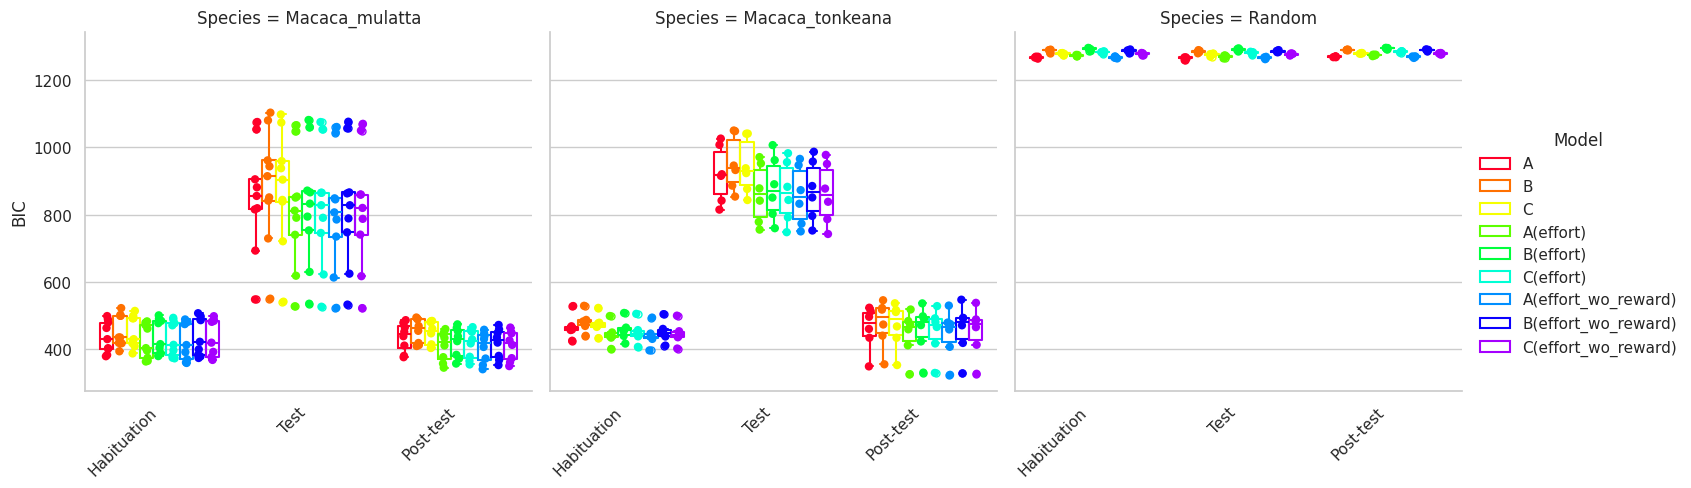

In [43]:
g1 = plot_boxplots_with_points("Phase","BIC","Species","Model",phase_order,colors,all_model_fittings,3,True)

# for ax in g1.axes:
#     xlims = ax.get_xlim()
#     ax.hlines(y=3.22,xmin=xlims[0],xmax=xlims[1],ls='dashed',color='k',lw=1.5)
#     ax.set_xlim(xlims[0],xlims[1])
# g1.savefig(fig_dir+"BIC_with_respect_to_chance_level_high_res_space_updated_with_effort.png")
g1.savefig(fig_dir+"BIC_with_respect_to_chance_level_high_res_space_updated_with_effort_wo_reward.png")

In [44]:
min_BIC_df = pd.DataFrame()
for grp in all_model_fittings.groupby(['Subject','Phase','Species']):
    min_bic = grp[1]['BIC'].min()
    grp[1][r'$\Delta$'+'BIC'] = grp[1]['BIC'] - min_bic
    min_BIC_df = pd.concat([min_BIC_df,grp[1]])

In [45]:
min_BIC_df

,Unnamed: 0,Model,Subject,Phase,Species,NLL,NLL_per_choice,Random_NLL_per_choice,nchoices,success,...,WS(down),WS(up_left),WS(up_right),WS(down_left),WS(down_right),WS(clockwise_spiral),WS(counter_clockwise_spiral),BIC,W(effort),$\Delta$BIC
0,0,A,Amidala,Habituation,Macaca_mulatta,229.022001,2.410758,3.218876,95,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,499.028895,NaN,17.562217
59,59,B,Amidala,Habituation,Macaca_mulatta,231.739588,2.439364,3.218876,95,True,...,0.183849,0.040815,0.104350,0.091240,0.080070,NaN,NaN,522.679575,NaN,41.212897
118,118,C,Amidala,Habituation,Macaca_mulatta,232.139856,2.443577,3.218876,95,True,...,0.089984,NaN,NaN,NaN,NaN,0.211086,0.357446,514.372358,NaN,32.905680
177,0,A(effort),Amidala,Habituation,Macaca_mulatta,218.872355,2.303920,3.218876,95,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,483.283479,9.374837,1.816801
236,59,B(effort),Amidala,Habituation,Macaca_mulatta,218.679614,2.301891,3.218876,95,True,...,0.454074,0.000097,0.080507,0.000021,0.003433,NaN,NaN,501.113505,5.976361,19.646827
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,117,B(effort),Yin,Test,Macaca_tonkeana,466.775521,2.456713,3.218876,190,True,...,0.894347,0.000041,0.000287,0.103432,0.000332,NaN,NaN,1007.009378,9.726644,41.033741
353,176,C(effort),Yin,Test,Macaca_tonkeana,459.925833,2.420662,3.218876,190,True,...,0.319796,NaN,NaN,NaN,NaN,0.000015,0.225729,982.815955,9.995278,16.840317
412,58,A(effort_wo_reward),Yin,Test,Macaca_tonkeana,459.376211,2.417770,3.218876,190,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,965.975638,8.452030,0.000000
471,117,B(effort_wo_reward),Yin,Test,Macaca_tonkeana,459.477181,2.418301,3.218876,190,True,...,0.390705,0.000028,0.000199,0.119527,0.000044,NaN,NaN,987.165674,4.928644,21.190037


In [46]:
min_BIC_df.groupby(['Model','Species','Phase'])[r'$\Delta$'+'BIC'].mean().reset_index()

,Model,Species,Phase,$\Delta$BIC
0,A,Macaca_mulatta,Habituation,17.045054
1,A,Macaca_mulatta,Post-test,30.694440
2,A,Macaca_mulatta,Test,42.876695
3,A,Macaca_tonkeana,Habituation,26.538569
4,A,Macaca_tonkeana,Post-test,19.358139
...,...,...,...,...
76,C(effort_wo_reward),Macaca_tonkeana,Post-test,9.283216
77,C(effort_wo_reward),Macaca_tonkeana,Test,6.549598
78,C(effort_wo_reward),Random,Habituation,10.734605
79,C(effort_wo_reward),Random,Post-test,10.266715


/tmp/ipykernel_975429/1902240995.py:3: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_

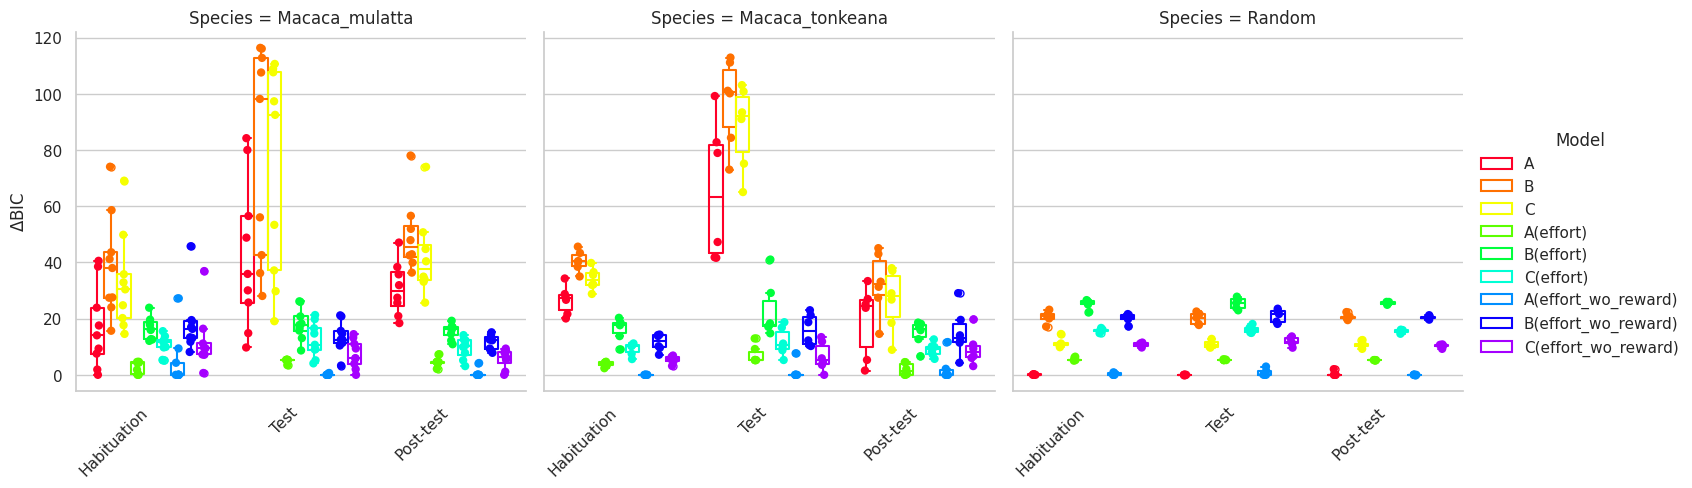

In [47]:
g1 = plot_boxplots_with_points("Phase",r'$\Delta$'+'BIC',"Species","Model",phase_order,colors,min_BIC_df,3,True)
g1.savefig(fig_dir+"min_BIC_comparison.png",dpi=300)

/tmp/ipykernel_975429/1902240995.py:3: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_975429/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_

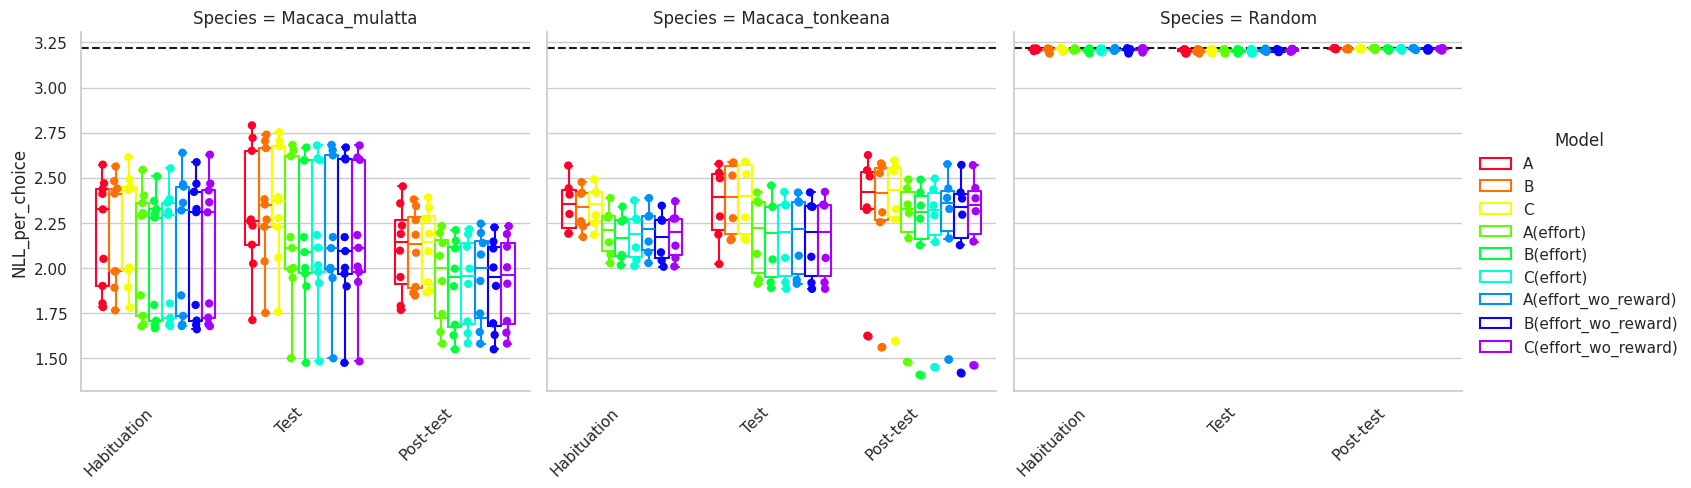

In [48]:
g1 = plot_boxplots_with_points("Phase","NLL_per_choice","Species","Model",phase_order,colors,all_model_fittings,3,True)

for ax in g1.axes:
    xlims = ax.get_xlim()
    ax.hlines(y=3.22,xmin=xlims[0],xmax=xlims[1],ls='dashed',color='k',lw=1.5)
    ax.set_xlim(xlims[0],xlims[1])
# g1.savefig(fig_dir+"LL_with_respect_to_chance_level_high_res_space_updated_with_effort.png")
g1.savefig(fig_dir+"LL_with_respect_to_chance_level_high_res_space_updated_with_effort_wo_reward.png")

In [52]:

compare_stats = pd.read_csv(data_dir+"all_model_stats.csv")
compare_trajs = pd.read_csv(data_dir+"all_model_trajs.csv")
compare_dist_trajs = pd.read_csv(data_dir+"all_model_dist_trajs.csv")
compare_visit_map = pd.read_csv(data_dir+"all_data_visit_map.csv")

In [53]:
#     Vobs = sum(
#         bmm_spat.visit_map(t)
#         for t in act_trajs
#     )


In [54]:
compare_stats.groupby(['Species','type','Phase'])[['revisit_rate','jump_length','first_revisit','total_dist']].mean().reset_index()

,Species,type,Phase,revisit_rate,jump_length,first_revisit,total_dist
0,Macaca_mulatta,data,Habituation,0.050465,1.718058,4.444444,26.911832
1,Macaca_mulatta,data,Post-test,0.038264,1.648690,6.575000,26.886837
2,Macaca_mulatta,data,Test,0.181035,1.594517,8.790698,25.973815
3,Macaca_mulatta,model - A,Habituation,0.136423,1.999449,6.422222,31.508439
4,Macaca_mulatta,model - A,Post-test,0.081725,2.013792,12.500000,32.851047
...,...,...,...,...,...,...,...
85,Random,model - C(effort),Post-test,0.299000,3.160000,5.640000,47.930854
86,Random,model - C(effort),Test,0.251000,3.156842,7.180000,47.751431
87,Random,model - C(effort_wo_reward),Habituation,0.314000,3.045263,5.380000,46.450907
88,Random,model - C(effort_wo_reward),Post-test,0.304000,3.213684,5.780000,48.231862


In [55]:
[np.array(x)[:,0] for x in act_trajs]

[array([1, 2, 1, 4, 4, 3, 3, 2, 2, 3, 2, 3, 4, 4, 2, 1, 0, 0, 1, 0]),
 array([2, 4, 3, 4, 1, 2, 3, 3, 2, 1, 3, 2, 3, 4, 4, 4, 4, 2, 2, 1]),
 array([3, 1, 4, 1, 0, 0, 1, 4, 4, 3, 3, 2, 0, 1, 2, 1, 2, 2, 4, 3]),
 array([1, 3, 3, 3, 3, 4, 2, 1, 2, 2, 2, 1, 1, 3, 4, 1, 1, 2, 4, 4]),
 array([3, 1, 1, 2, 3, 3, 2, 0, 0, 4, 4, 2, 2, 3, 4, 4, 4, 3, 2, 3])]

In [56]:
fit

Unnamed: 0                                   0
Model                                        A
Subject                                Amidala
Phase                              Habituation
Species                         Macaca_mulatta
NLL                                 229.022001
NLL_per_choice                        2.410758
Random_NLL_per_choice                 3.218876
nchoices                                    95
success                                   True
WS(row)                               0.387741
WS(column)                            0.365405
WS(cw_spiral)                         0.027199
WS(ccw_spiral)                        0.219655
W(spatial_bias)                        4.63319
W(reward)                             4.316753
W(memory)                             8.026957
memory_recall                         0.921152
beta                                  4.394497
WS(left)                                   NaN
WS(right)                                  NaN
WS(up)       

In [57]:
len(traj)

20

In [58]:
len(act_trajs[0])

20

In [65]:
stats_melt = compare_stats.melt(id_vars=['Subject','Species','Phase','type','traj_num','Unnamed: 0'])

In [66]:
stats_melt

,Subject,Species,Phase,type,traj_num,Unnamed: 0,variable,value
0,Amidala,Macaca_mulatta,Habituation,data,0,0,revisit_rate,0.000000
1,Amidala,Macaca_mulatta,Habituation,data,1,1,revisit_rate,0.100000
2,Amidala,Macaca_mulatta,Habituation,data,2,2,revisit_rate,0.050000
3,Amidala,Macaca_mulatta,Habituation,data,3,3,revisit_rate,0.100000
4,Amidala,Macaca_mulatta,Habituation,data,4,4,revisit_rate,0.050000
...,...,...,...,...,...,...,...,...
31747,Yin,Macaca_tonkeana,Test,model - C(effort_wo_reward),5,5,total_dist,33.829602
31748,Yin,Macaca_tonkeana,Test,model - C(effort_wo_reward),6,6,total_dist,30.698909
31749,Yin,Macaca_tonkeana,Test,model - C(effort_wo_reward),7,7,total_dist,34.059097
31750,Yin,Macaca_tonkeana,Test,model - C(effort_wo_reward),8,8,total_dist,28.423669


In [67]:
sns.set(style='whitegrid',font_scale=1.5)


<Figure size 640x480 with 0 Axes>

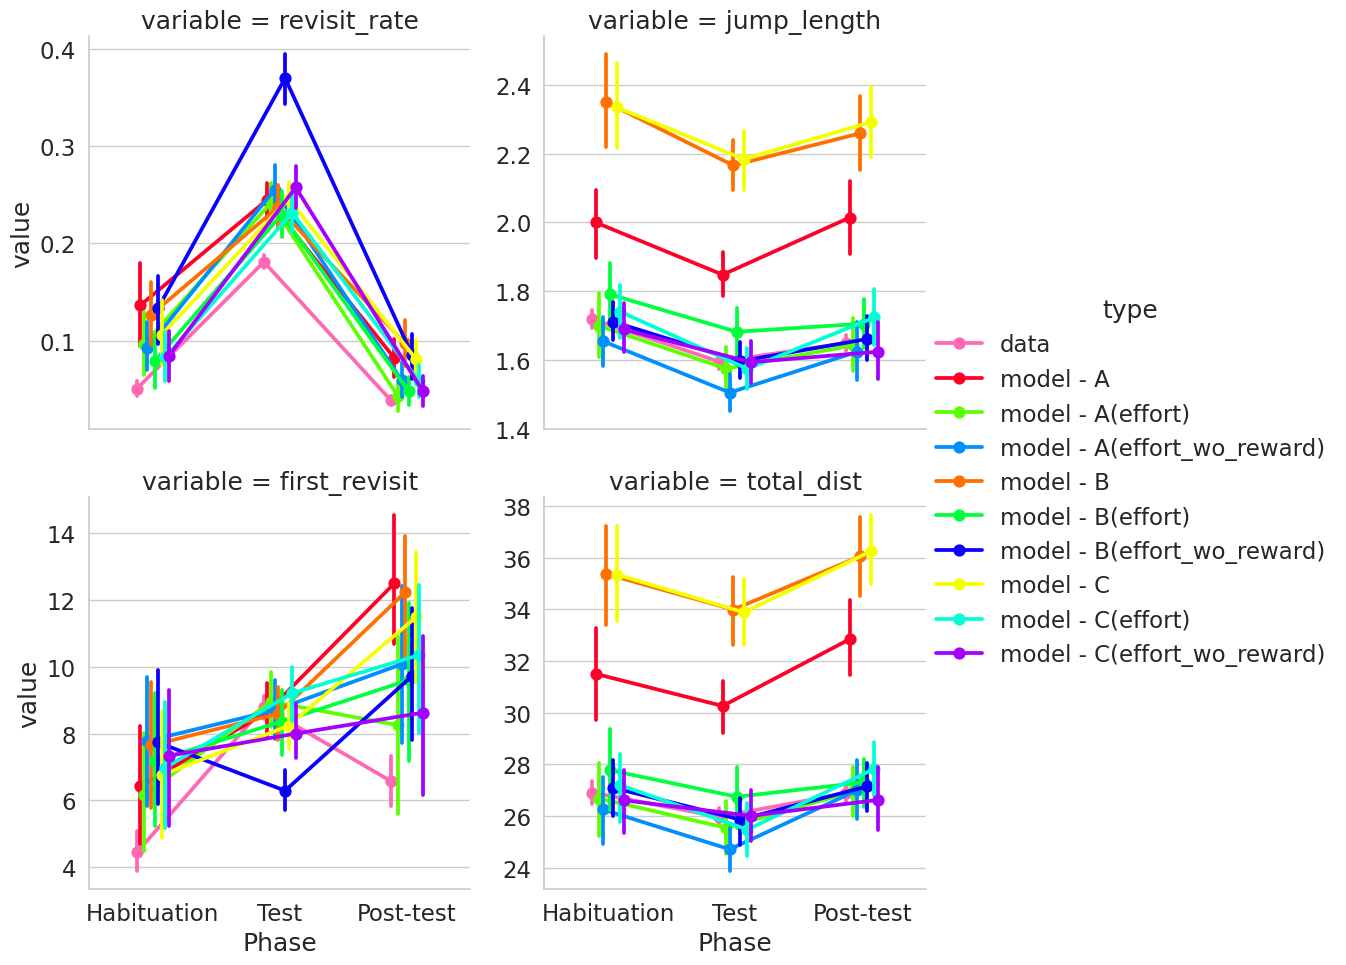

<Figure size 640x480 with 0 Axes>

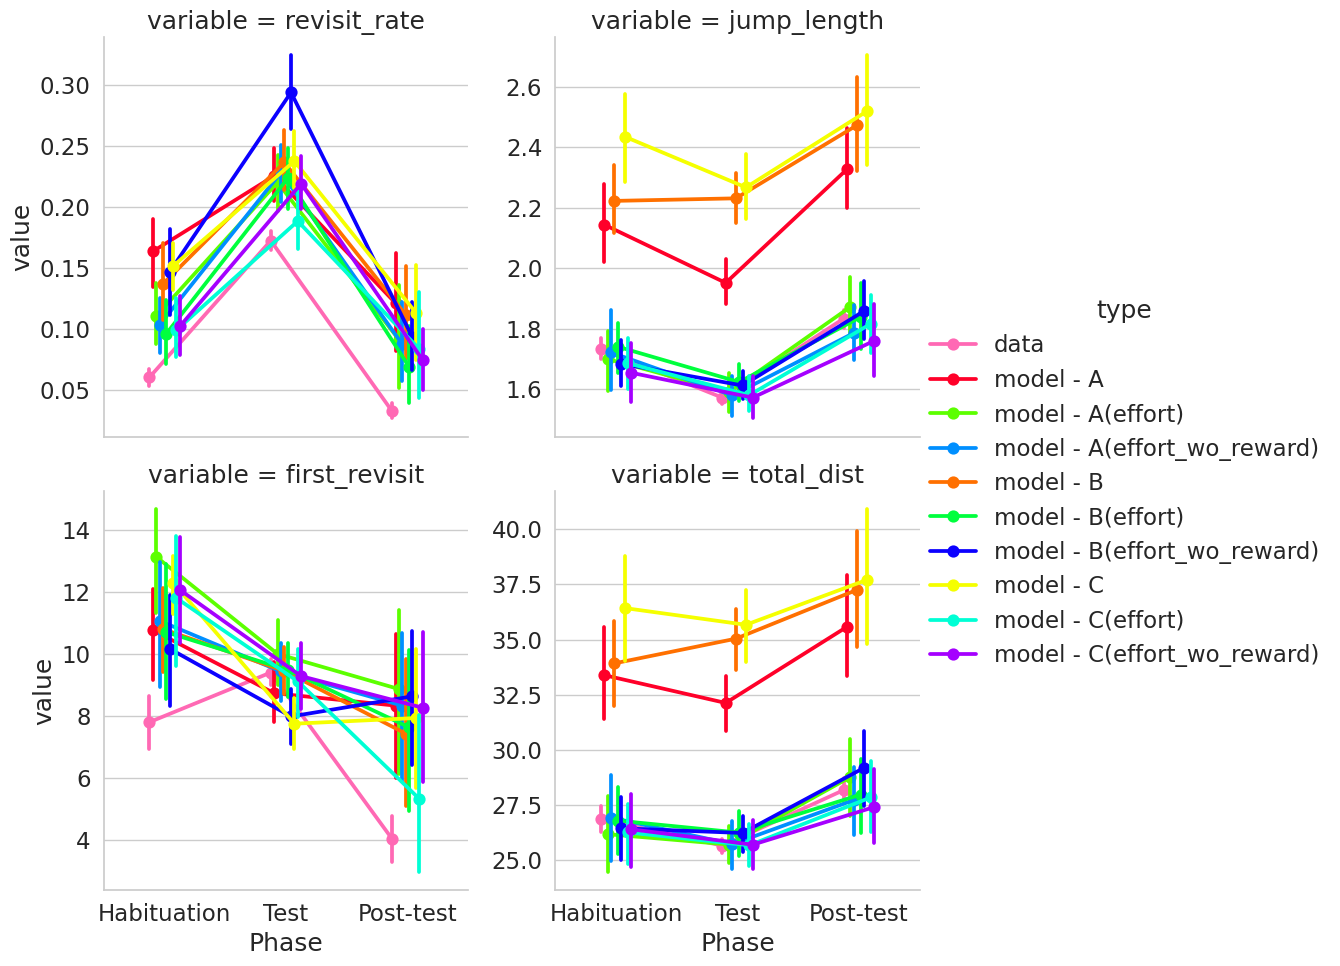

<Figure size 640x480 with 0 Axes>

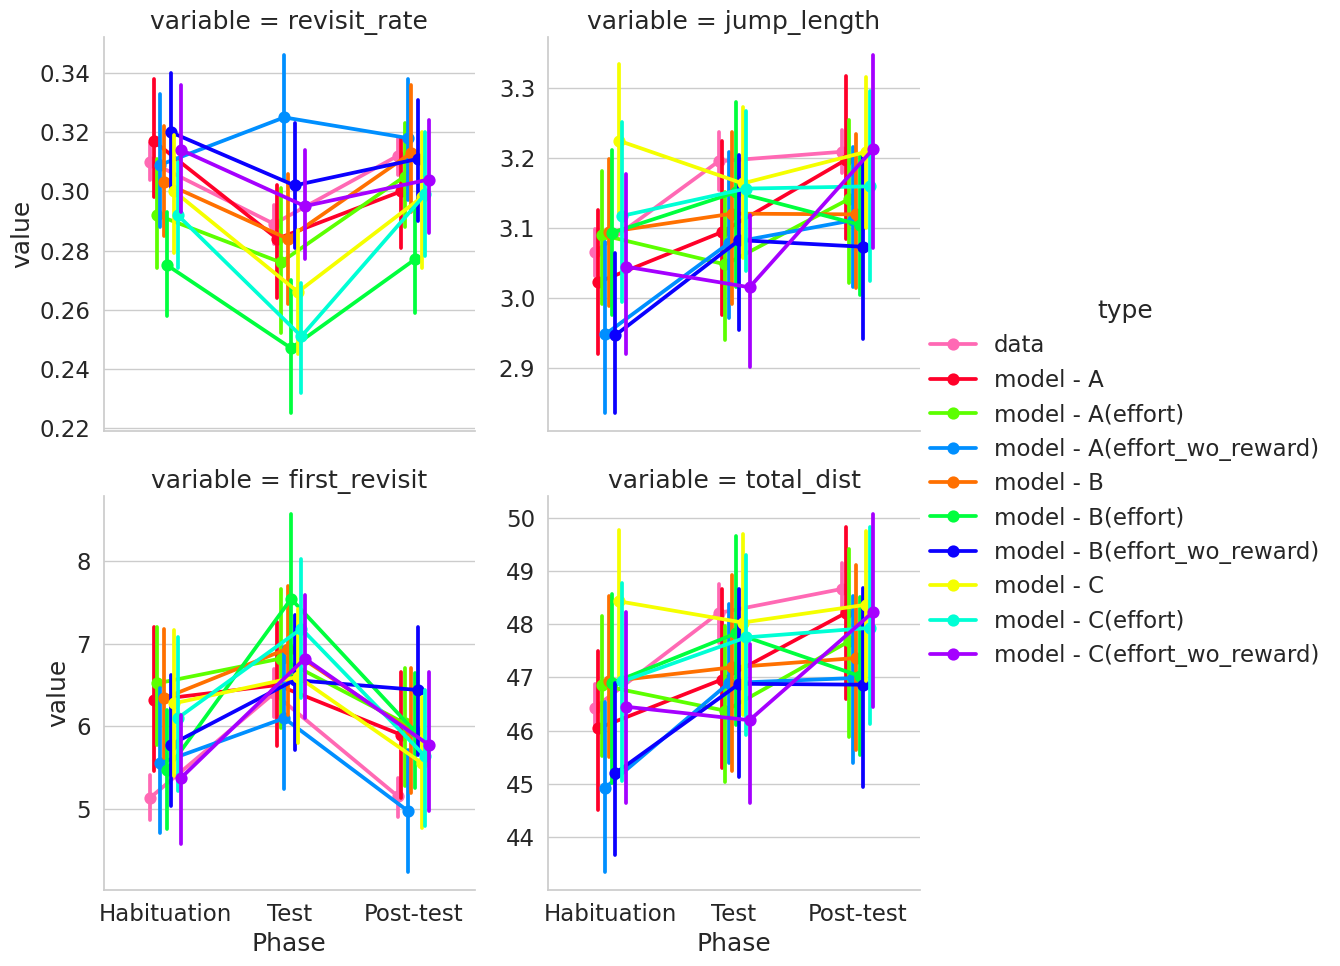

In [68]:
for grp in stats_melt.groupby('Species'):
    pl.figure()
    g1 = sns.catplot(x="Phase",y='value',hue='type',kind='point',col='variable',col_wrap=2,data=grp[1],palette=cmap4,sharey=False,order=phase_order,dodge=True)
#     g1.savefig(fig_dir+"stats_compare_data_model_"+grp[0]+"_model_comparison_"+"high_res_updated_with_effort.png")
    g1.savefig(fig_dir+"stats_compare_data_model_"+grp[0]+"_model_comparison_"+"high_res_updated_with_effort_wo_reward.png")

/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))
/home/jyotika/Utils/envs/strasbourg_school/lib/python3.8/site-packages/seaborn/matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes tra

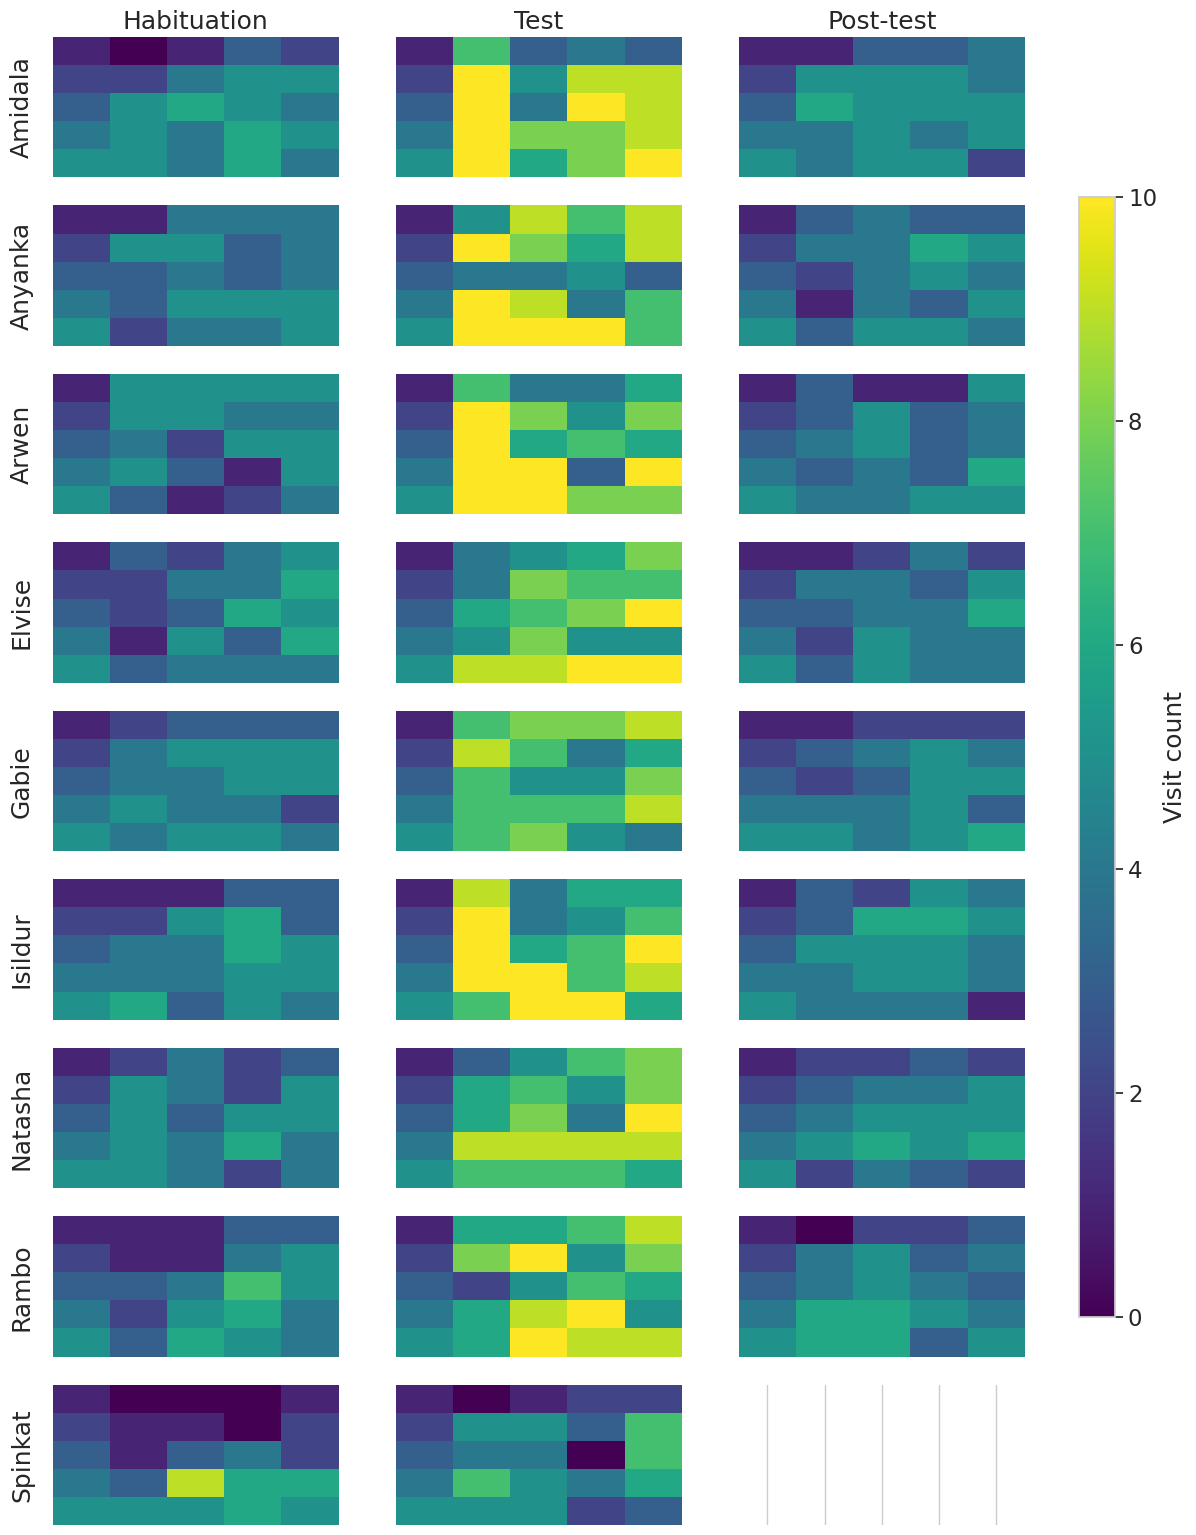

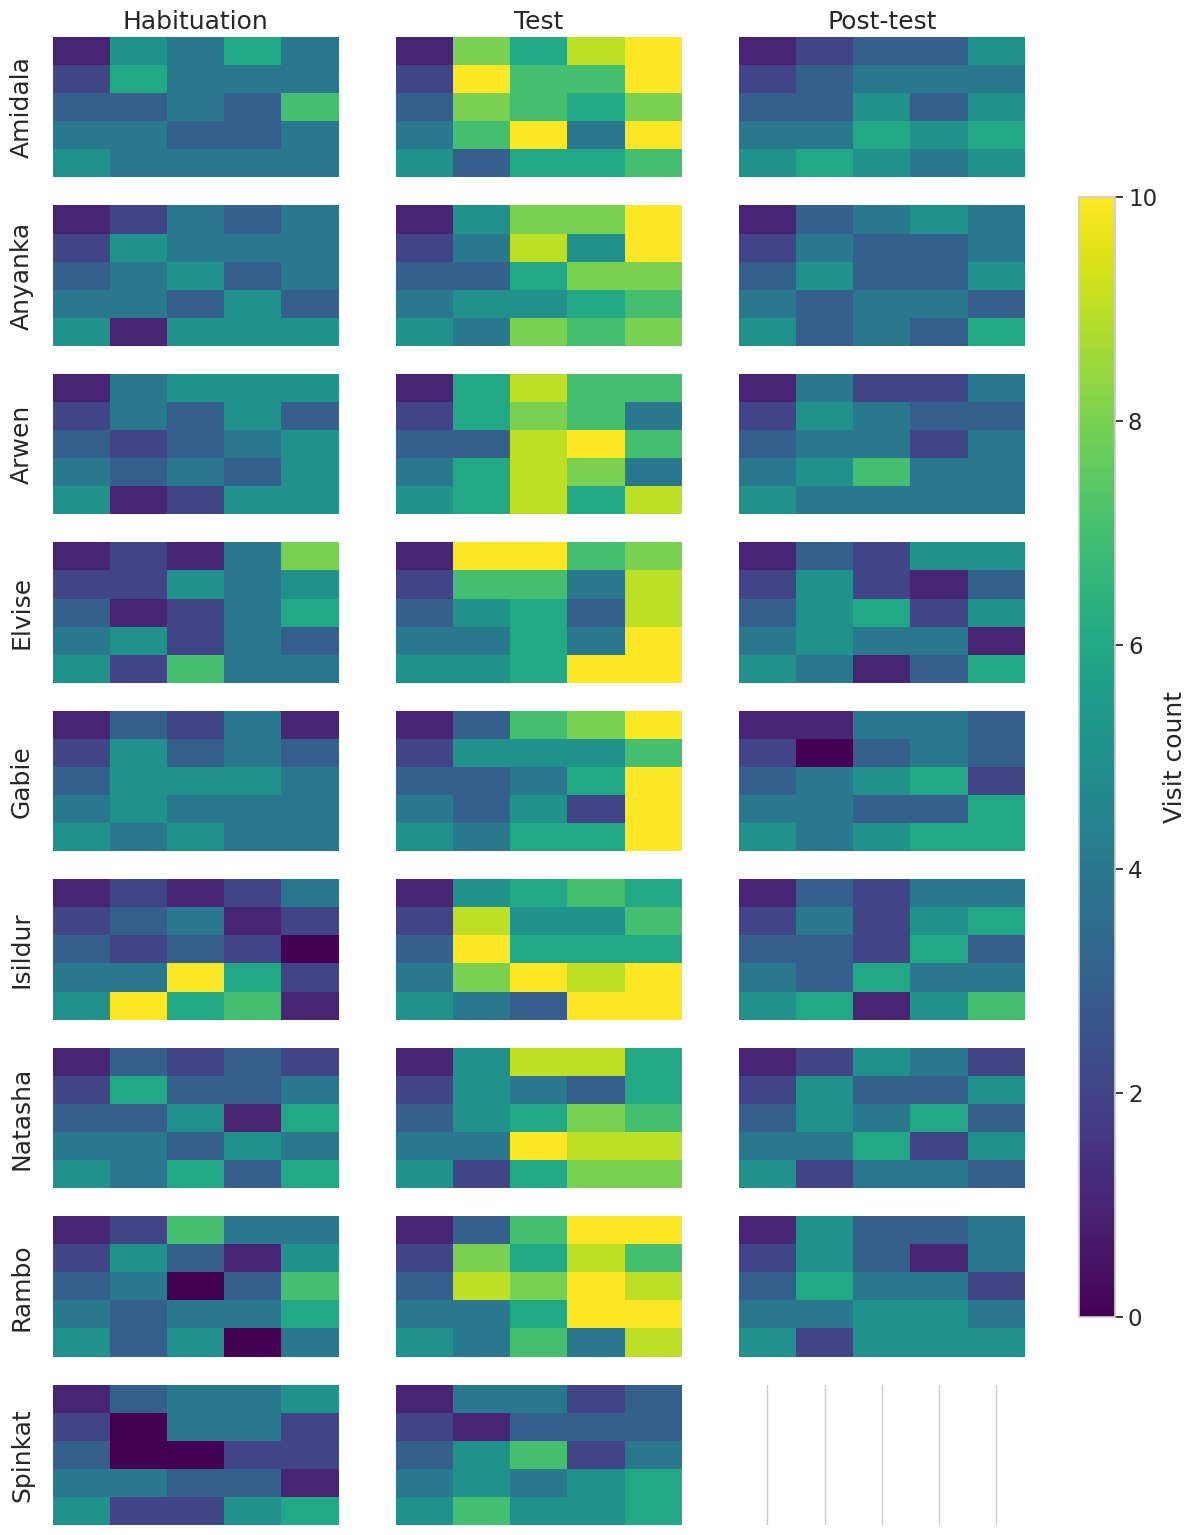

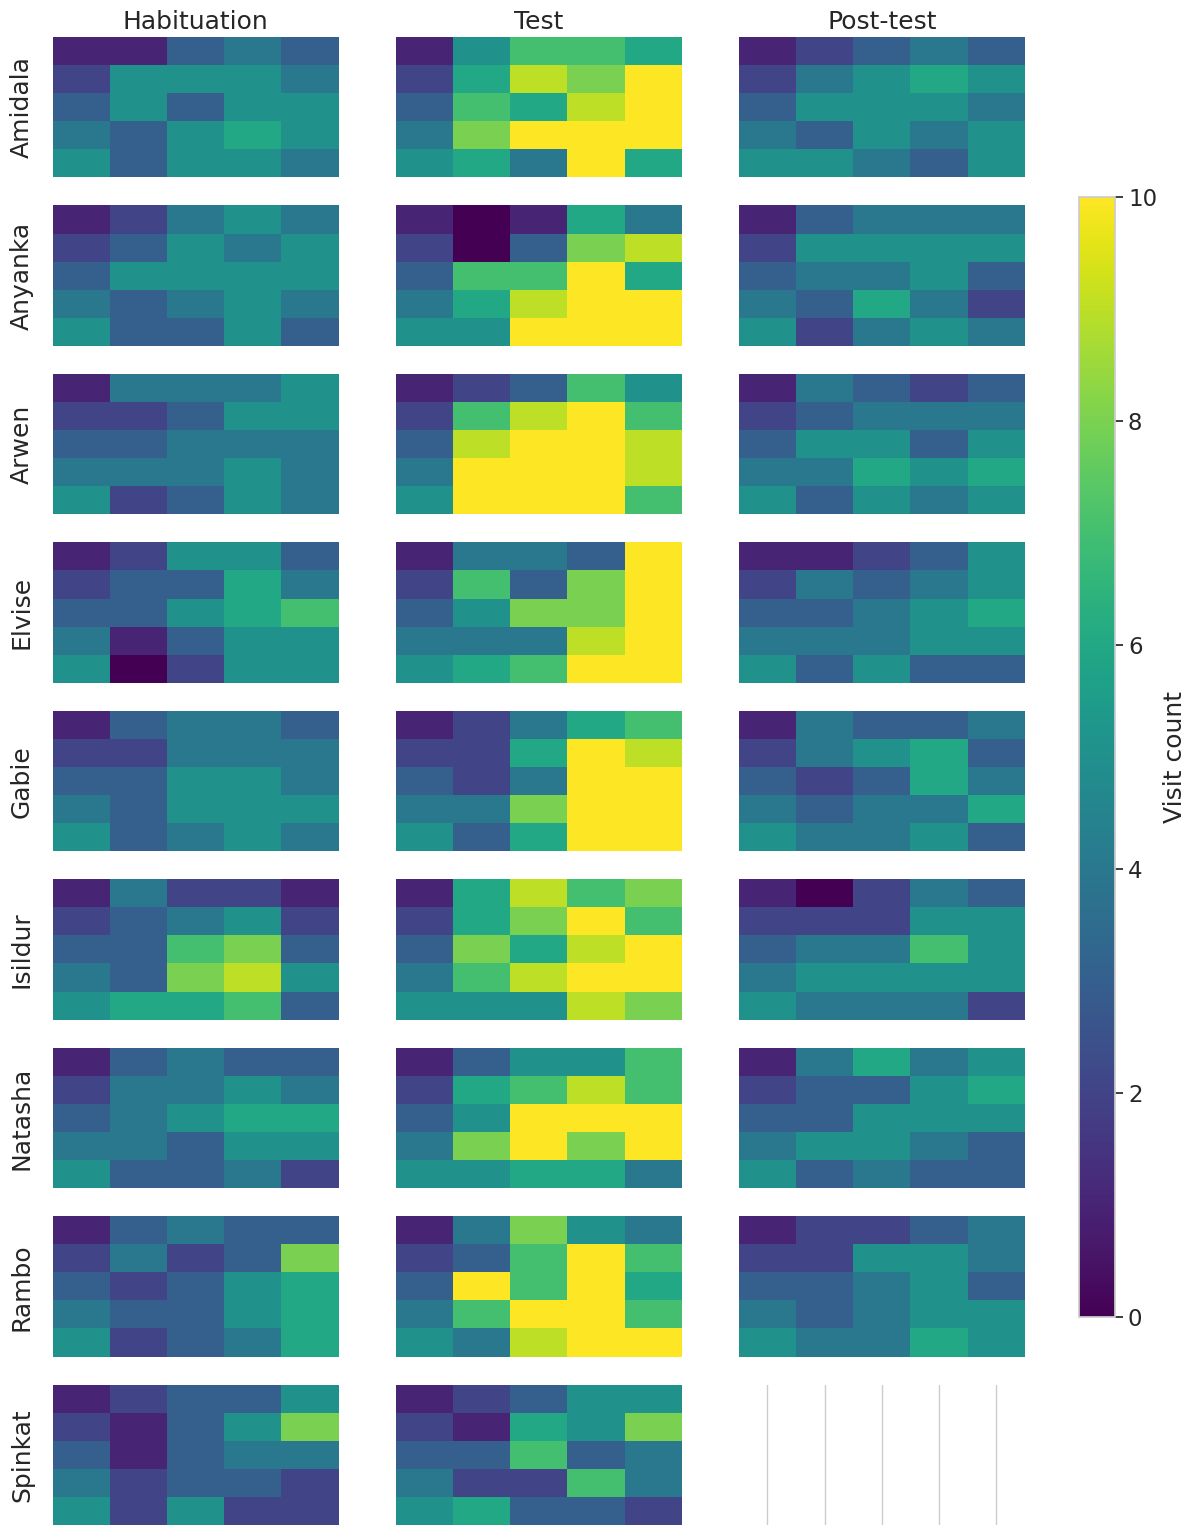

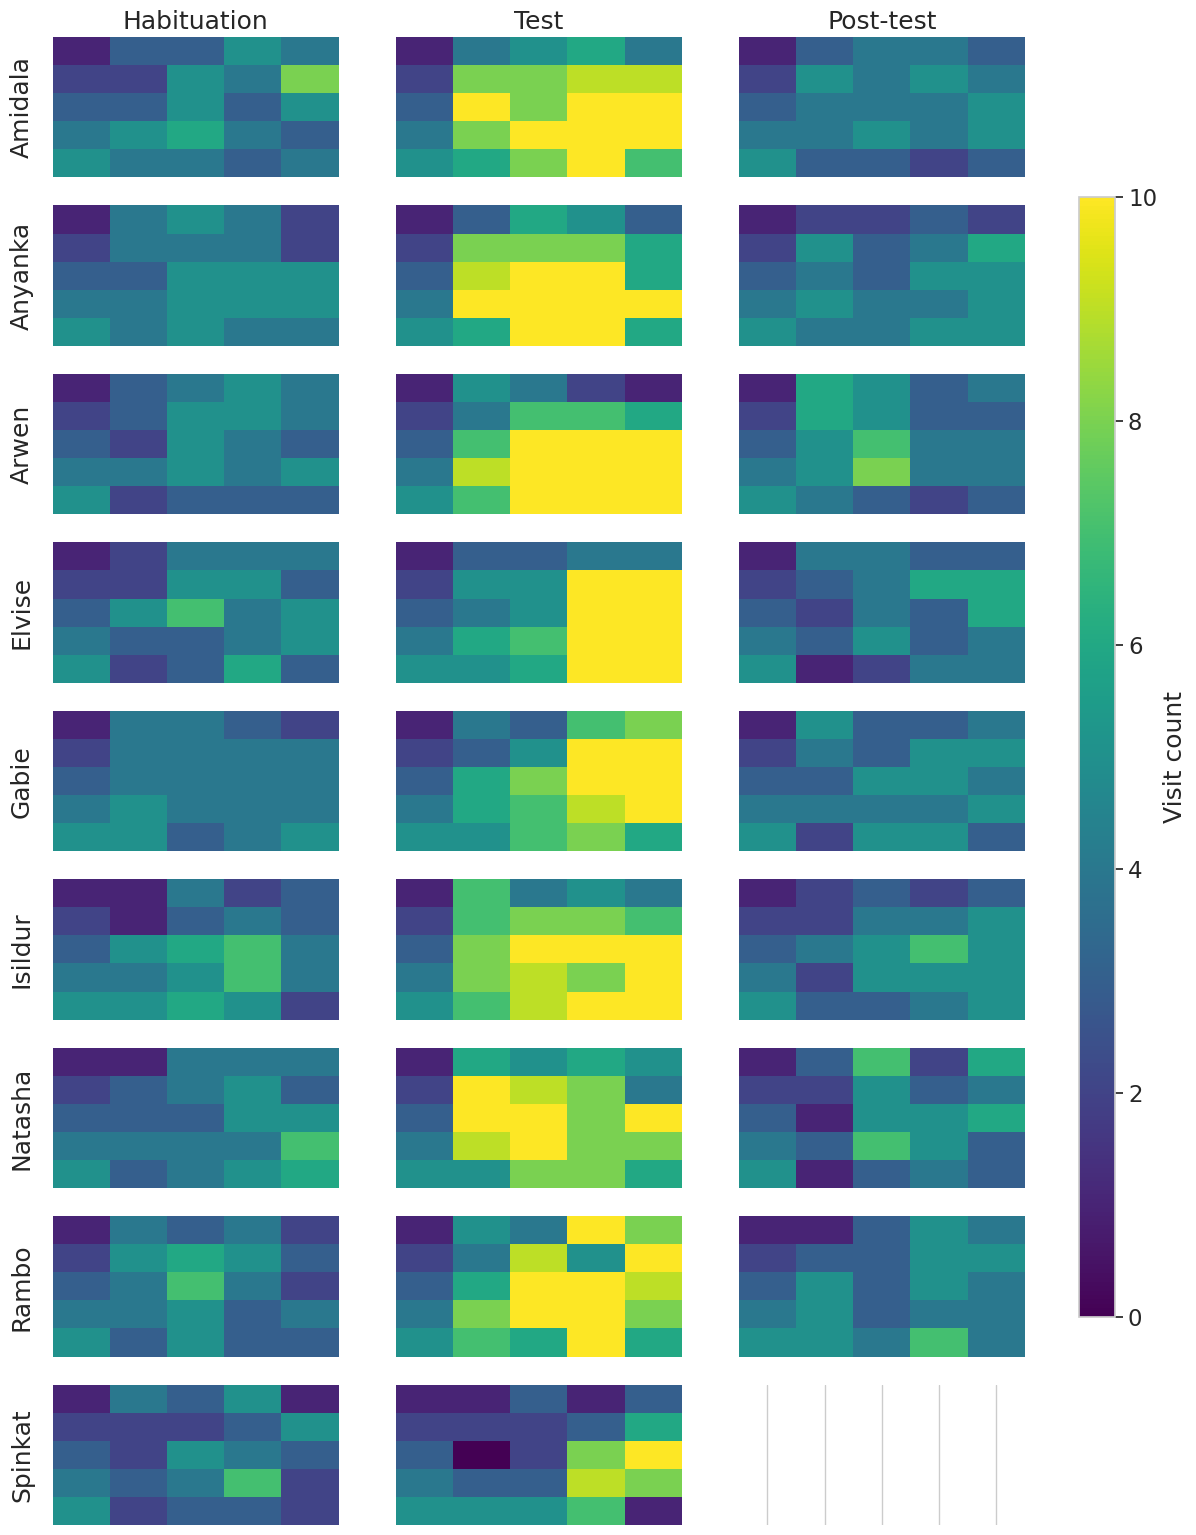

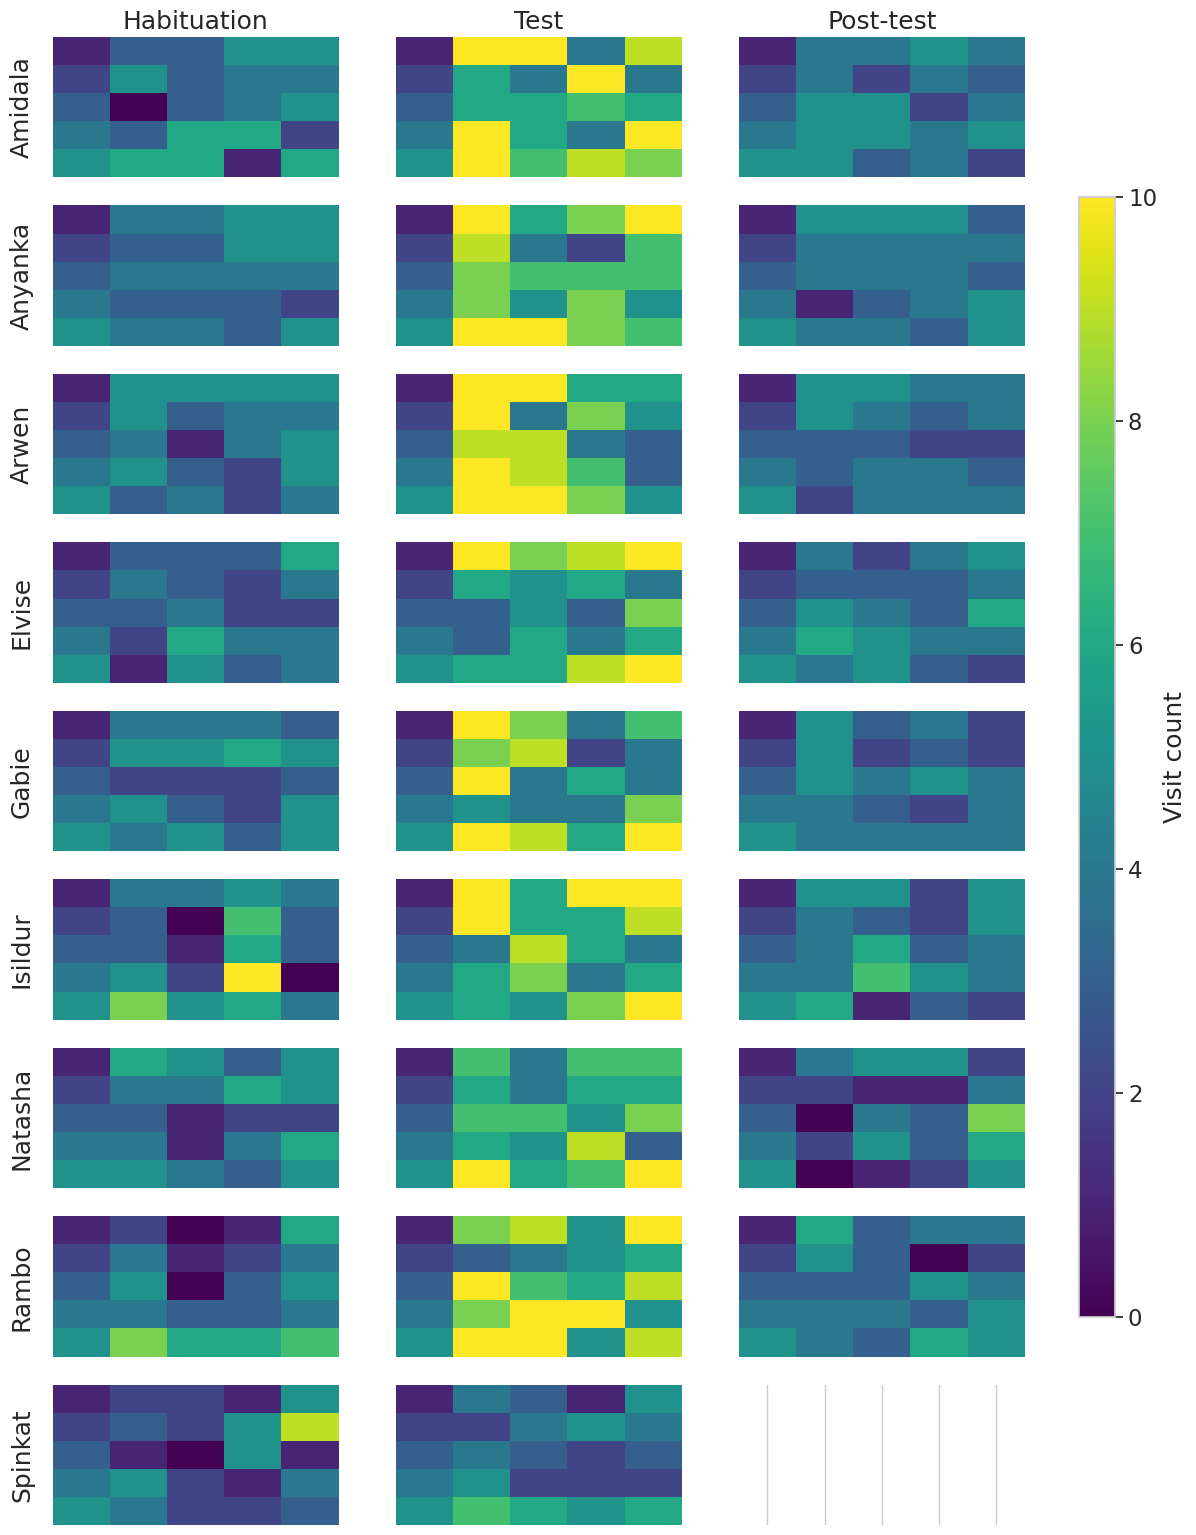

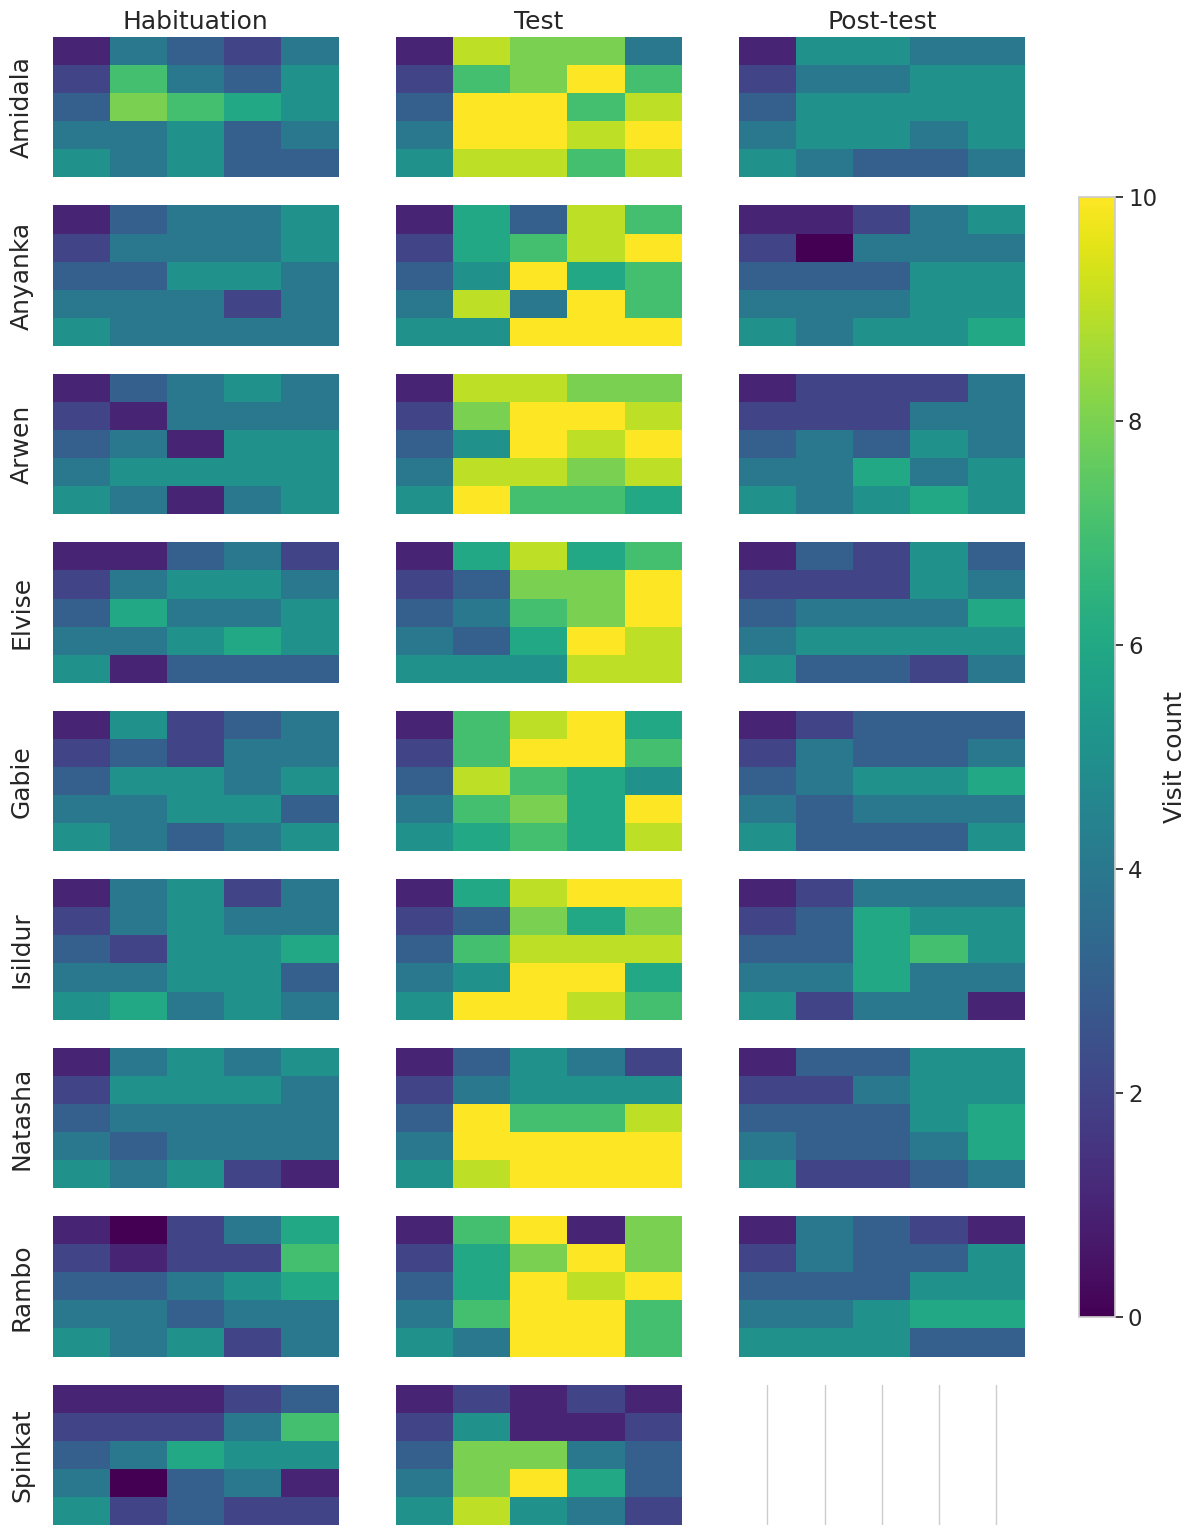

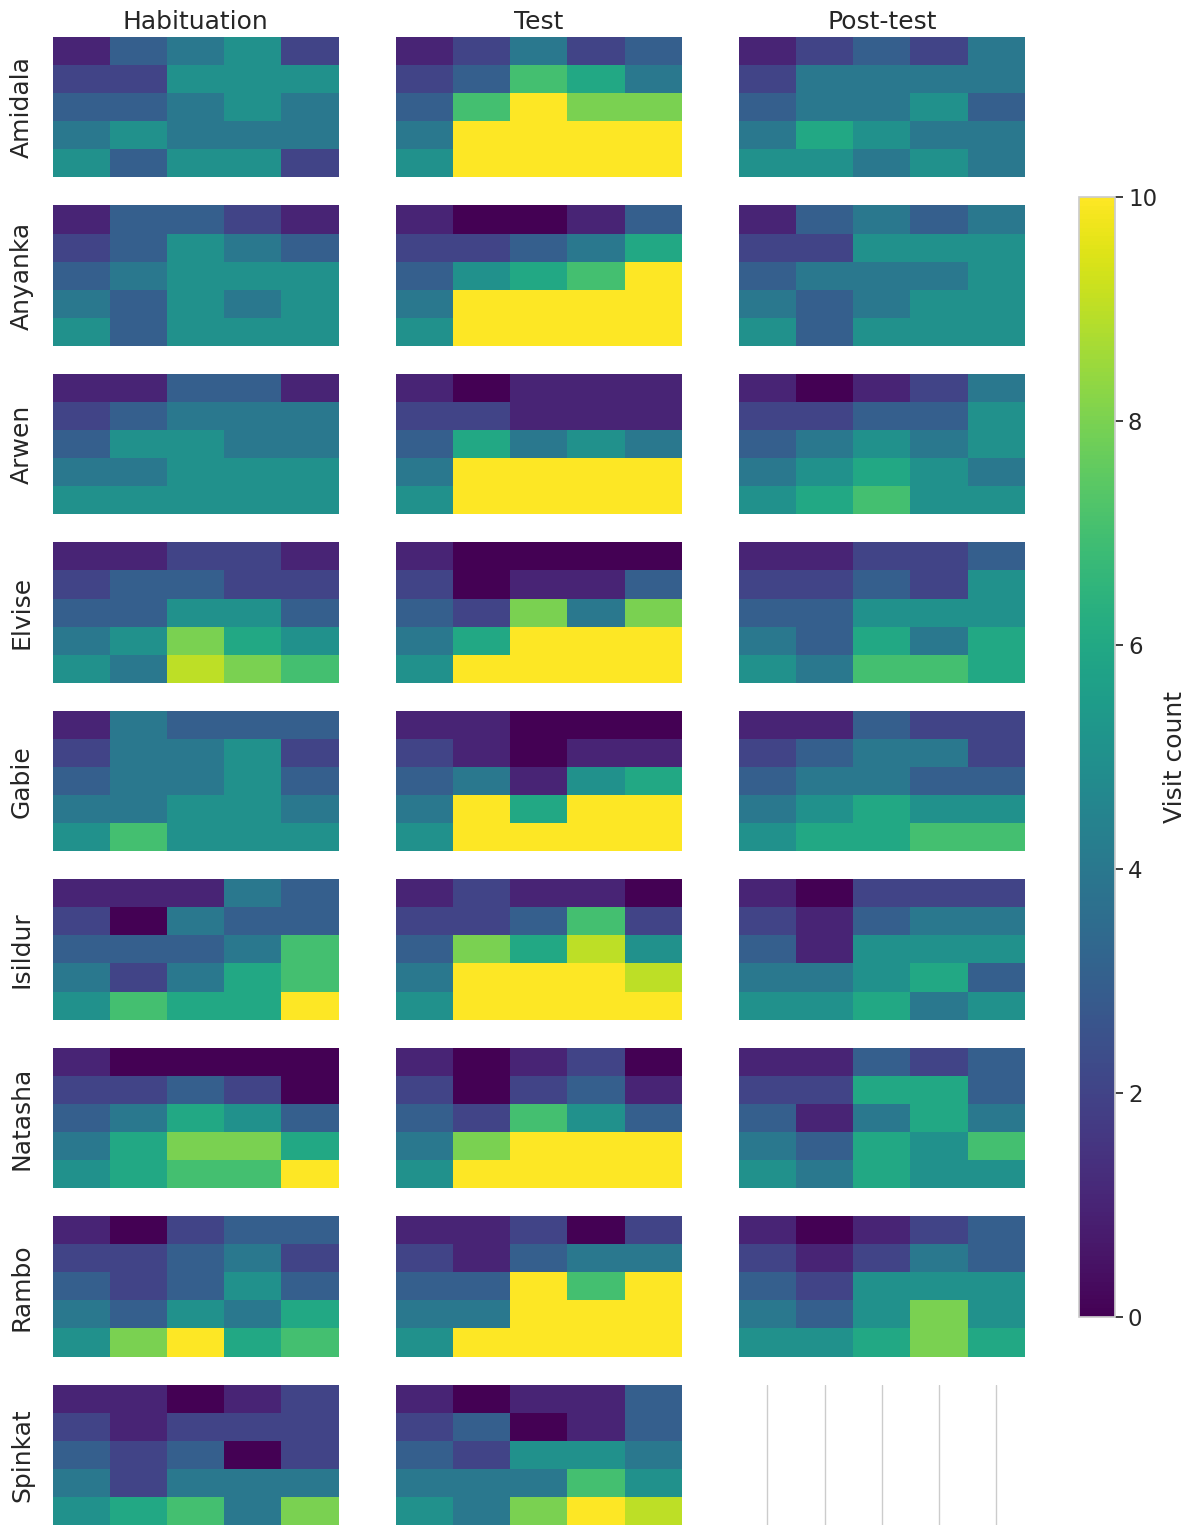

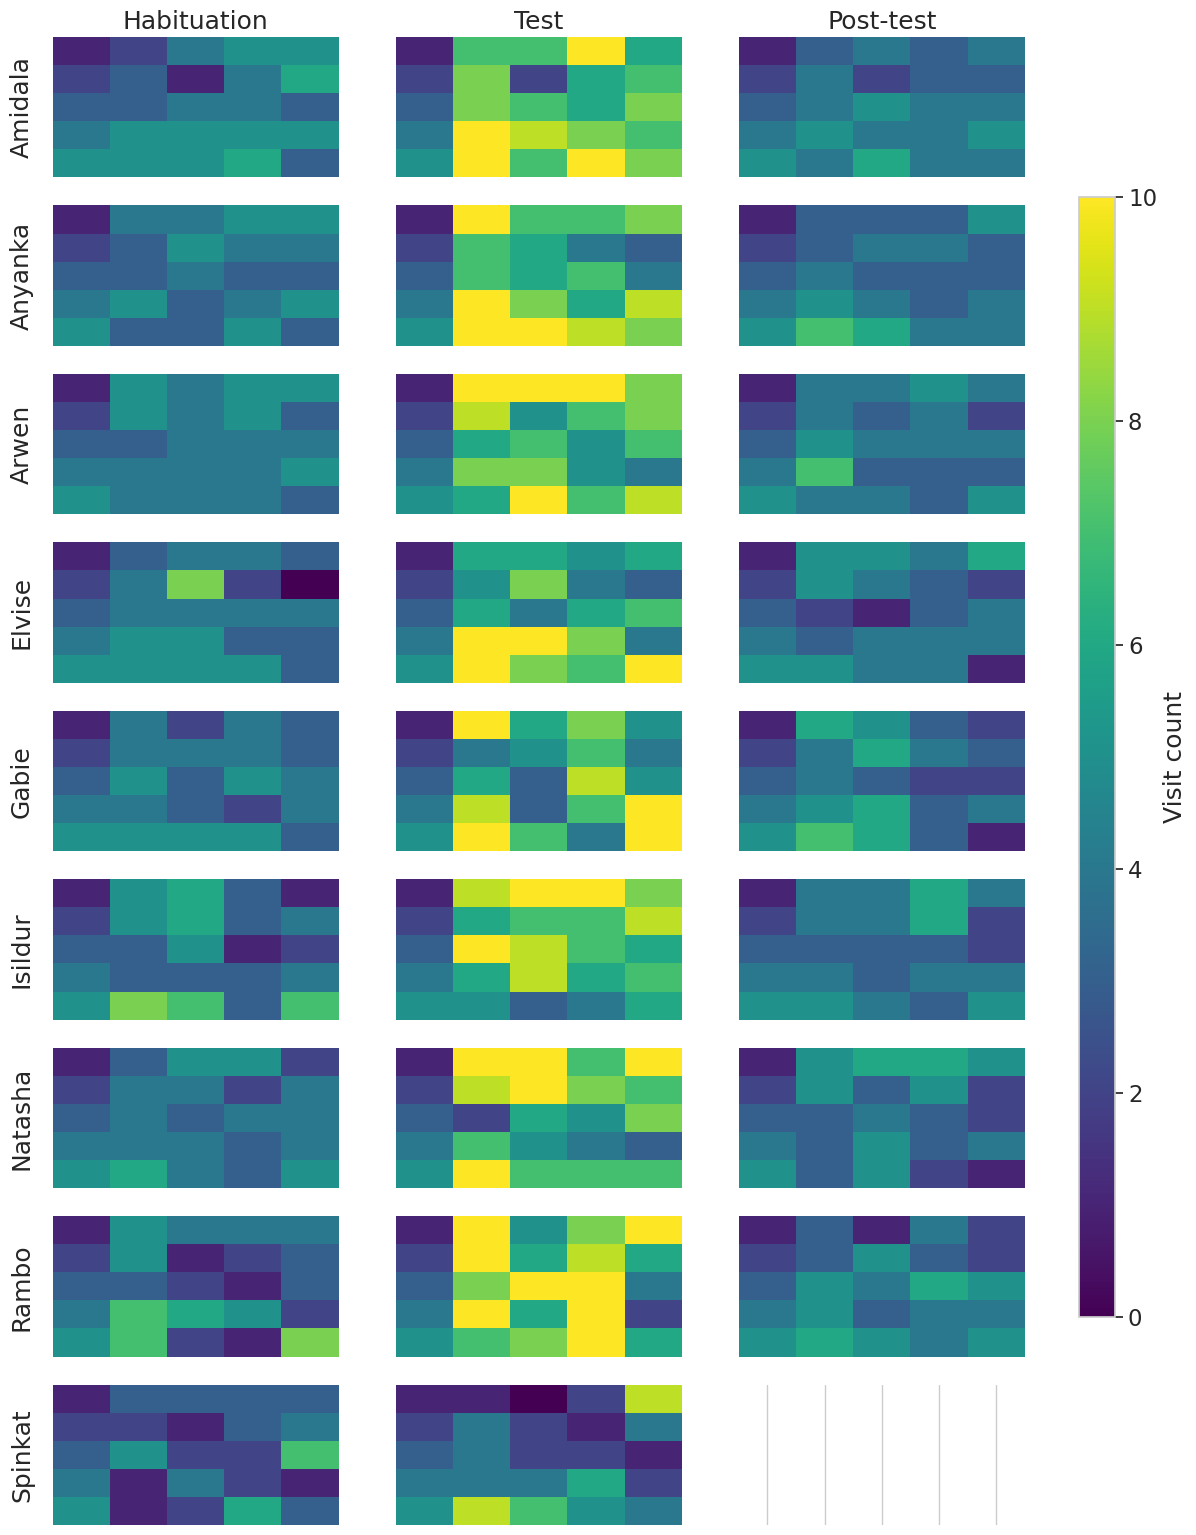

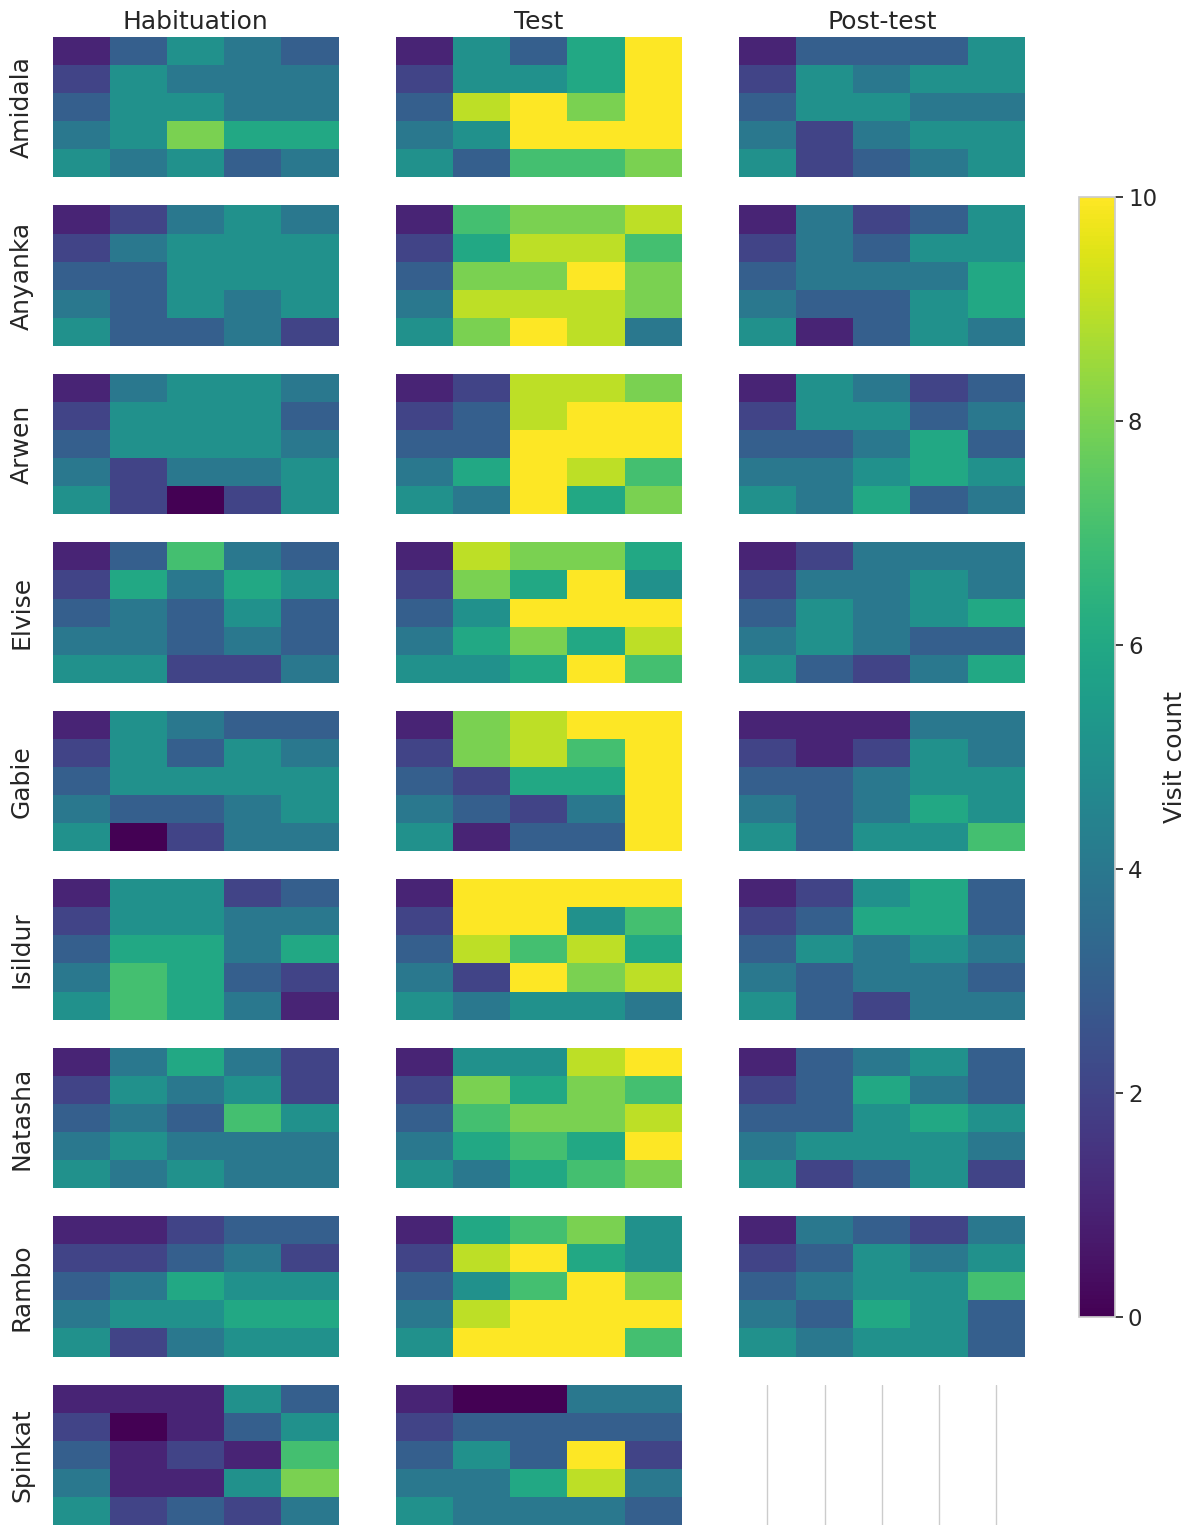

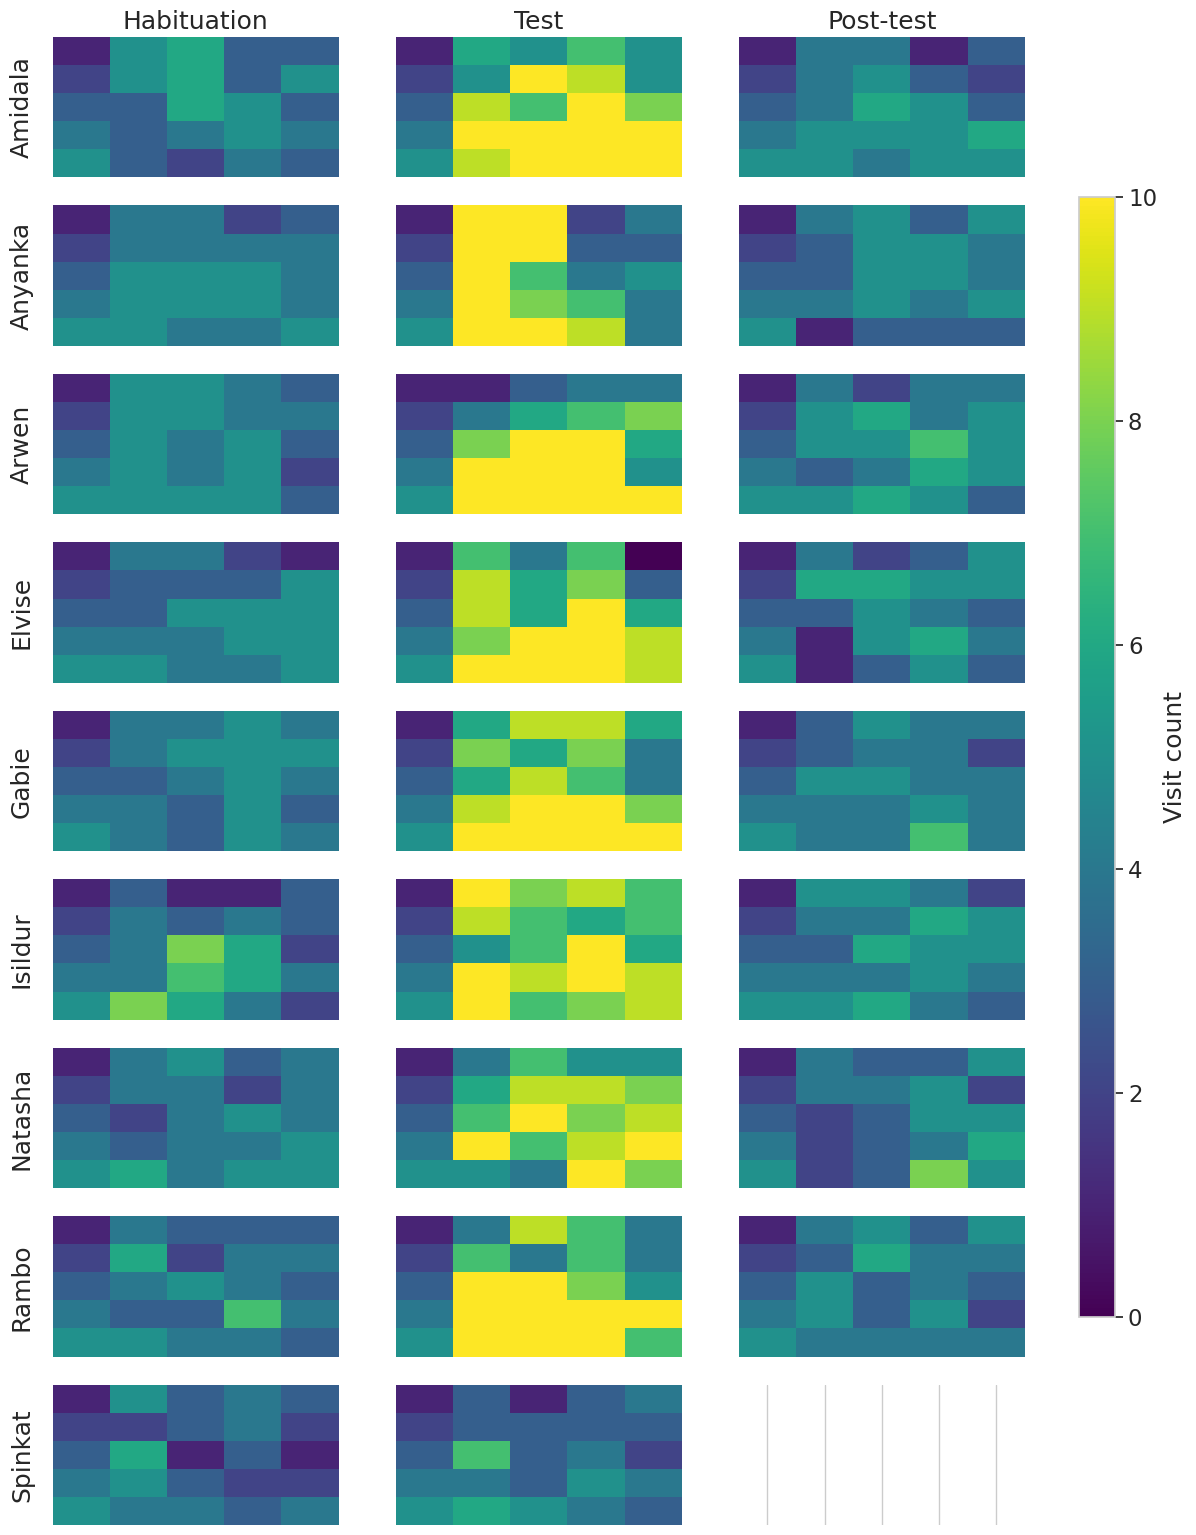

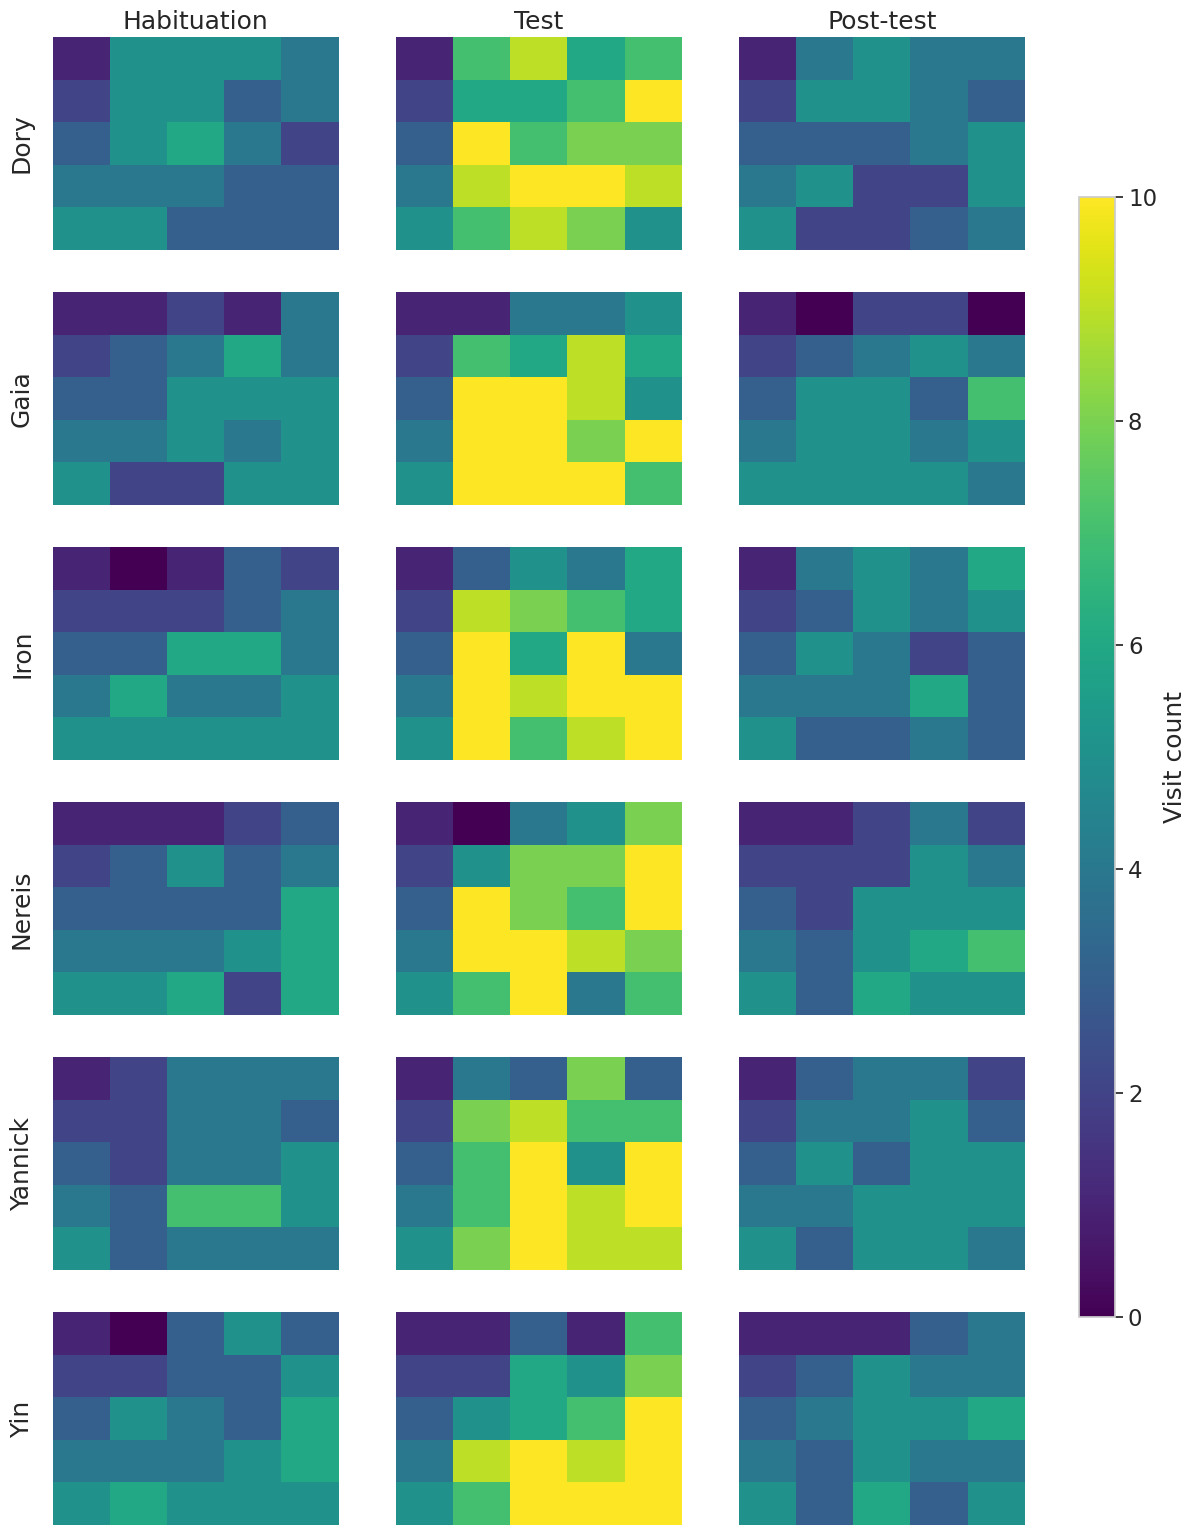

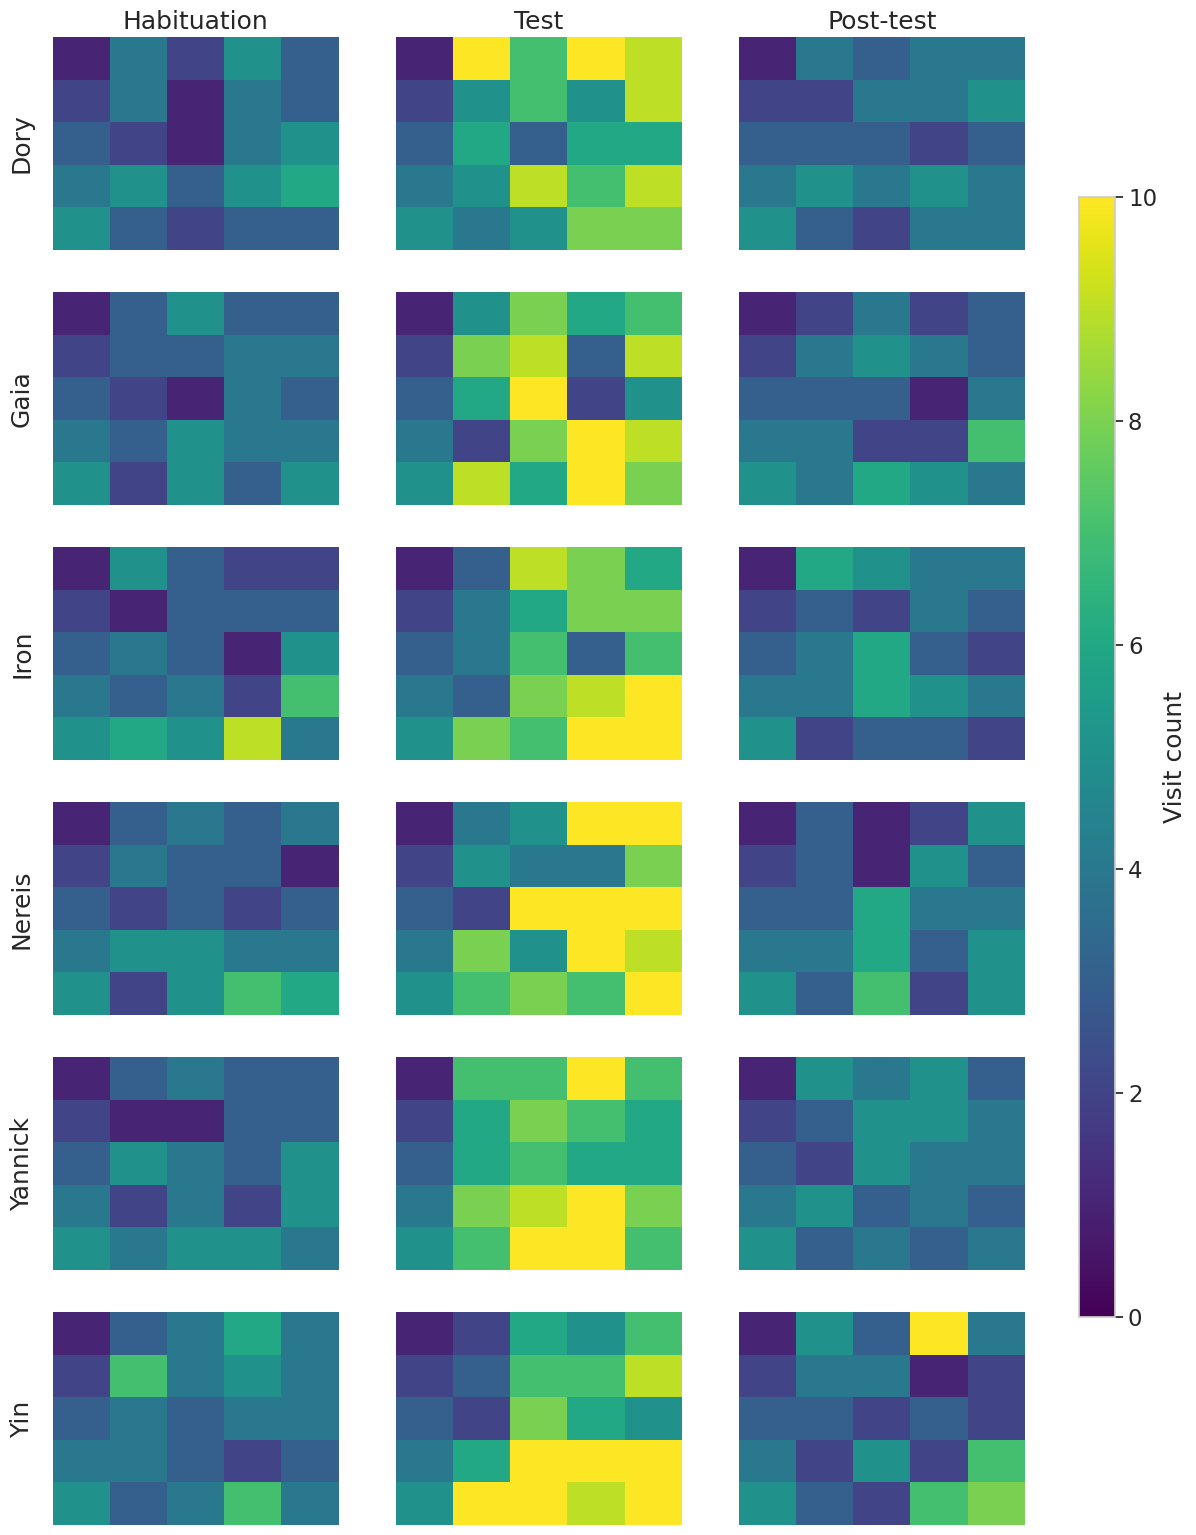

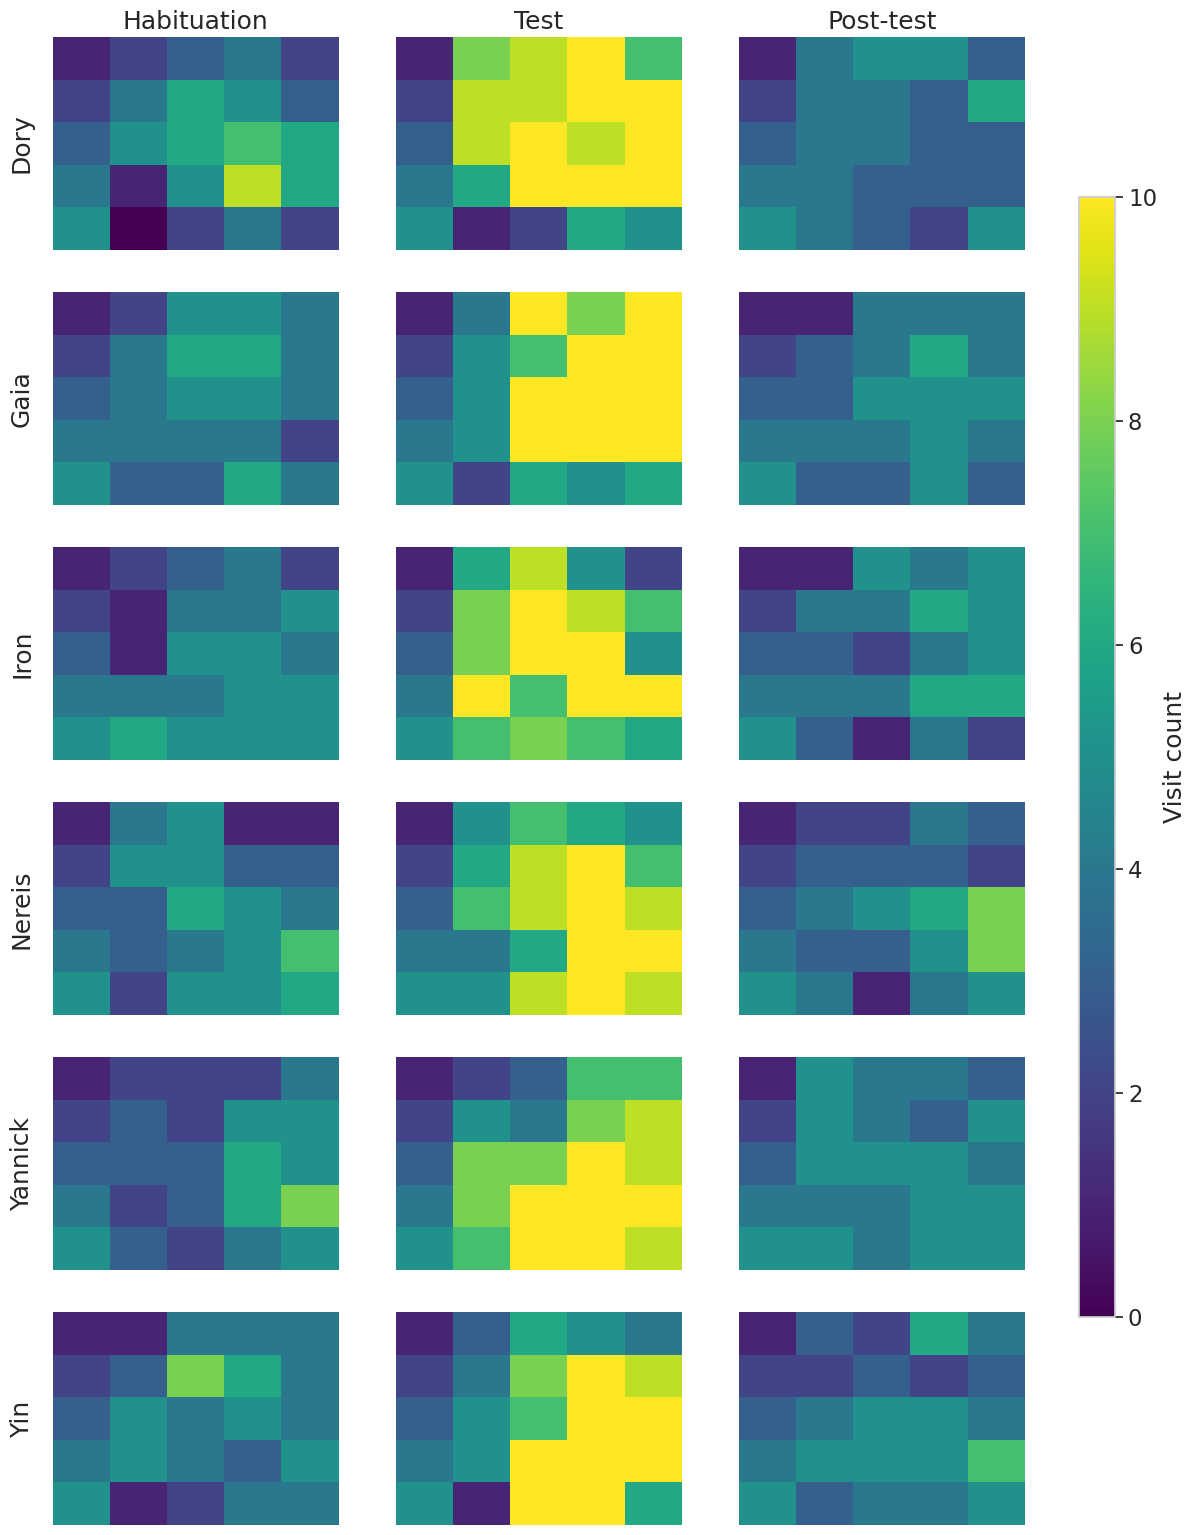

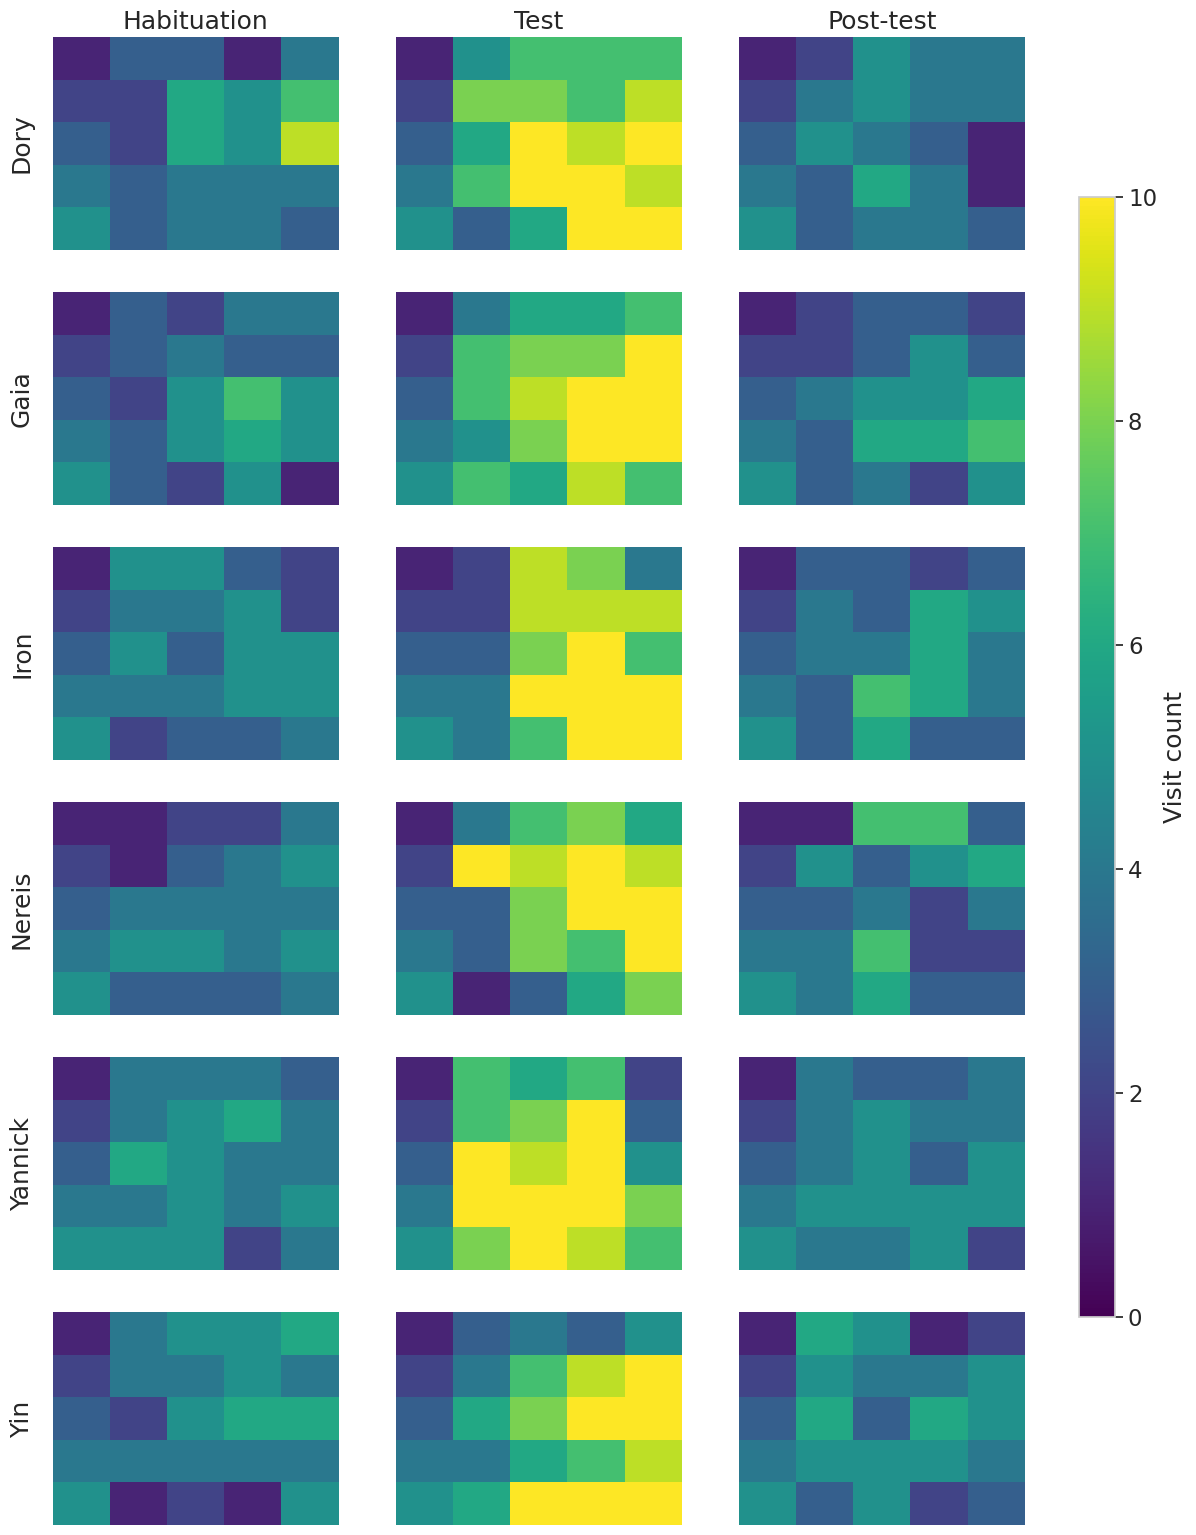

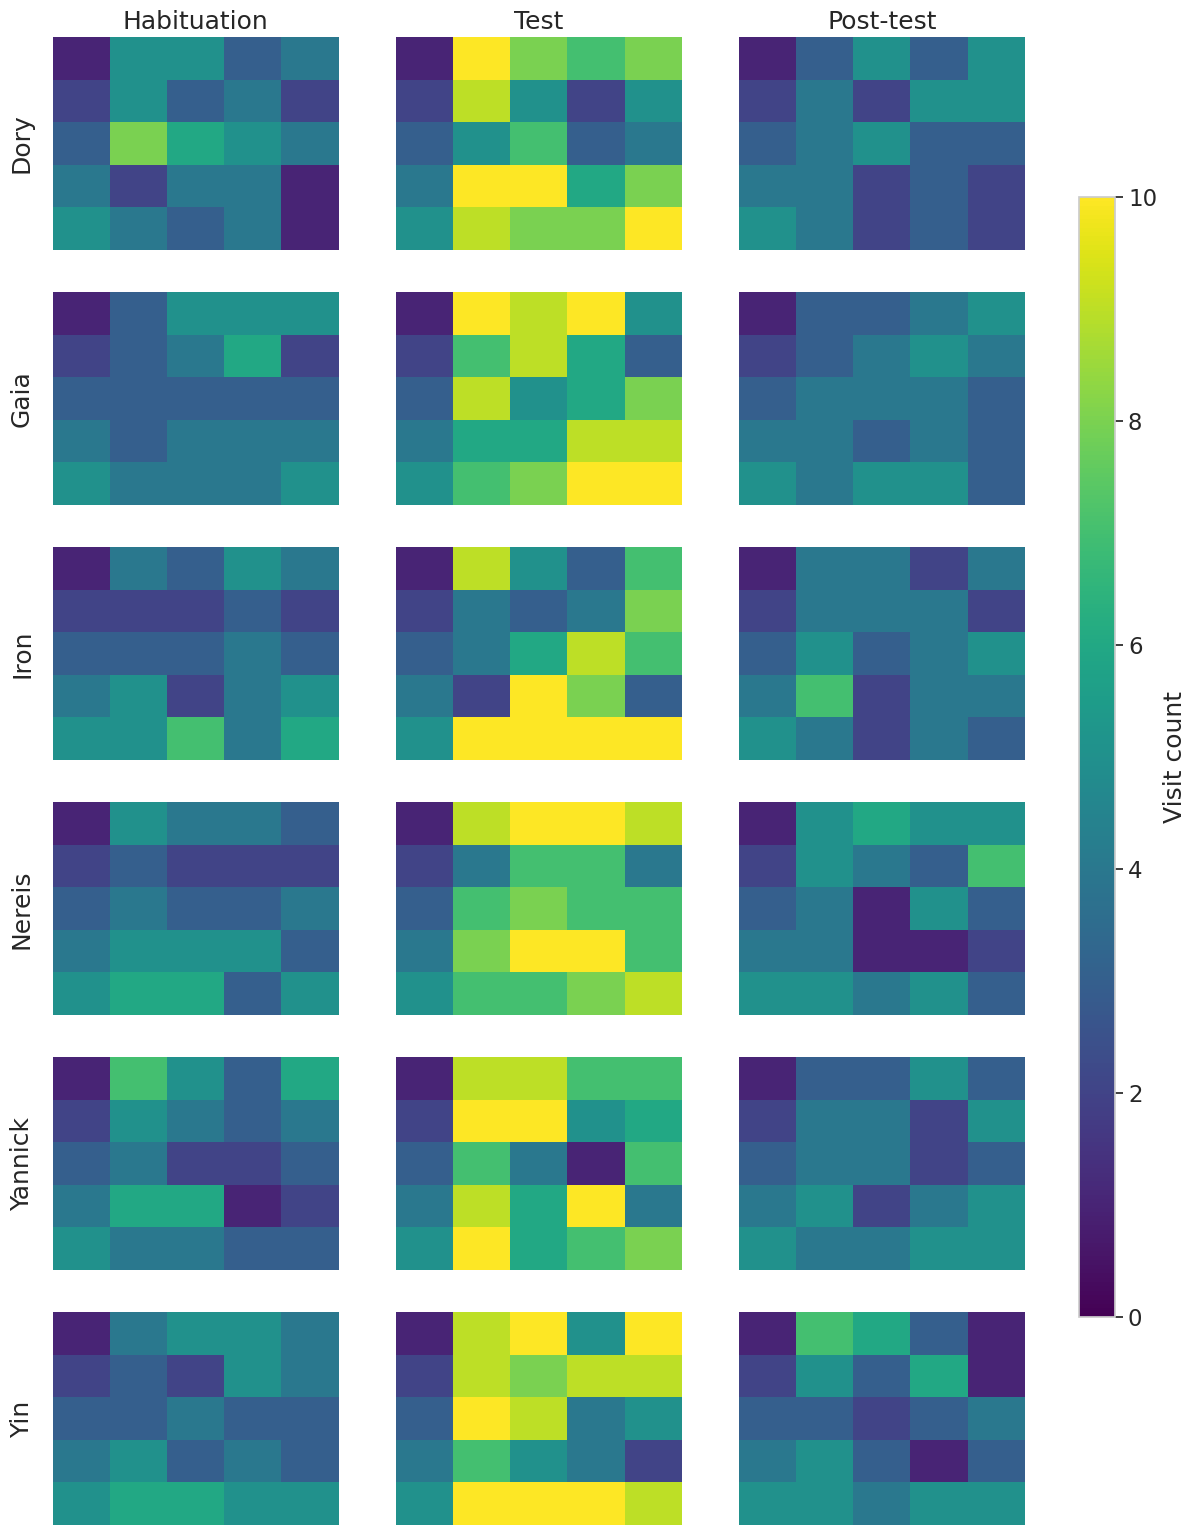

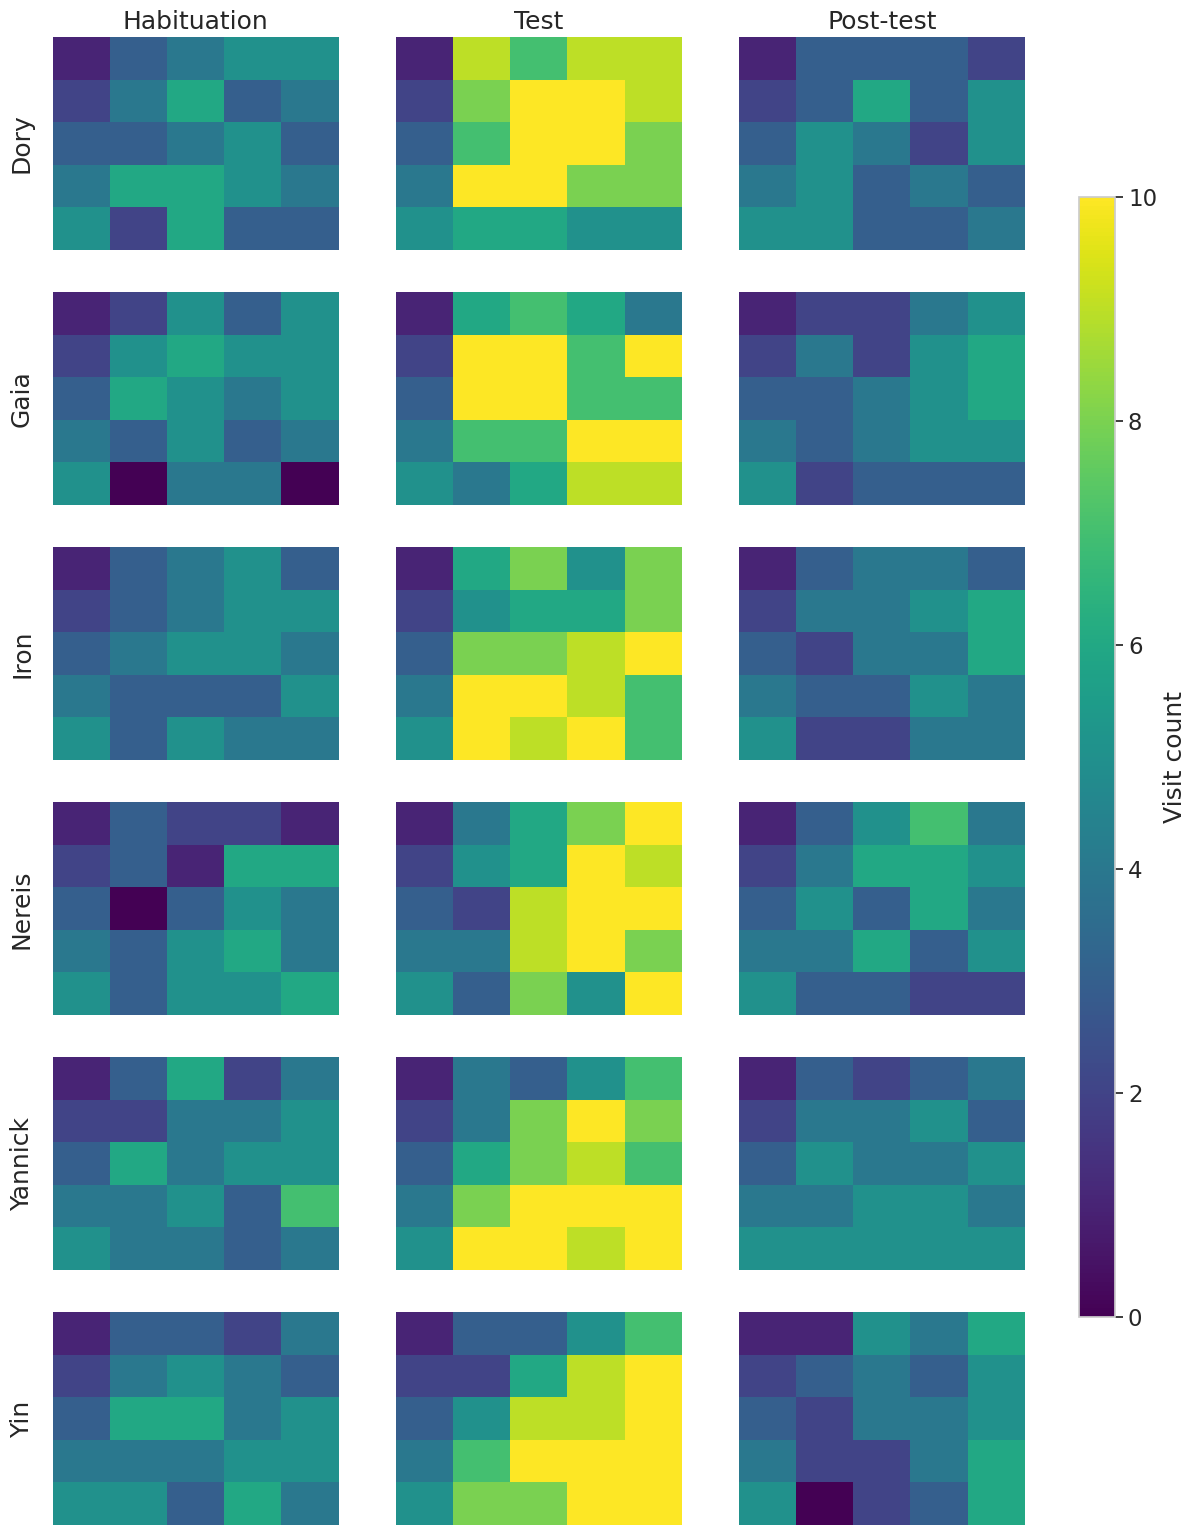

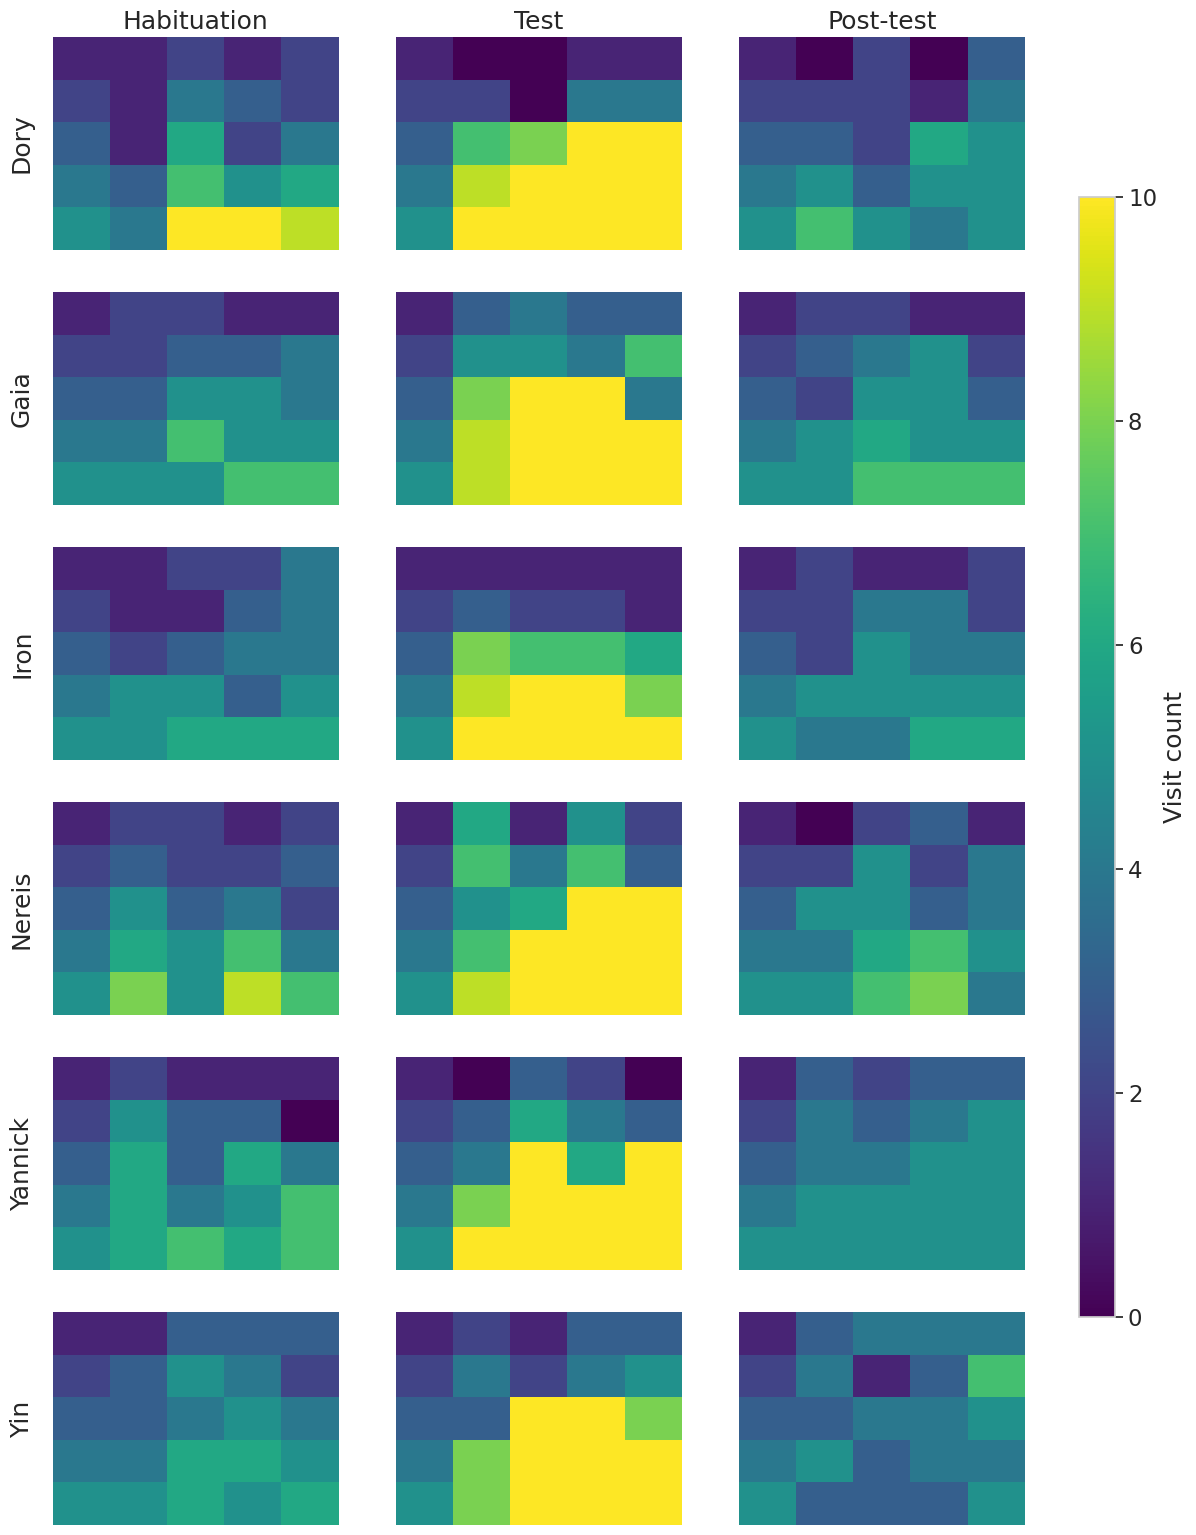

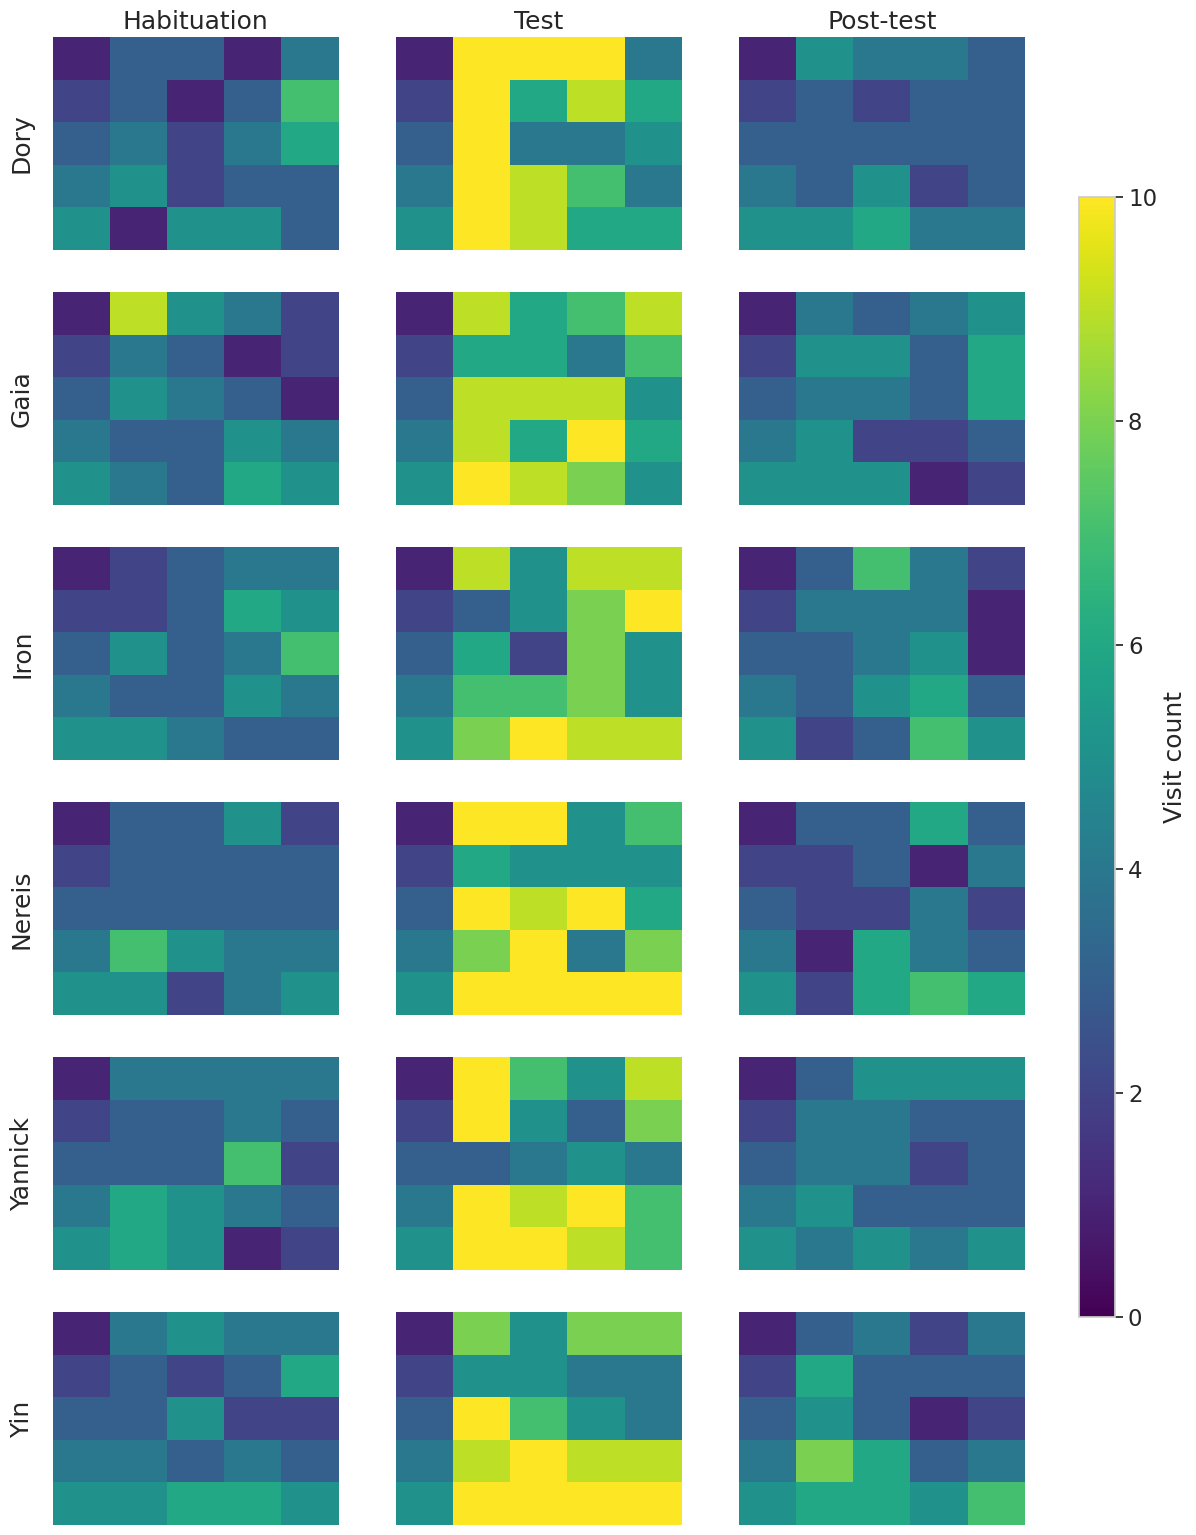

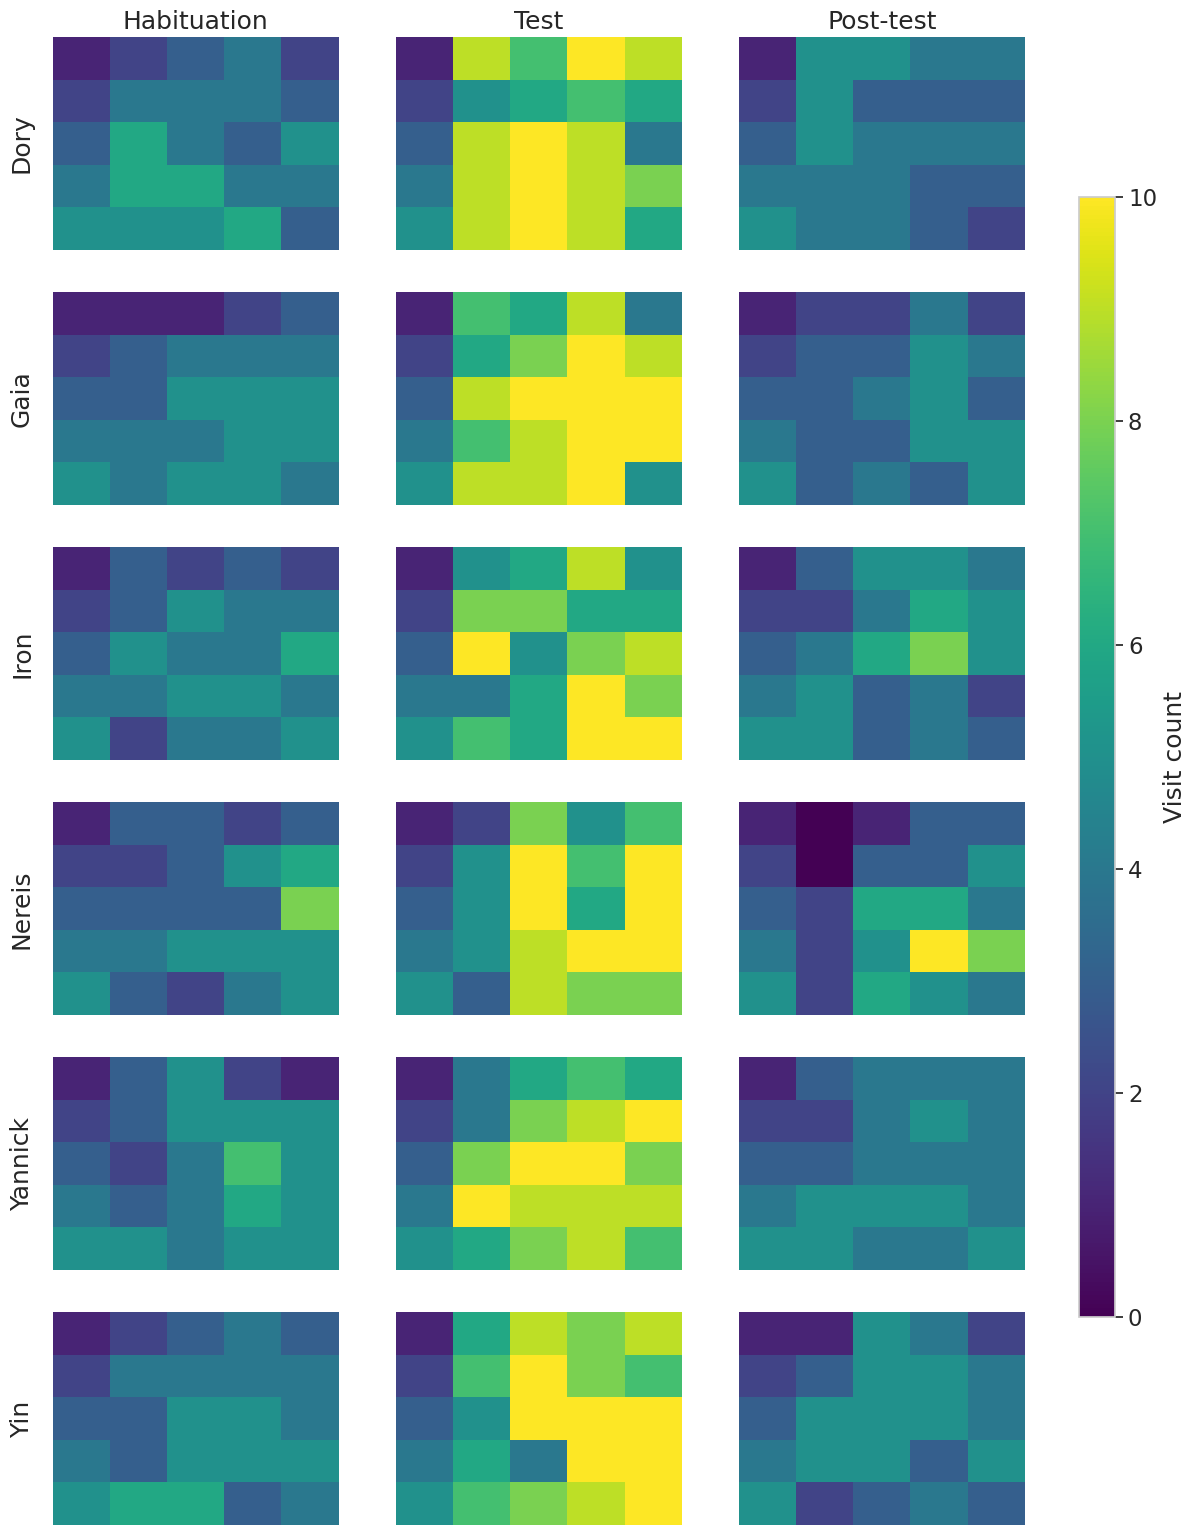

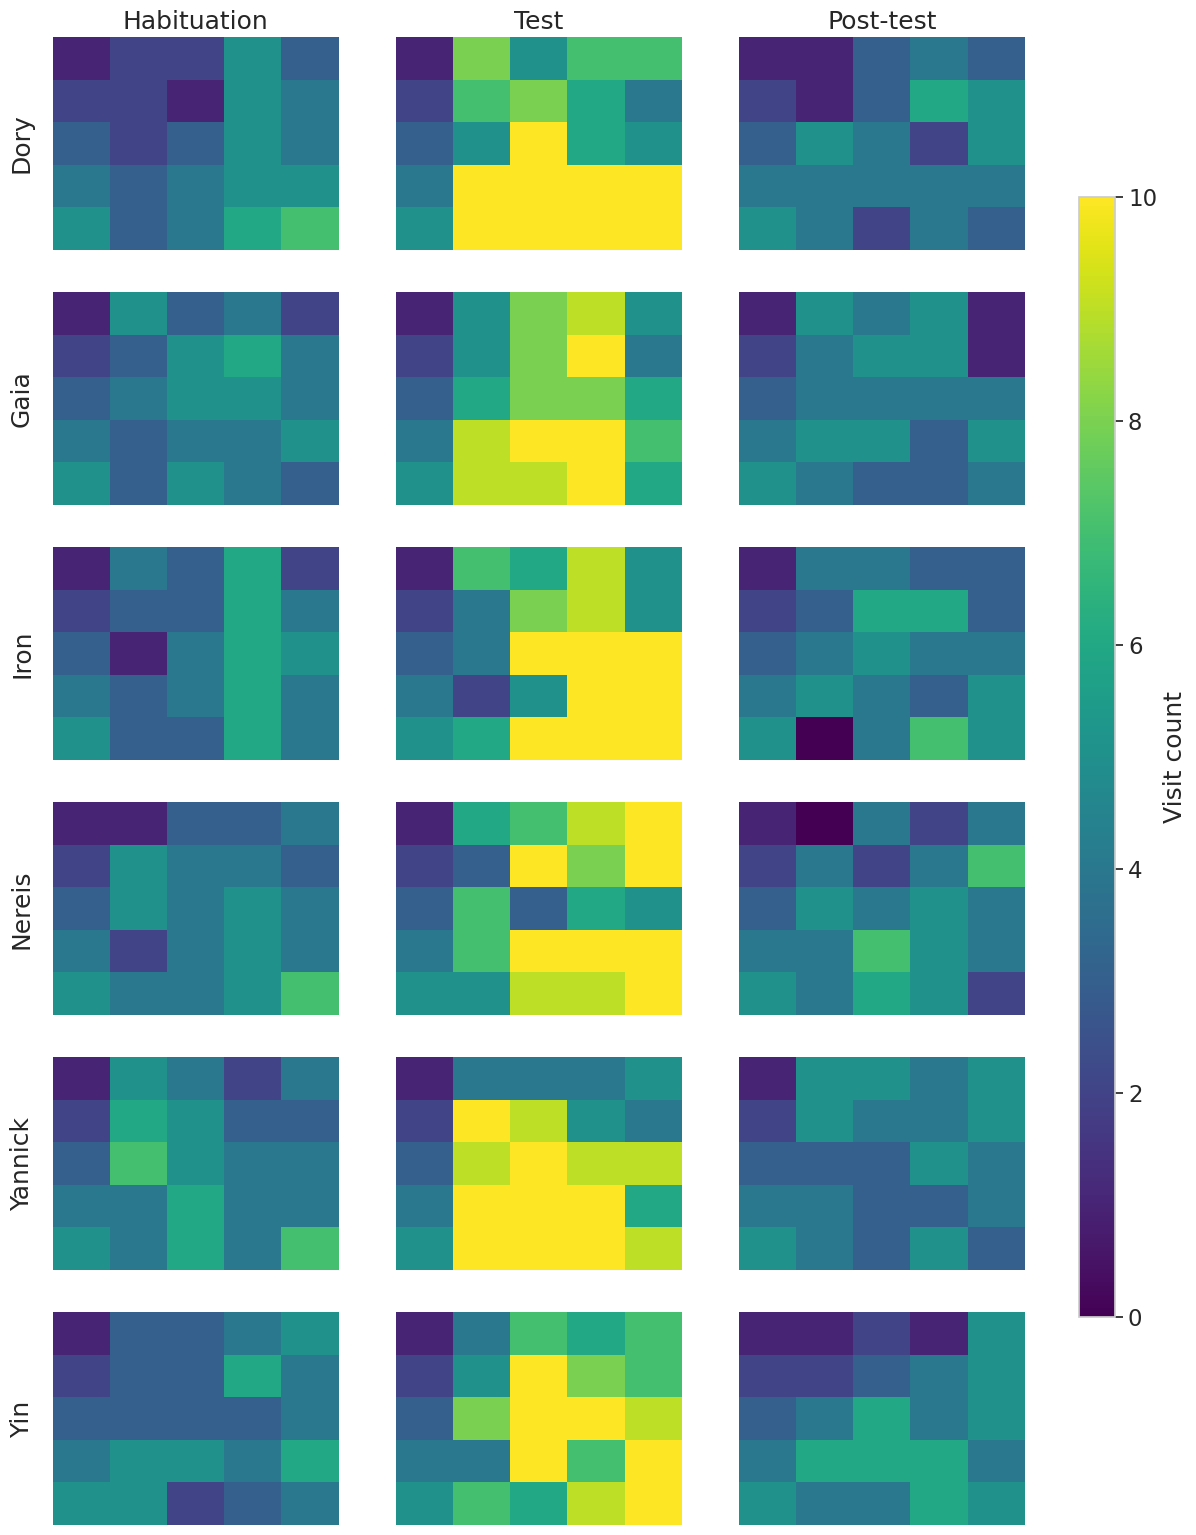

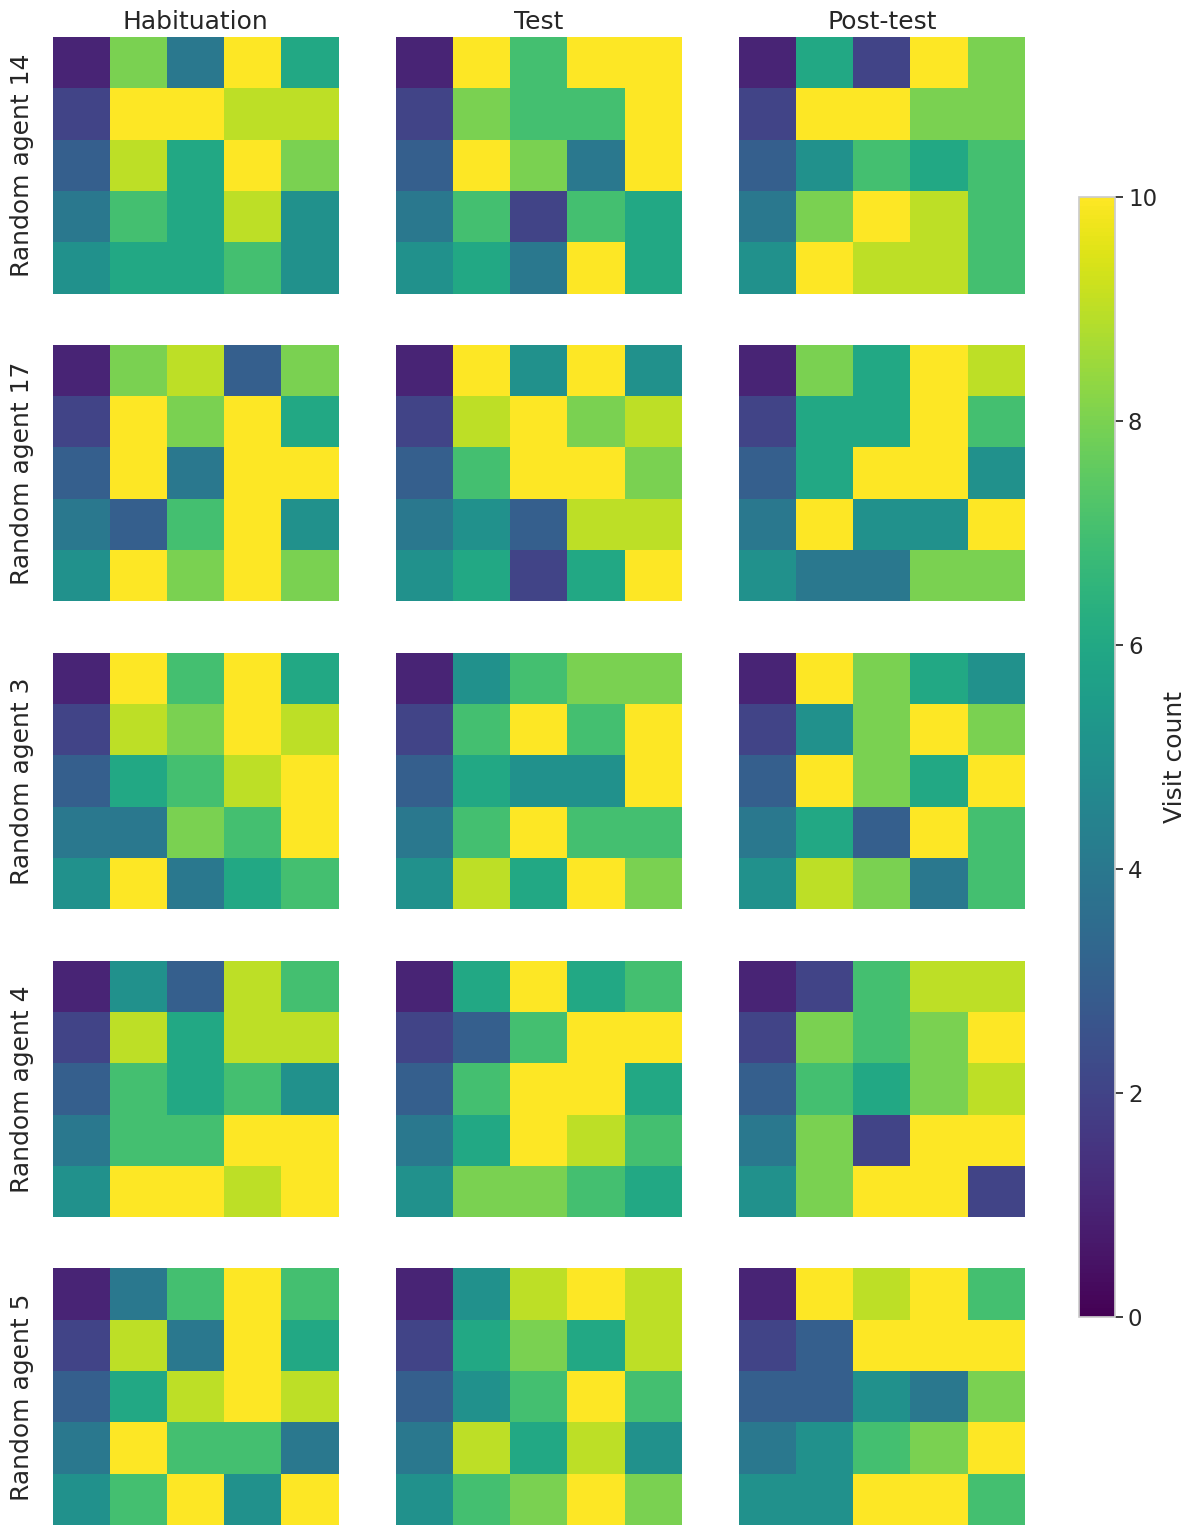

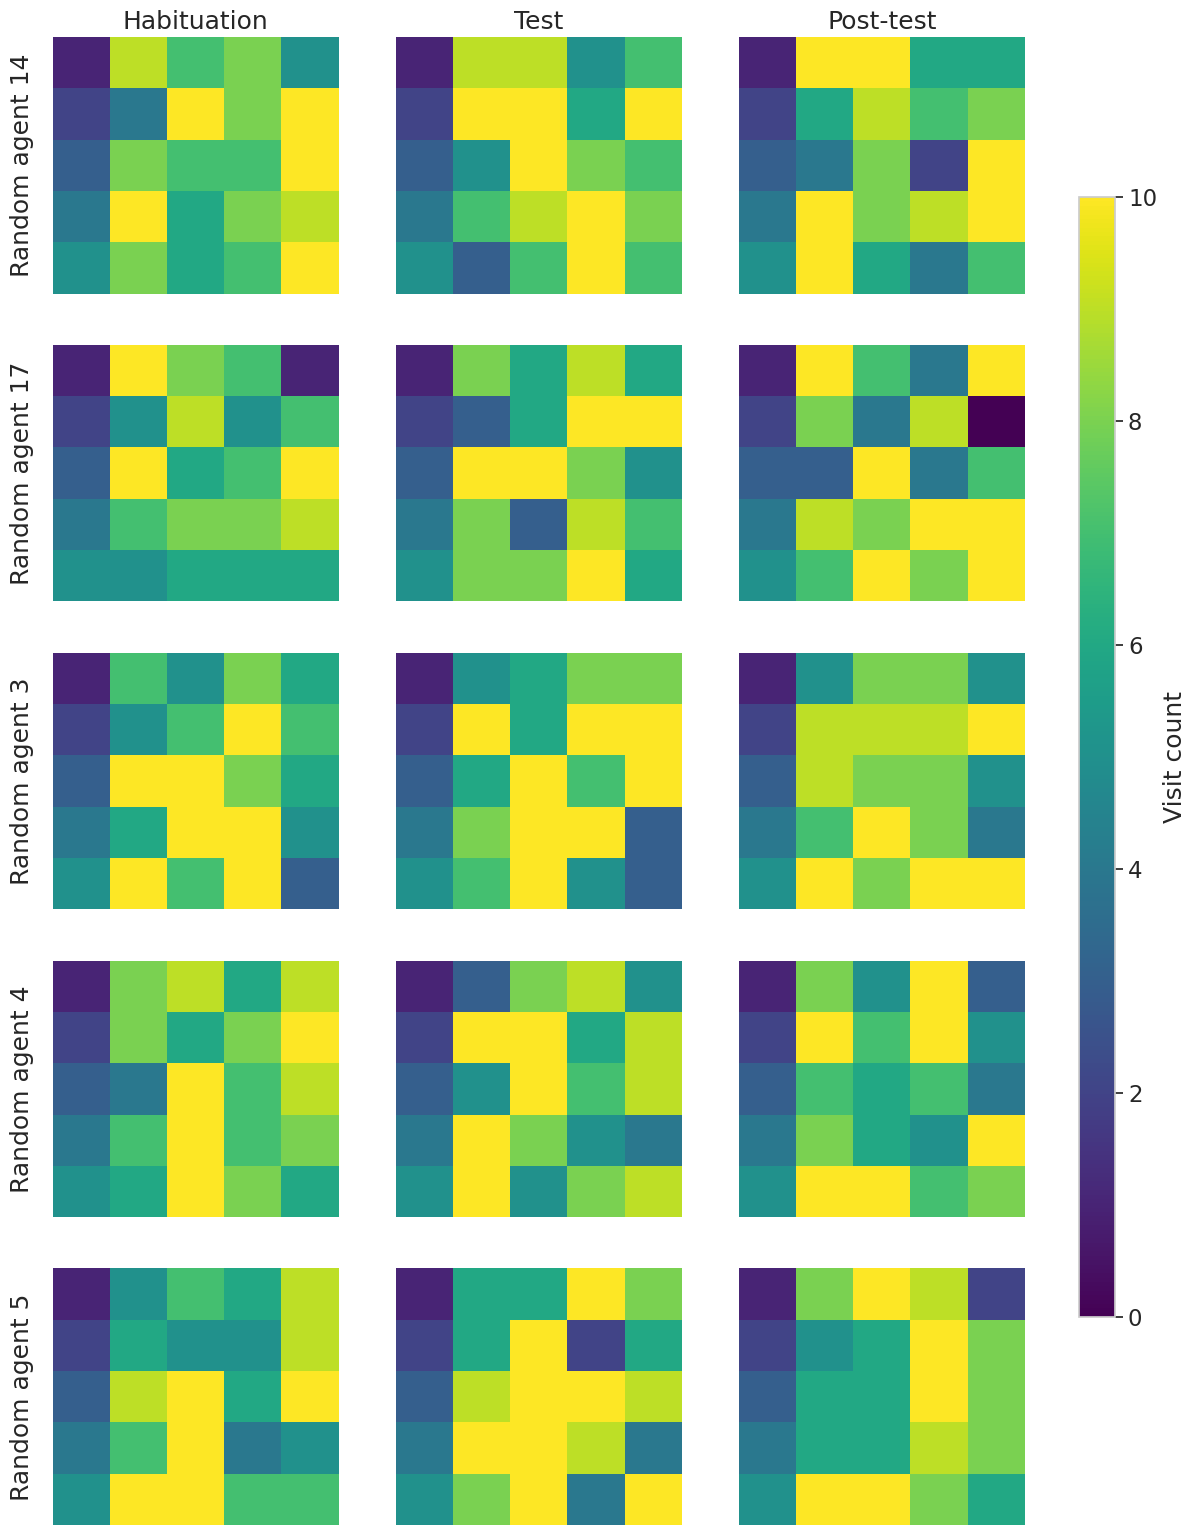

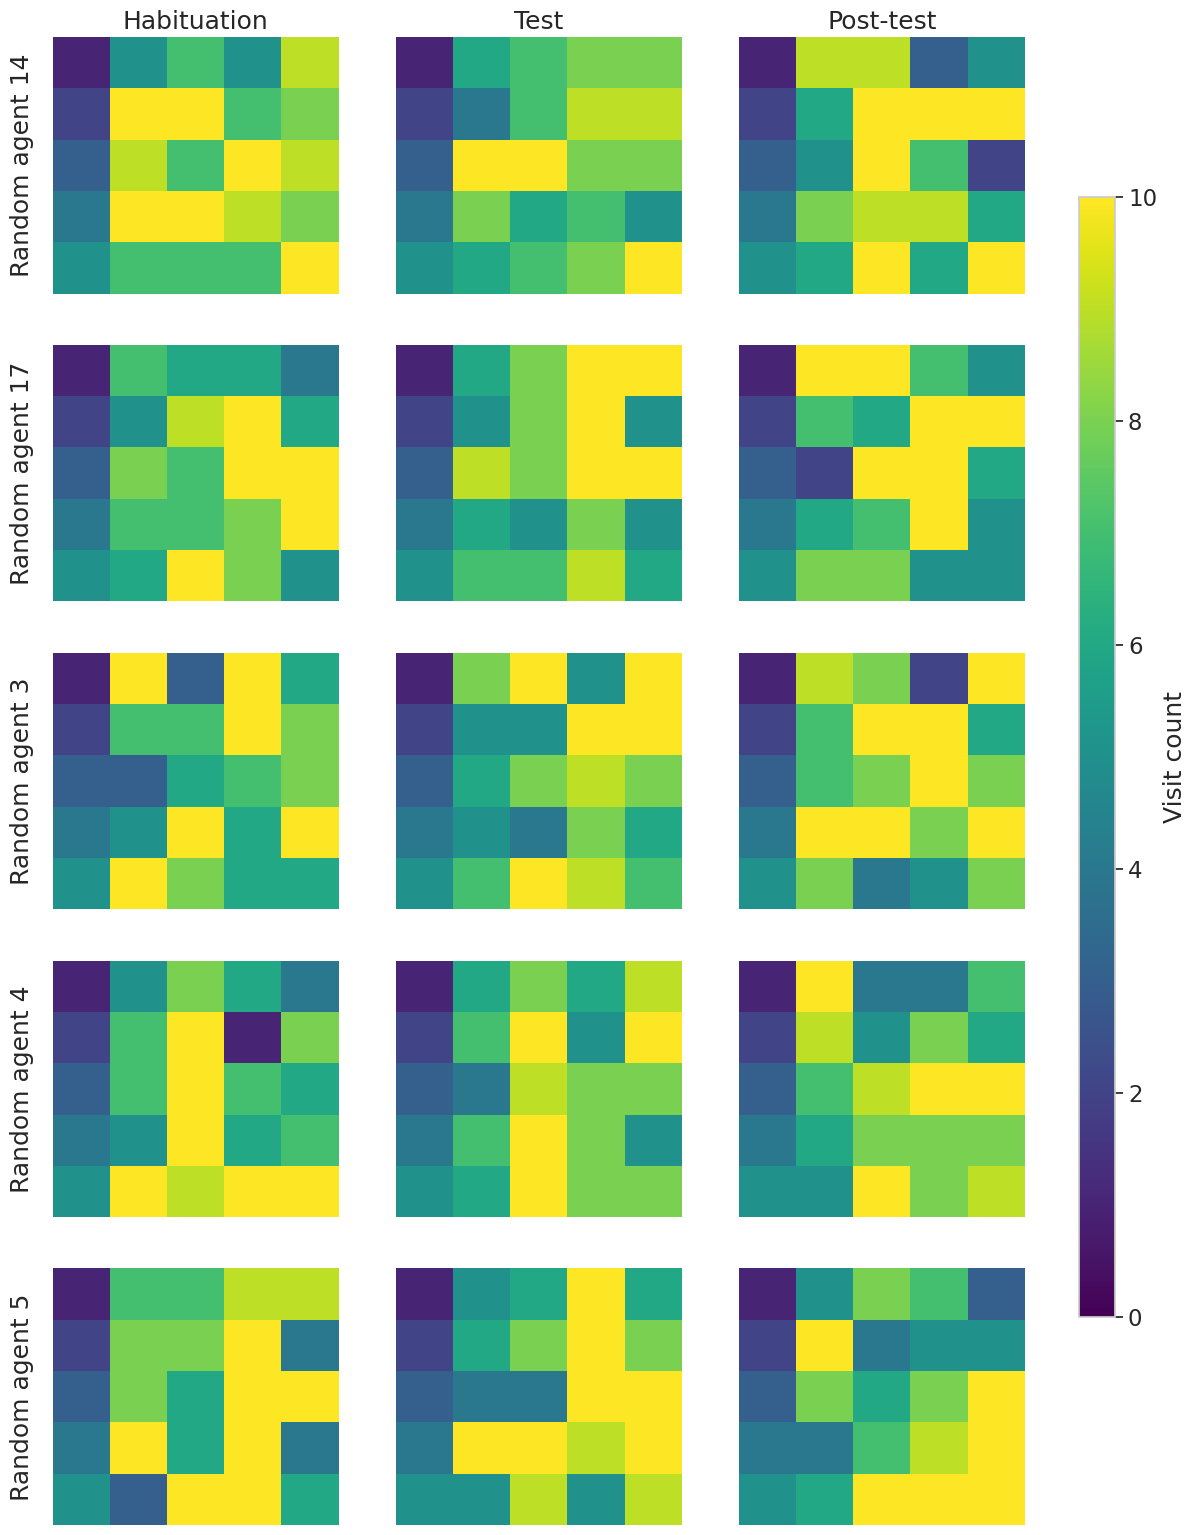

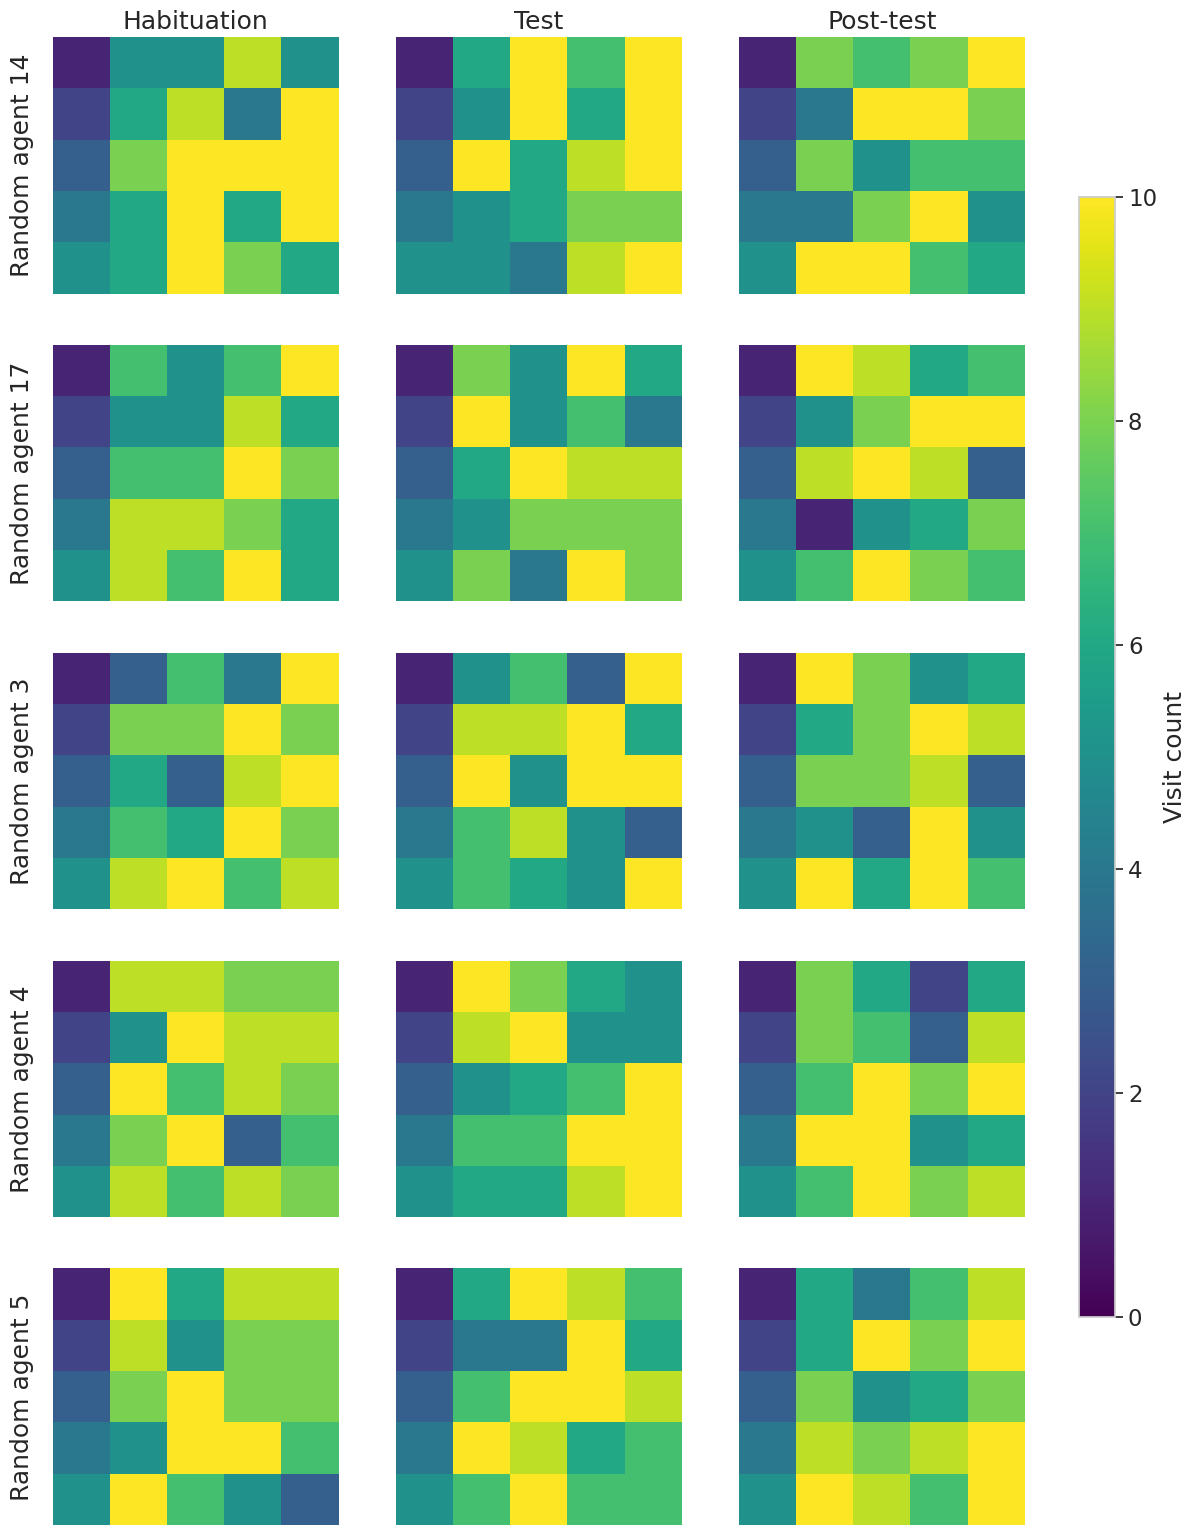

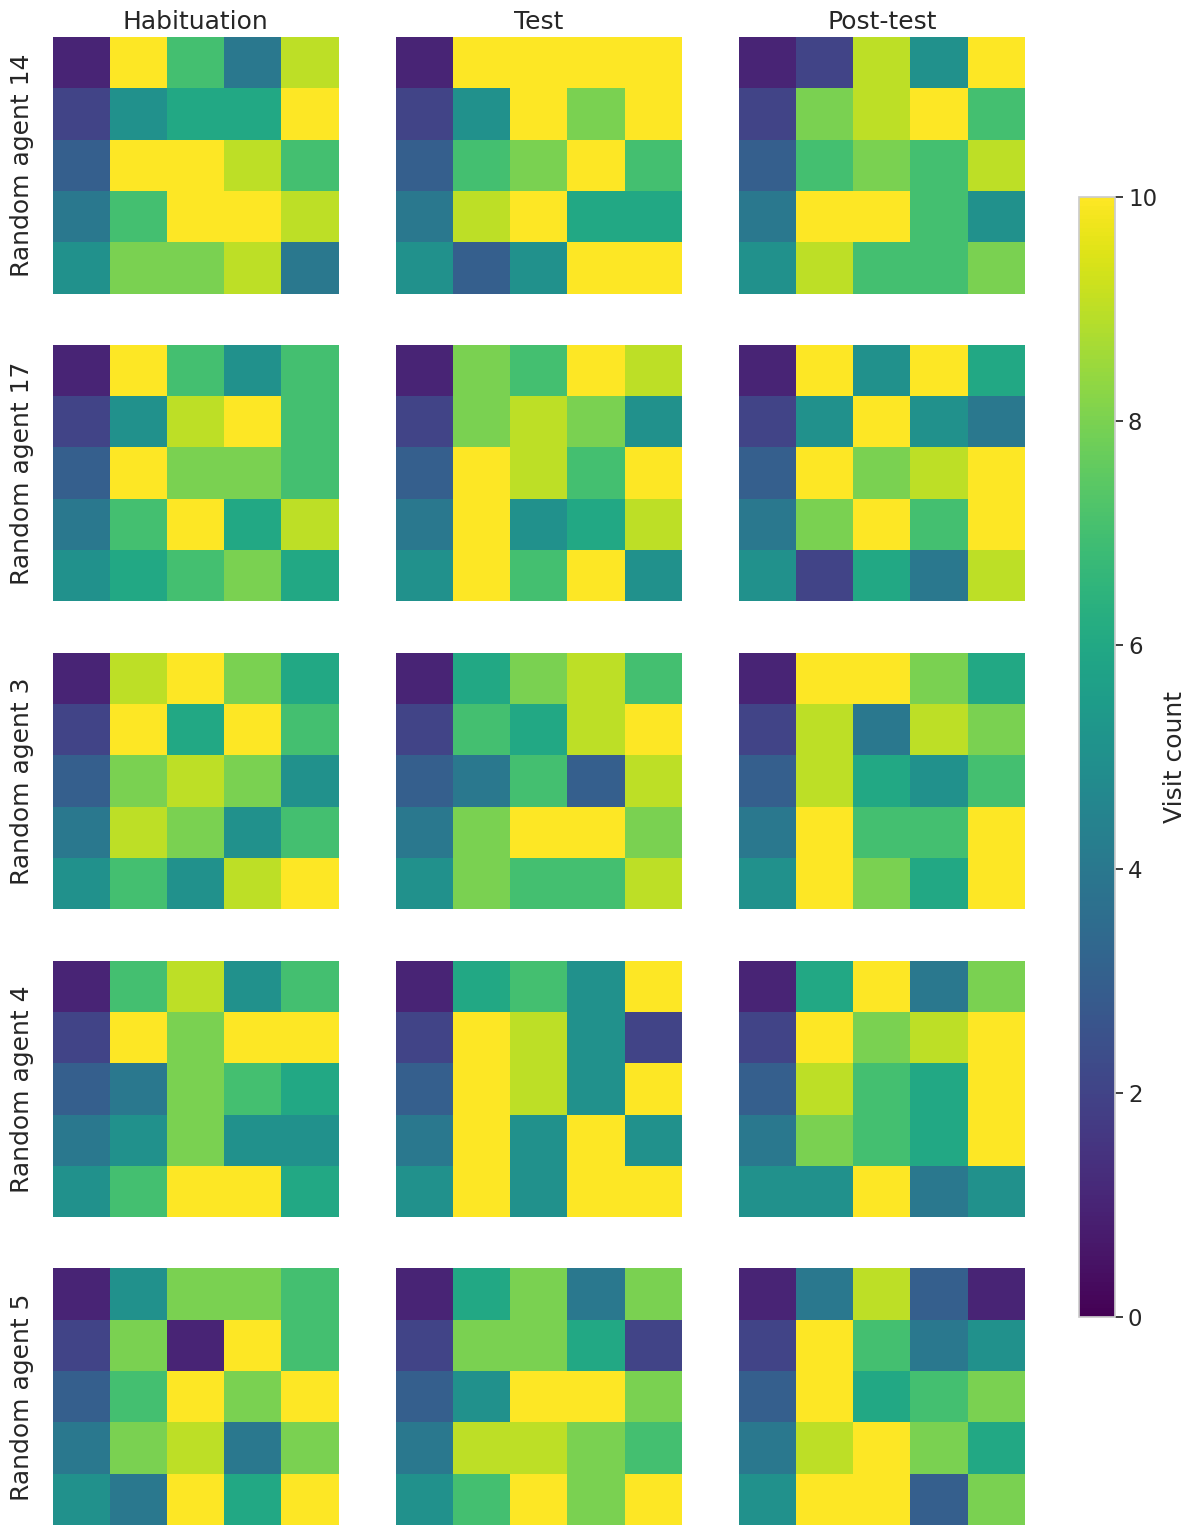

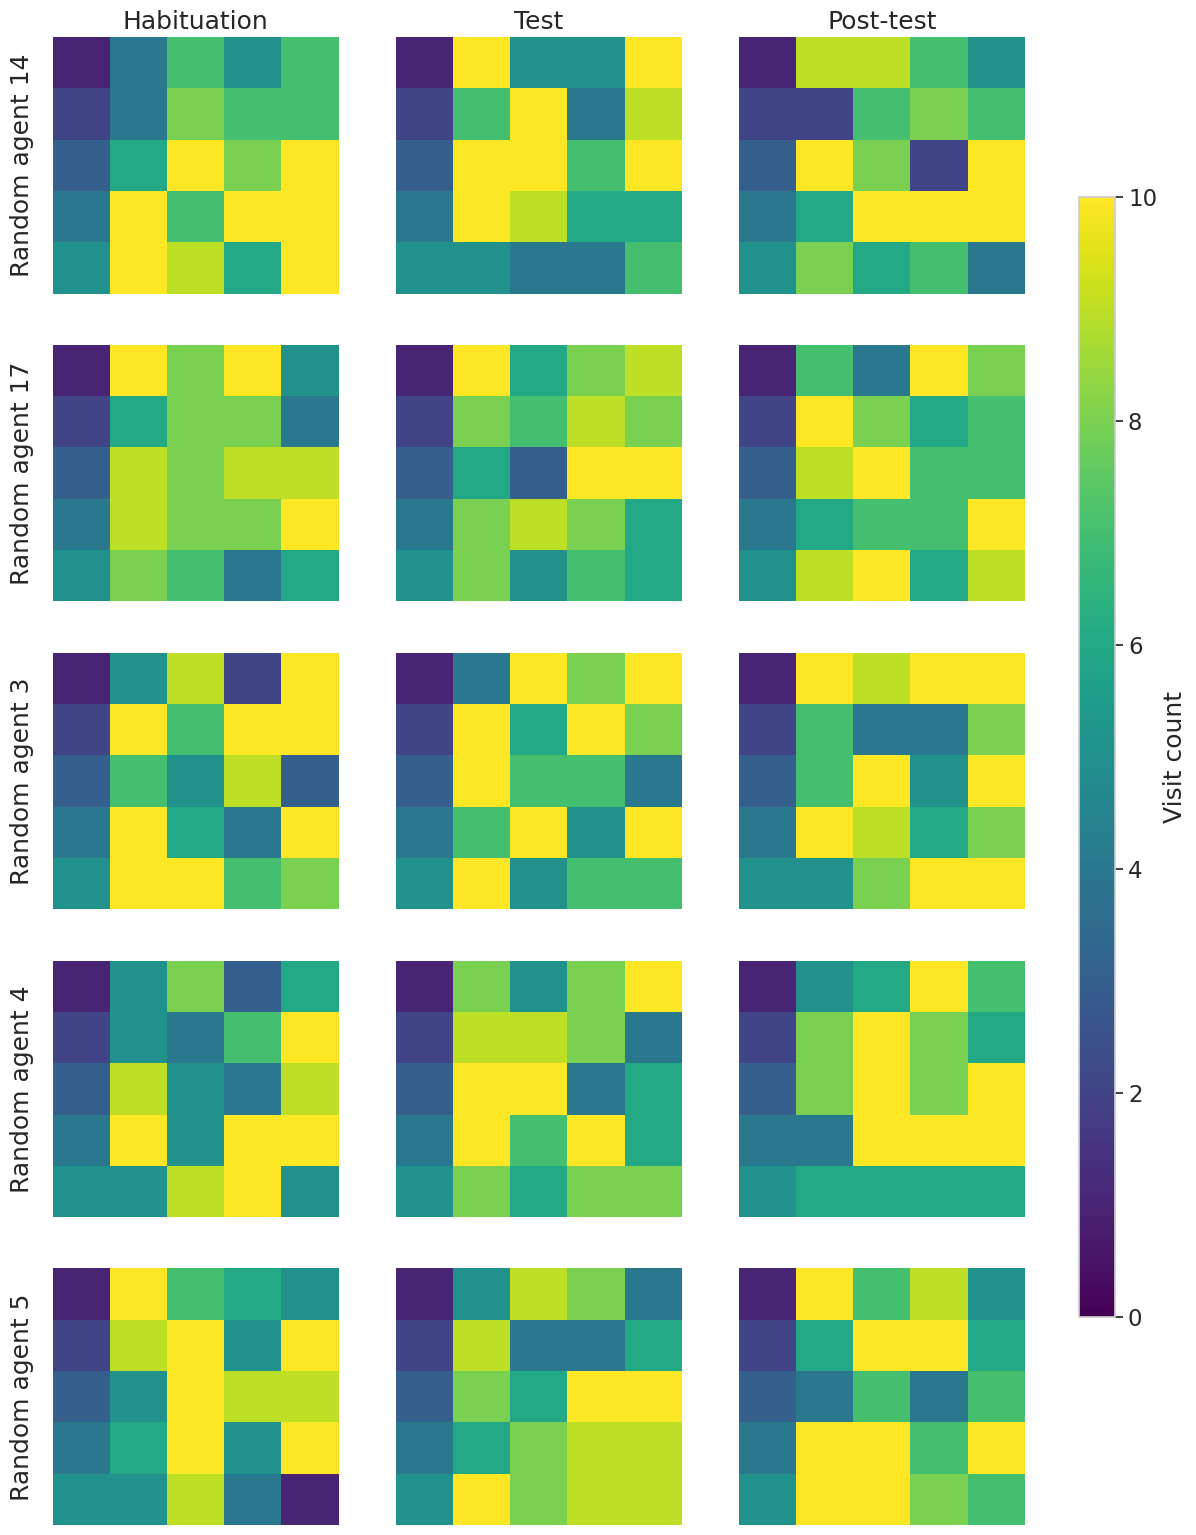

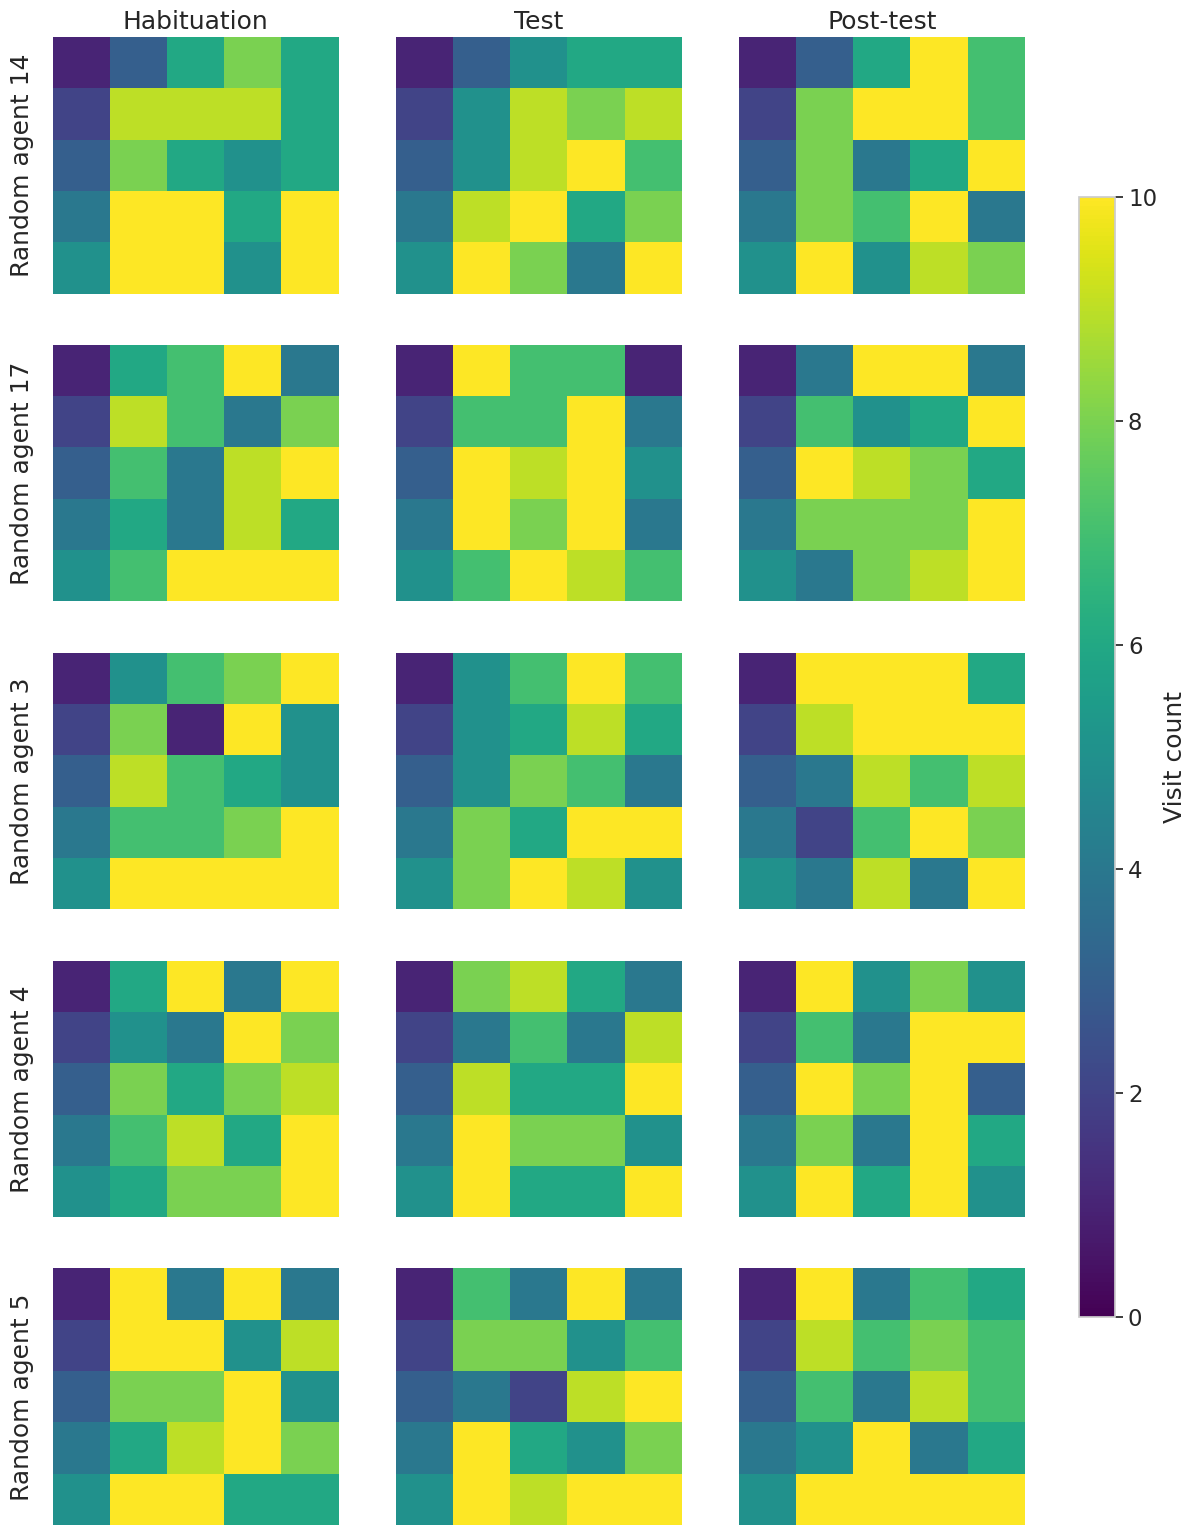

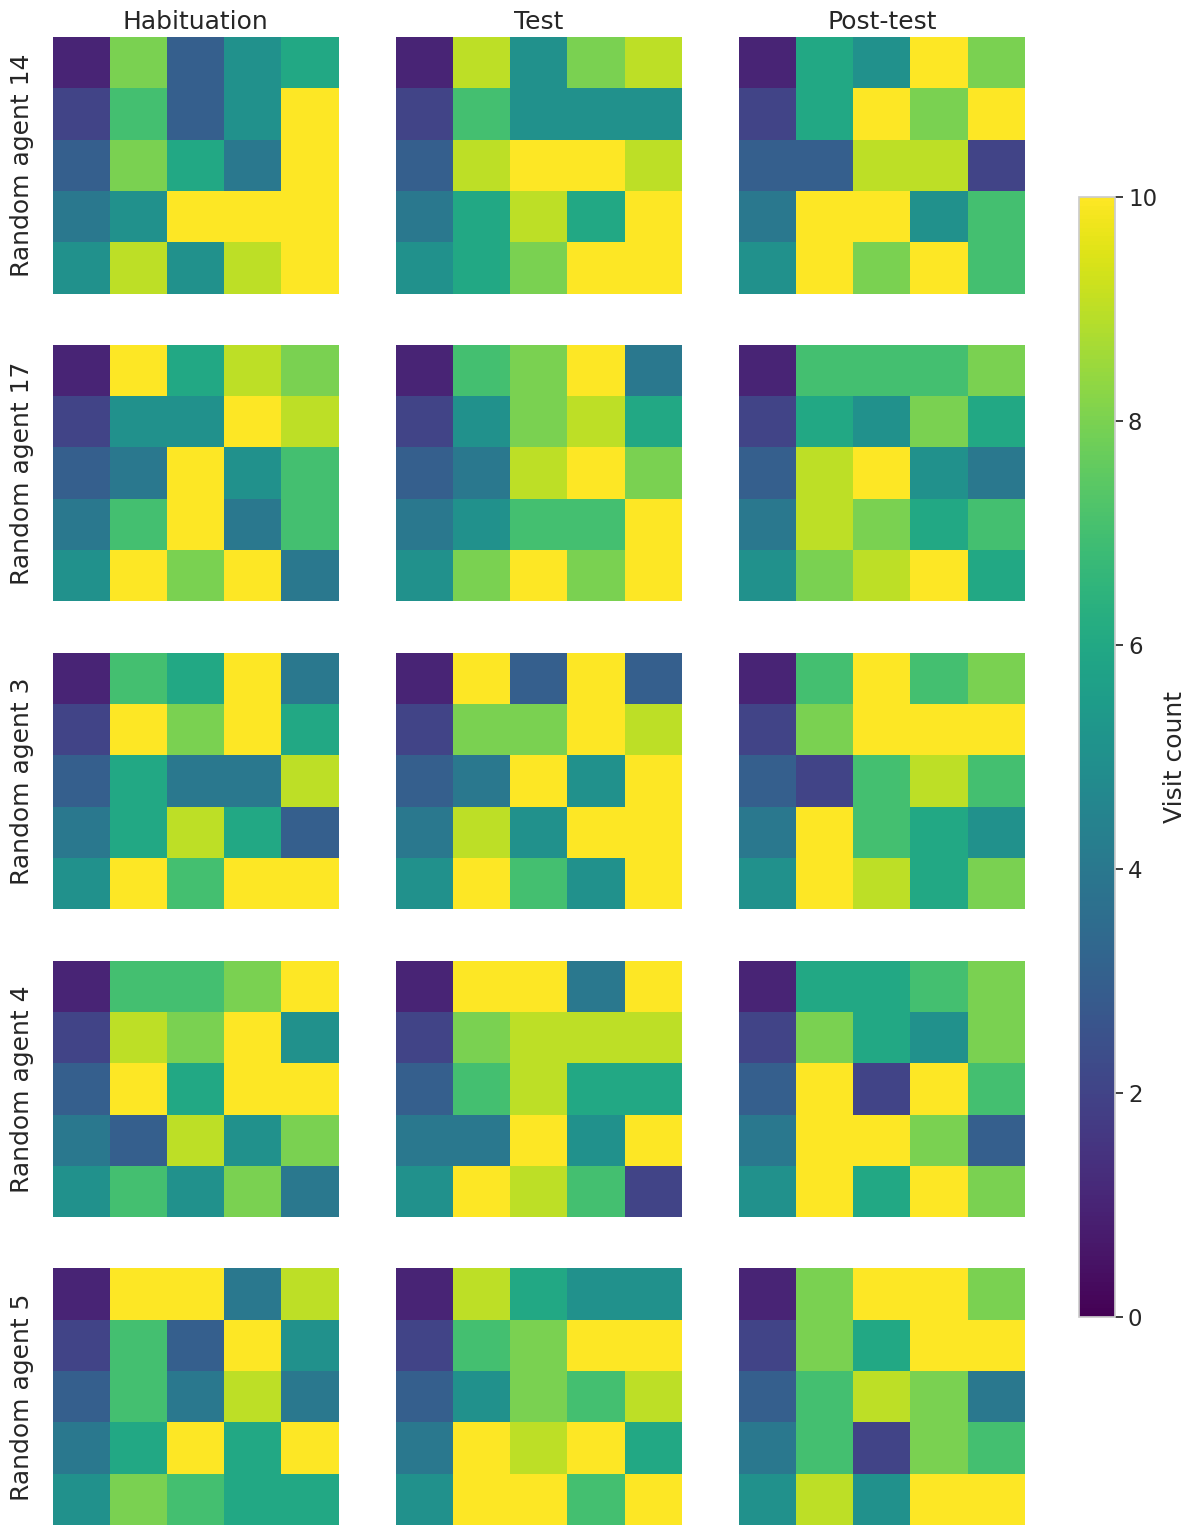

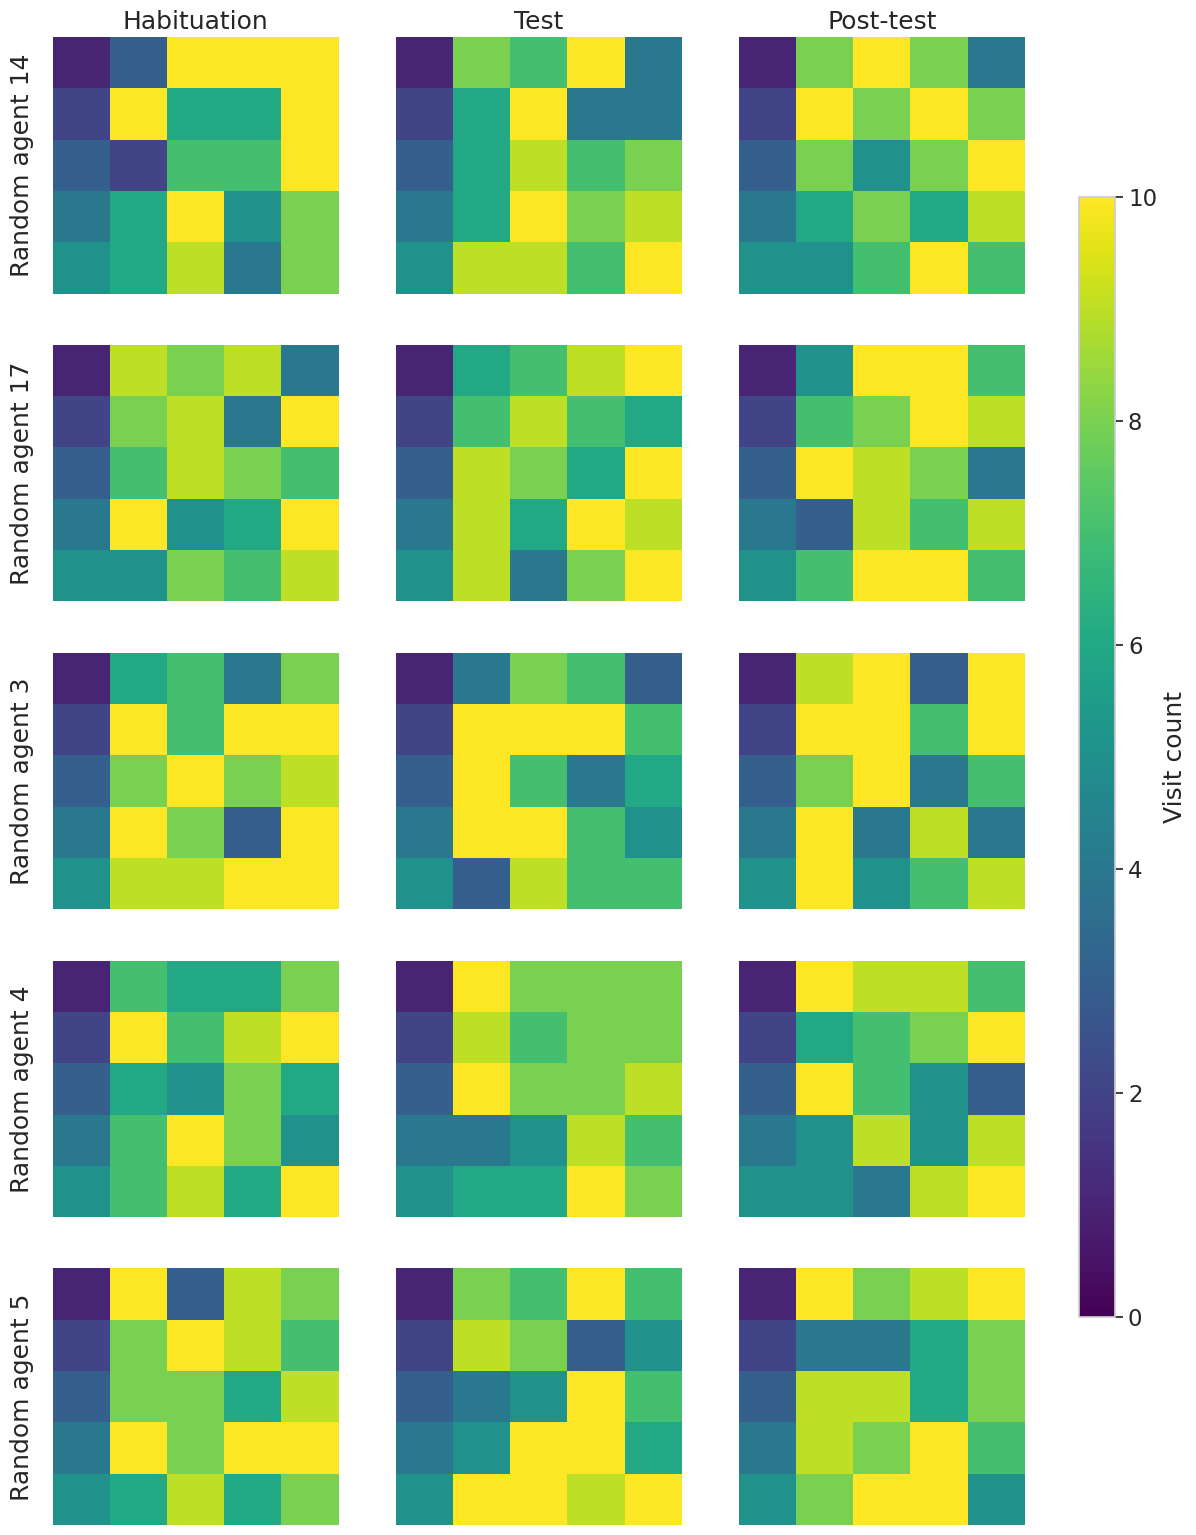

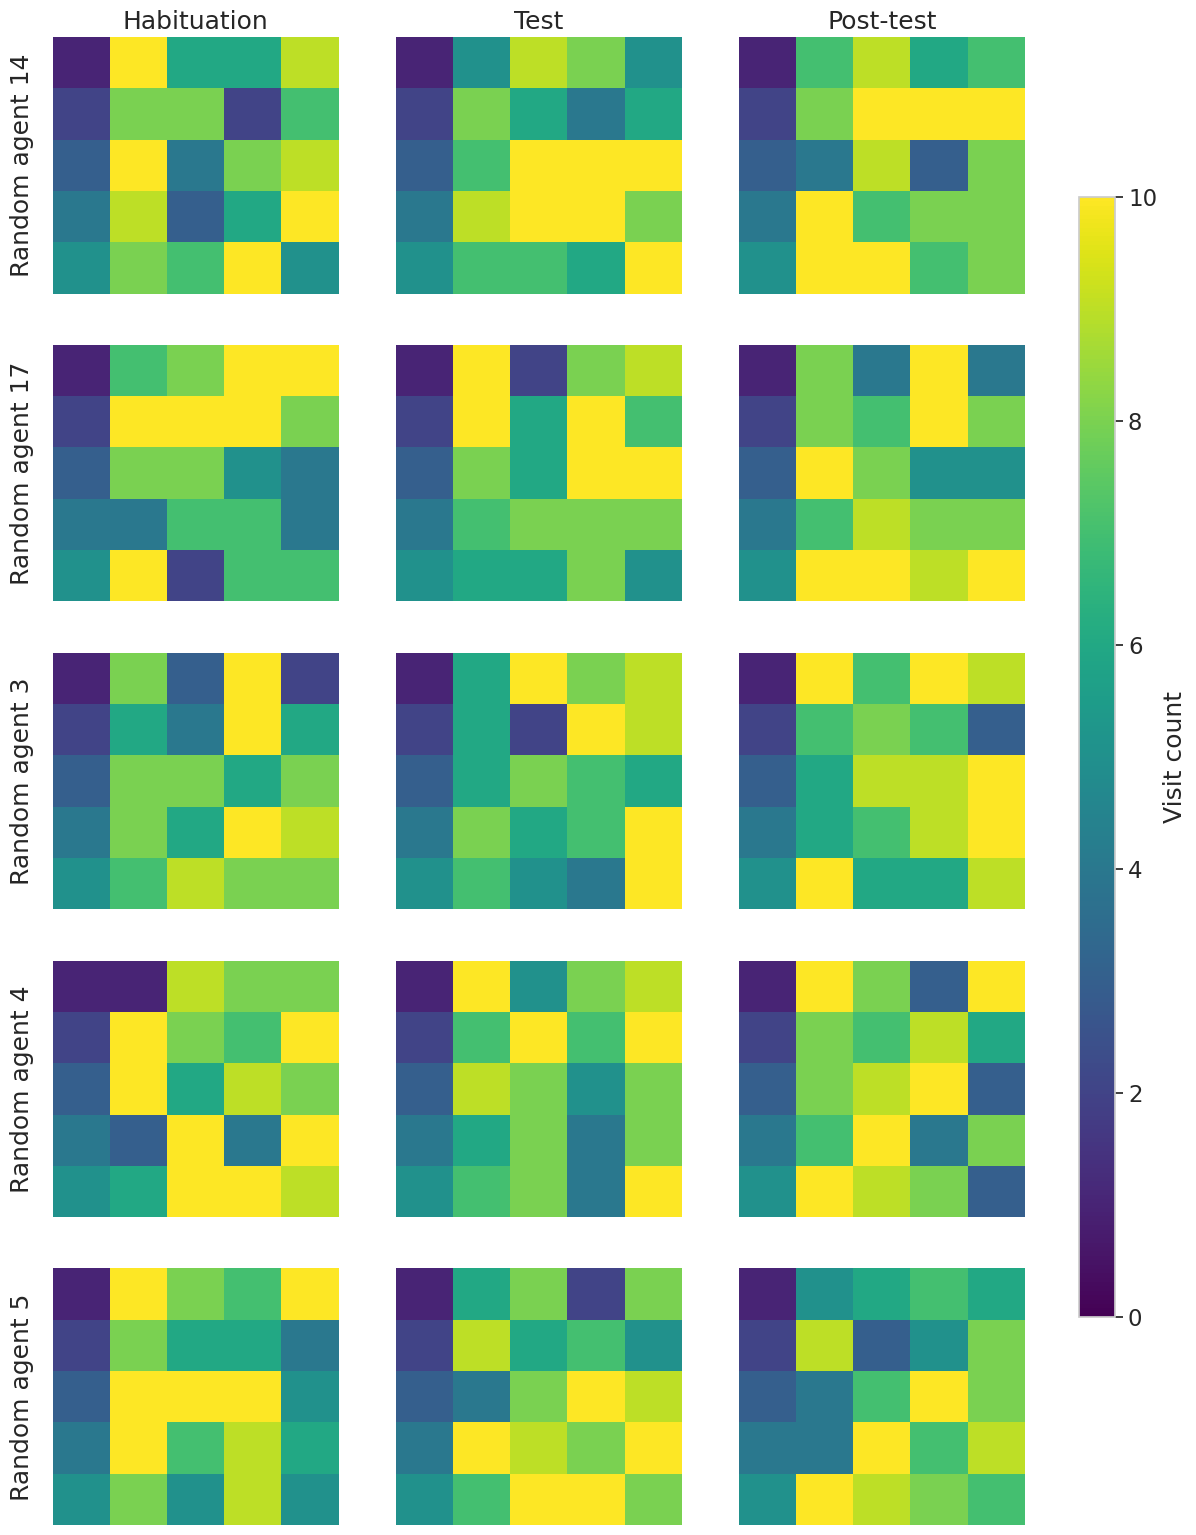

In [69]:
for grp in compare_visit_map.drop_duplicates().groupby(['Species','type']):
    num_sub = len(grp[1]['Subject'].unique())
    rows,cols = num_sub, 3
    fig,ax = pl.subplots(rows,cols,figsize=(12,16))
    
    for i,sub in enumerate(grp[1].groupby('Subject')):
        for j,ph in enumerate(phase_order):
            sl = sub[1].loc[sub[1]['Phase']==ph].copy()
            hm = sns.heatmap(sl[sl.columns[:5]],annot=False, cbar=False, ax=ax[i][j], vmin=0,vmax=10,cmap='viridis')
    
            if i == 0:
                ax[i][j].set_title(phase_order[j])
            ax[i][j].set_xticklabels([])
            ax[i][j].set_yticklabels([])
        ax[i][0].set_ylabel(sub[0])
        mappable = hm.collections[0]

    cbar_ax = fig.add_axes([0.915, 0.15, 0.03, 0.7])

    fig.colorbar(
        mappable,
        cax=cbar_ax,
        label="Visit count"
    )        
#     pl.tight_layout()
    fig.subplots_adjust(right=0.87,top=0.95,left=0.06,bottom=0.02)
#     fig.savefig(fig_dir+"Visit_heat_map_"+grp[0][0]+"_"+grp[0][1]+"_model_comparison_"+"high_res_updated_with_effort.png")
    fig.savefig(fig_dir+"Visit_heat_map_"+grp[0][0]+"_"+grp[0][1]+"_model_comparison_"+"high_res_updated_with_effort_wo_reward.png")


In [76]:
sl[sl.columns[:5]]/sl[sl.columns[:5]].sum().sum()

,Unnamed: 0,1,2,3,4
5215,0.006289,0.031447,0.037736,0.044025,0.037736
5216,0.012579,0.056604,0.018868,0.031447,0.050314
5217,0.018868,0.025157,0.044025,0.069182,0.050314
5218,0.025157,0.025157,0.069182,0.044025,0.056604
5219,0.031447,0.062893,0.056604,0.050314,0.044025


In [77]:
sl[sl.columns[:5]].sum()

Unnamed: 0    15.0
1             32.0
2             36.0
3             38.0
4             38.0
dtype: float64

In [78]:
sl[sl.columns[:5]]

,Unnamed: 0,1,2,3,4
5215,1,5.0,6.0,7.0,6.0
5216,2,9.0,3.0,5.0,8.0
5217,3,4.0,7.0,11.0,8.0
5218,4,4.0,11.0,7.0,9.0
5219,5,10.0,9.0,8.0,7.0


In [79]:
compare_visit_map.loc[(compare_visit_map['Species']=='Macaca_mulatta')&(compare_visit_map['type']=='data')&(compare_visit_map['Phase']=='Habituation')&(compare_visit_map['Subject']=='Amidala')]

,Unnamed: 0,1,2,3,4,5,type,Subject,Phase,Species
0,1,0.0,1.0,3.0,2.0,2.0,data,Amidala,Habituation,Macaca_mulatta
1,2,2.0,4.0,5.0,5.0,4.0,data,Amidala,Habituation,Macaca_mulatta
2,3,5.0,6.0,5.0,4.0,5.0,data,Amidala,Habituation,Macaca_mulatta
3,4,5.0,4.0,6.0,5.0,4.0,data,Amidala,Habituation,Macaca_mulatta
4,5,5.0,4.0,6.0,4.0,4.0,data,Amidala,Habituation,Macaca_mulatta
590,1,0.0,1.0,3.0,2.0,2.0,data,Amidala,Habituation,Macaca_mulatta
591,2,2.0,4.0,5.0,5.0,4.0,data,Amidala,Habituation,Macaca_mulatta
592,3,5.0,6.0,5.0,4.0,5.0,data,Amidala,Habituation,Macaca_mulatta
593,4,5.0,4.0,6.0,5.0,4.0,data,Amidala,Habituation,Macaca_mulatta
594,5,5.0,4.0,6.0,4.0,4.0,data,Amidala,Habituation,Macaca_mulatta


In [80]:
compare_visit_map

,Unnamed: 0,1,2,3,4,5,type,Subject,Phase,Species
0,1,0.0,1.0,3.0,2.0,2.0,data,Amidala,Habituation,Macaca_mulatta
1,2,2.0,4.0,5.0,5.0,4.0,data,Amidala,Habituation,Macaca_mulatta
2,3,5.0,6.0,5.0,4.0,5.0,data,Amidala,Habituation,Macaca_mulatta
3,4,5.0,4.0,6.0,5.0,4.0,data,Amidala,Habituation,Macaca_mulatta
4,5,5.0,4.0,6.0,4.0,4.0,data,Amidala,Habituation,Macaca_mulatta
...,...,...,...,...,...,...,...,...,...,...
5305,1,4.0,7.0,6.0,7.0,5.0,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana
5306,2,5.0,10.0,8.0,7.0,8.0,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana
5307,3,8.0,14.0,11.0,9.0,7.0,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana
5308,4,4.0,12.0,7.0,10.0,11.0,model - C(effort_wo_reward),Yin,Test,Macaca_tonkeana


In [82]:
to_plot = all_model_fittings.melt(id_vars=['Subject','Species','Phase','NLL_per_choice','Model','BIC','NLL','Random_NLL_per_choice','nchoices','success'])

to_plot = to_plot.loc[~to_plot['variable'].str.contains('Unnamed')]
to_plot

,Subject,Species,Phase,NLL_per_choice,Model,BIC,NLL,Random_NLL_per_choice,nchoices,success,variable,value
531,Amidala,Macaca_mulatta,Habituation,2.410758,A,499.028895,229.022001,3.218876,95,True,WS(row),0.387741
532,Amidala,Macaca_mulatta,Post-test,2.095313,A,439.094449,199.054778,3.218876,95,True,WS(row),0.499212
533,Amidala,Macaca_mulatta,Test,2.258274,A,905.367261,429.072022,3.218876,190,True,WS(row),0.295811
534,Anyanka,Macaca_mulatta,Habituation,1.899540,A,401.897471,180.456289,3.218876,95,True,WS(row),0.357092
535,Anyanka,Macaca_mulatta,Post-test,1.767133,A,376.740203,167.877656,3.218876,95,True,WS(row),0.337000
...,...,...,...,...,...,...,...,...,...,...,...,...
11146,Yannick,Macaca_tonkeana,Post-test,1.459984,C(effort_wo_reward),327.489568,138.698461,3.218876,95,True,W(effort),5.334918
11147,Yannick,Macaca_tonkeana,Test,1.919197,C(effort_wo_reward),787.012261,364.647498,3.218876,190,True,W(effort),6.137330
11148,Yin,Macaca_tonkeana,Habituation,2.369104,C(effort_wo_reward),500.222349,225.064852,3.218876,95,True,W(effort),8.988438
11149,Yin,Macaca_tonkeana,Post-test,2.385787,C(effort_wo_reward),483.832603,217.106574,3.218876,91,True,W(effort),6.234368


In [83]:
param_names = to_plot.variable.unique()
param_names

array(['WS(row)', 'WS(column)', 'WS(cw_spiral)', 'WS(ccw_spiral)',
       'W(spatial_bias)', 'W(reward)', 'W(memory)', 'memory_recall',
       'beta', 'WS(left)', 'WS(right)', 'WS(up)', 'WS(down)',
       'WS(up_left)', 'WS(up_right)', 'WS(down_left)', 'WS(down_right)',
       'WS(clockwise_spiral)', 'WS(counter_clockwise_spiral)',
       'W(effort)'], dtype=object)

In [ ]:
for grp in all_model_fittings.groupby(['Model','Species']):
    pl.figure()
    print(grp[0])
    if grp[0][1] == 'Random':
        continue
    dat = grp[1].dropna(axis=1, how='all')
    sub_set = [ x for x in dat.columns  if x in param_names ]
    g1 = sns.pairplot(dat[sub_set+['Phase']],hue='Phase',kind='kde',corner=True)
    g1.savefig(fig_dir+"pairplot"+"_".join(grp[0])+".png")

('A', 'Macaca_mulatta')
('A', 'Macaca_tonkeana')


In [ ]:
dat

In [ ]:
all_model_fittings.groupby(['Model','Phase','Species'])[to_plot.variable.unique()].mean().reset_index()

In [ ]:
phase_order

In [ ]:
weights_spatial_df = to_plot.loc[to_plot['variable'].str.contains('WS')].copy()
weights_other_df = to_plot.loc[(to_plot['variable'].str.contains('W')&~(to_plot['variable'].str.contains('WS')))].copy()

for grp in weights_spatial_df.groupby('Model'):
    g1_sp_wt = plot_boxplots_with_points("Phase","value","Species",'variable',phase_order,cmap2,grp[1].loc[grp[1]['Species']!='Random'].dropna(),2,True,True)
    g1_sp_wt.savefig(fig_dir+"comparison_weights_with_points_spatial_mix_"+grp[0]+"high_res_updated_with_effort_wo_reward.png")    

In [ ]:
# for grp in weights_spatial_df.groupby('Model'):
#     pl.figure()
#     g1 = sns.catplot(x="Phase",y='value',hue='variable',data=grp[1].dropna(),col='Species',kind='box',sharey=False,palette=cmap2,dodge=True,order=phase_order)

In [ ]:
grp[1]

In [ ]:
weights_spatial_df

In [ ]:
for grp in weights_other_df.groupby('Species'):    
    print(grp[0])
    g1_oth_wt = plot_boxplots_with_points("Phase","value",'Model','variable',phase_order,cmap1,grp[1],3,True,True)
#     g1_oth_wt.savefig(fig_dir+"comparison_weights_with_points_other_"+grp[0]+"high_res_updated_with_effort.png")    
    g1_oth_wt.savefig(fig_dir+"comparison_weights_with_points_other_"+grp[0]+"high_res_updated_with_effort_wo_reward.png")    

In [ ]:
other_pars = to_plot.loc[~(to_plot['variable'].str.contains('W')|(to_plot['variable'].str.contains('nchoices')))]
other_pars

In [153]:
other_pars.variable.unique()

array(['memory_recall', 'beta'], dtype=object)

Macaca_mulatta


/tmp/ipykernel_399544/1902240995.py:3: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
/tmp/ipykernel_399544/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_399544/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)


Macaca_tonkeana


/tmp/ipykernel_399544/1902240995.py:3: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
/tmp/ipykernel_399544/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_399544/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)


Random


/tmp/ipykernel_399544/1902240995.py:3: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  g1 = sns.catplot(x=x_var,y=y_var,col=col_var,data=data,kind='box',hue=hue_var,col_wrap=col_wrap,palette=palette,order=order,fill=False,dodge=dodge,sharey=sharey,col_order=col_order)
/tmp/ipykernel_399544/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)
/tmp/ipykernel_399544/1902240995.py:11: UserWarning: The palette list has more values (10) than needed (9), which may not be intended.
  sns.stripplot(ax=ax,data=sub,x=x_var,y=y_var,hue=hue_var,palette=palette,order=order,dodge=dodge,legend=False,s=6)


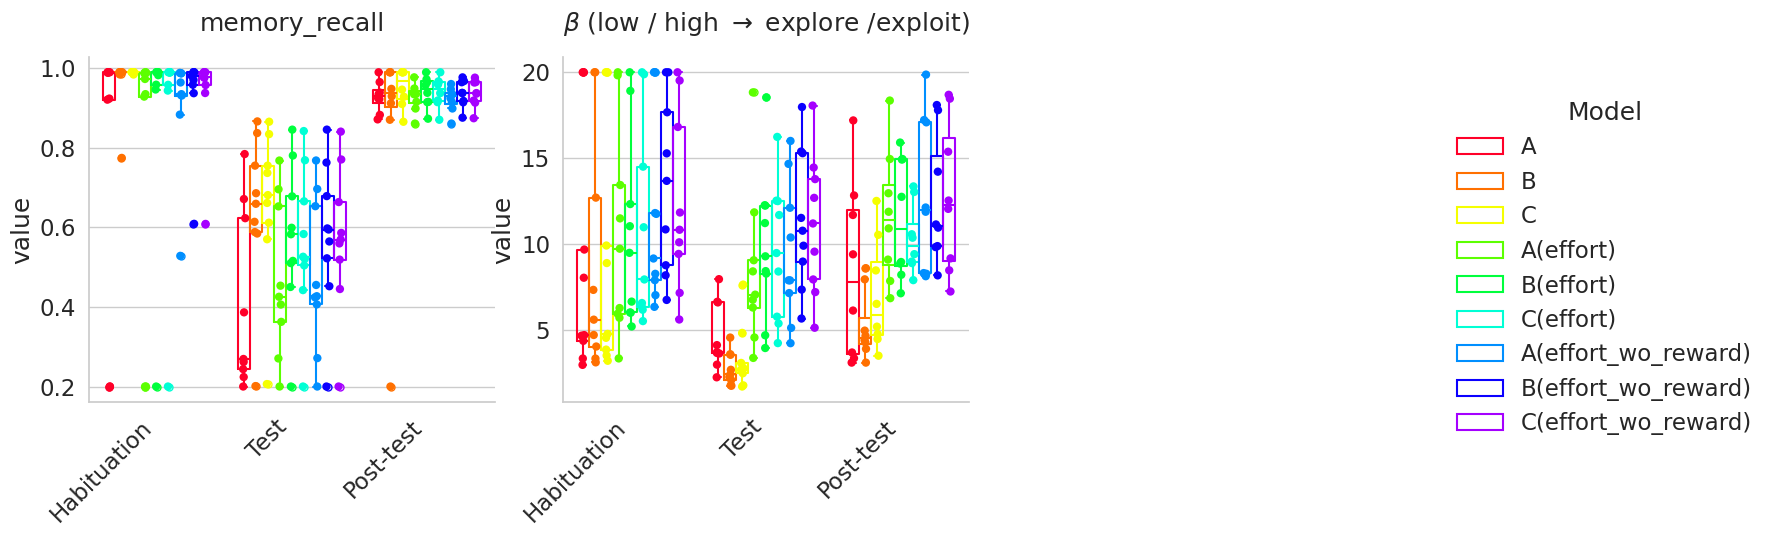

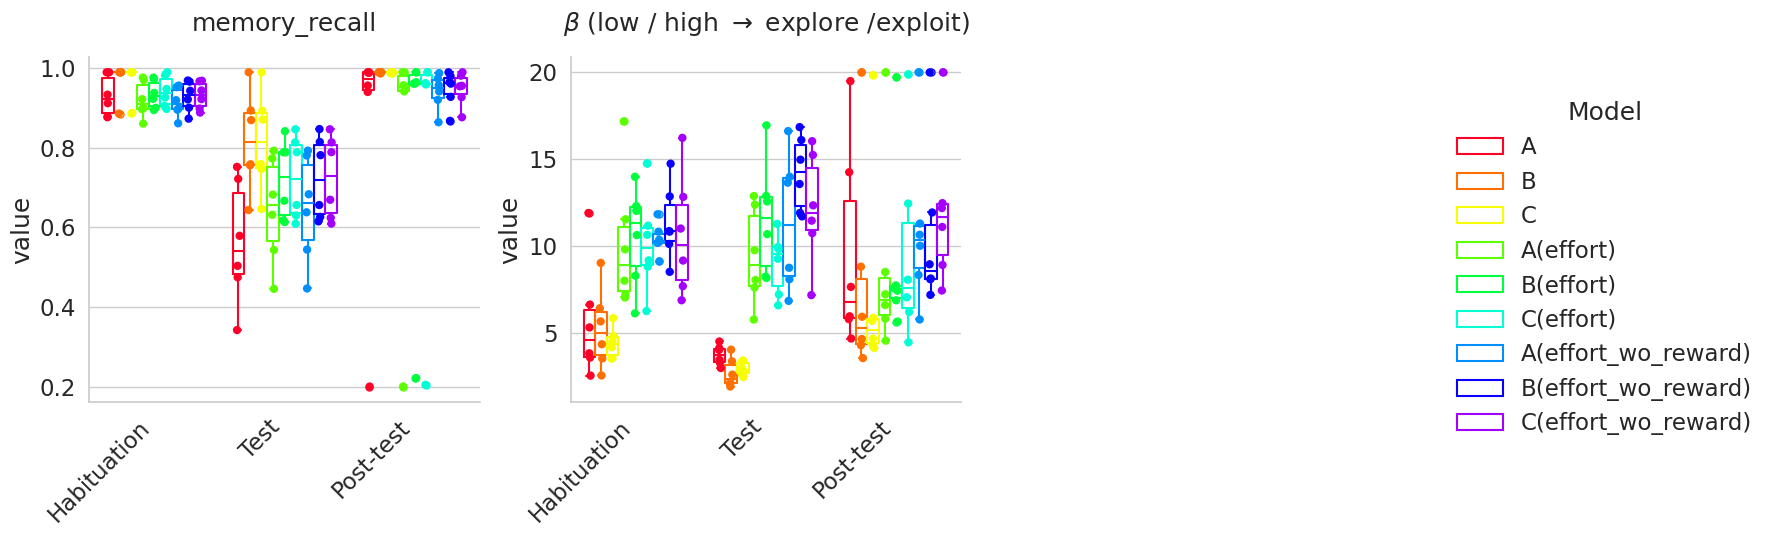

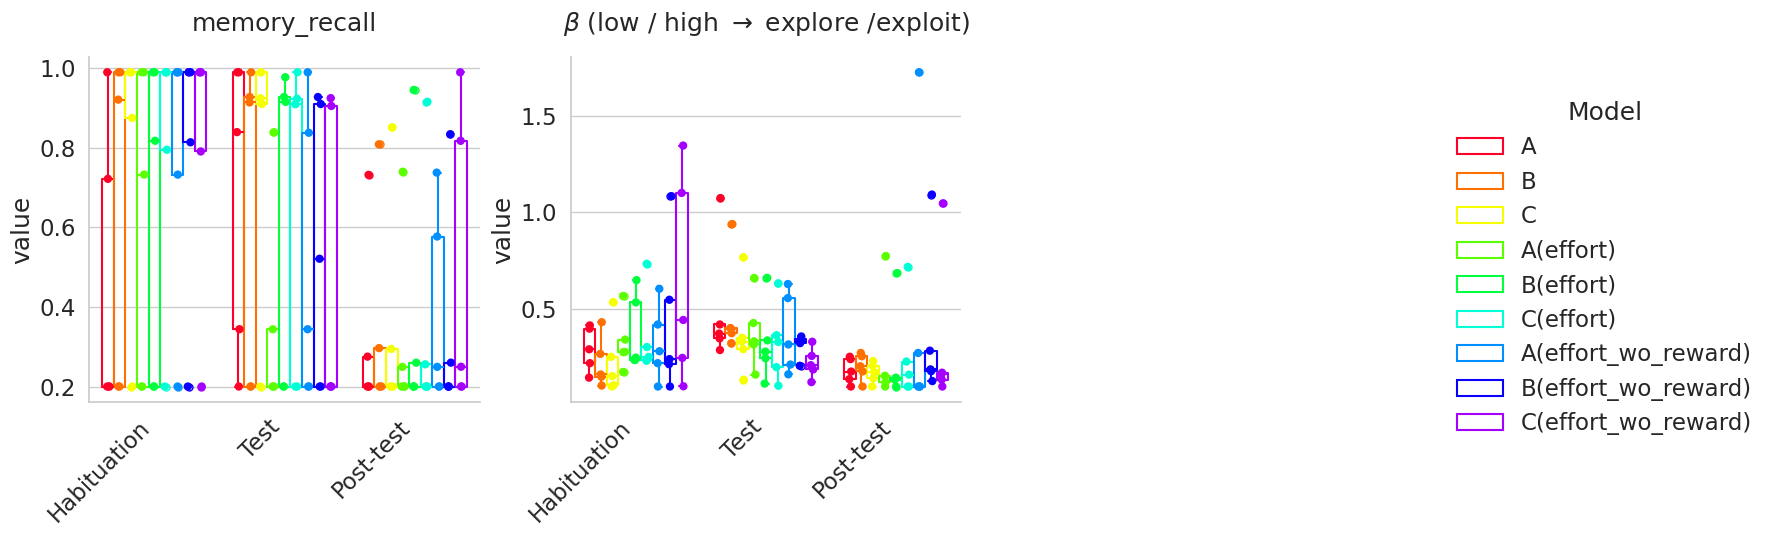

In [154]:
for grp in other_pars.groupby('Species'):
    print(grp[0])
    g1_oth = plot_boxplots_with_points("Phase","value","variable",'Model',phase_order,colors,grp[1],3,True,False)
    for ax in g1_oth.axes:
        tit = ax.get_title().split(' = ')[1]
        if tit == 'beta':
            tit = r'$\beta$'+' (low / high '+r'$\rightarrow$'+' explore /exploit)'
        ax.set_title(tit,y=1.05)
        ax.set_xlabel("")
#     g1_oth.savefig(fig_dir+"comparison_other_params_with_points_model_comparison_"+grp[0]+"high_res_updated_with_effort.png")    
        g1_oth.savefig(fig_dir+"comparison_other_params_with_points_model_comparison_"+grp[0]+"high_res_updated_with_effort_wo_reward.png")    

#     g1_oth.savefig(fig_dir+"comparison_other_params_with_points_model_comparison_"+grp[0]+".png")    

In [155]:
other_pars

,Subject,Species,Phase,NLL_per_choice,Model,BIC,NLL,Random_NLL_per_choice,nchoices,success,variable,value
3717,Amidala,Macaca_mulatta,Habituation,2.410758,A,499.028895,229.022001,3.218876,95,True,memory_recall,0.921152
3718,Amidala,Macaca_mulatta,Post-test,2.095313,A,439.094449,199.054778,3.218876,95,True,memory_recall,0.934702
3719,Amidala,Macaca_mulatta,Test,2.258274,A,905.367261,429.072022,3.218876,190,True,memory_recall,0.671331
3720,Anyanka,Macaca_mulatta,Habituation,1.899540,A,401.897471,180.456289,3.218876,95,True,memory_recall,0.988720
3721,Anyanka,Macaca_mulatta,Post-test,1.767133,A,376.740203,167.877656,3.218876,95,True,memory_recall,0.922361
...,...,...,...,...,...,...,...,...,...,...,...,...
4774,Yannick,Macaca_tonkeana,Post-test,1.459984,C(effort_wo_reward),327.489568,138.698461,3.218876,95,True,beta,20.000000
4775,Yannick,Macaca_tonkeana,Test,1.919197,C(effort_wo_reward),787.012261,364.647498,3.218876,190,True,beta,16.033668
4776,Yin,Macaca_tonkeana,Habituation,2.369104,C(effort_wo_reward),500.222349,225.064852,3.218876,95,True,beta,6.876745
4777,Yin,Macaca_tonkeana,Post-test,2.385787,C(effort_wo_reward),483.832603,217.106574,3.218876,91,True,beta,12.186081


In [156]:
model_fittings

,Model,Subject,Phase,Species,NLL,NLL_per_choice,Random_NLL_per_choice,nchoices,success,WS(row),...,WS(right),WS(up),WS(down),WS(up_left),WS(up_right),WS(down_left),WS(down_right),WS(clockwise_spiral),WS(counter_clockwise_spiral),BIC
0,A,Amidala,Habituation,Macaca_mulatta,229.022001,2.410758,3.218876,95,True,0.387741,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,499.028895
1,A,Amidala,Post-test,Macaca_mulatta,199.054778,2.095313,3.218876,95,True,0.499212,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,439.094449
2,A,Amidala,Test,Macaca_mulatta,429.072022,2.258274,3.218876,190,True,0.295811,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,905.367261
3,A,Anyanka,Habituation,Macaca_mulatta,180.456289,1.899540,3.218876,95,True,0.357092,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,401.897471
4,A,Anyanka,Post-test,Macaca_mulatta,167.877656,1.767133,3.218876,95,True,0.337000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,376.740203
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
172,C,Yannick,Post-test,Macaca_tonkeana,151.653762,1.596355,3.218876,95,True,NaN,...,0.059466,0.098197,0.079434,NaN,NaN,NaN,NaN,0.198624,0.419545,353.400169
173,C,Yannick,Test,Macaca_tonkeana,409.490619,2.155214,3.218876,190,True,NaN,...,0.074867,0.116307,0.079679,NaN,NaN,NaN,NaN,0.245878,0.351267,876.698503
174,C,Yin,Habituation,Macaca_tonkeana,236.584901,2.490367,3.218876,95,True,NaN,...,0.000050,0.000037,0.054540,NaN,NaN,NaN,NaN,0.460418,0.298878,523.262447
175,C,Yin,Post-test,Macaca_tonkeana,230.698938,2.535153,3.218876,91,True,NaN,...,0.067310,0.107361,0.060145,NaN,NaN,NaN,NaN,0.183732,0.370694,511.017331


In [157]:
# for grp in model_fittings.groupby('Species'):
#     g1 = sns.lmplot(x="beta",y="memory_recall",col='Phase',hue='Model',data=grp[1],facet_kws={'sharey':False,'sharex':False},palette=cmap3)
#     for ax in g1.axes[0]:
#         tit = ax.get_title().split(' = ')[1]
#         dat = grp[1].loc[grp[1]['Phase']==tit].copy()
#         for m in dat.groupby('Model'):
#             beta = m[1]['beta'].values
#             recall = m[1]['memory_recall'].values
#             ans = sp_st.pearsonr(beta,recall)
#             print(m[0],ans)
            

In [ ]:
base_params = [
    "W(row_scan)", "W(column_scan)", "W(spiral_scan)",
    "W(spatial_bias)", "W(reward)", "W(memory)",
    "memory_recall", "beta",
]
model_params = {
    "A": base_params,
#     "B": base_params + ["reward_decay"],
#     "C": base_params + ["W(reward_availability)"],
}

# plt.rcParams['axes.titley'] = 0.97
# plt.rcParams['axes.titlelocation'] = 'left' 

for model in ["A"]:#, "B"]:
    submodel = recovery_df[recovery_df["Model"] == model].copy()

    for species in sorted(submodel["Species"].dropna().unique()):
        for phase in sorted(
            submodel.loc[submodel["Species"] == species, "Phase"]
            .dropna().unique()
        ):
            sub = submodel[
                (submodel["Species"] == species)
                & (submodel["Phase"] == phase)
            ].copy()

            params = [
                p for p in model_params[model]
                if p in sub.columns and f"{p} - sim" in sub.columns
            ]

            ncols = 4
            nrows = int(np.ceil(len(params) / ncols))
            fig, axes = plt.subplots(
                nrows, ncols, figsize=(16, 4*nrows), squeeze=False
            )
            axes = axes.flatten()

            subjects = sorted(sub["Subject"].dropna().unique())
            cmap = plt.get_cmap("tab10")
            subject_colors = {
                s: cmap(i % 10) for i, s in enumerate(subjects)
            }
            
            ax_i = 0
            for ax, par in zip(axes, params):
                rec = f"{par} - sim"
                summary = (
                    sub.groupby("Subject")
                    .agg(
                        true_value=(par, "first"),
                        recovered_mean=(rec, "mean"),
                        recovered_sd=(rec, "std"),
                    )
                    .reset_index()
                )

                valid = pd.concat([
                    summary["true_value"],
                    summary["recovered_mean"] + summary["recovered_sd"]
                ]).dropna()

                if len(valid):
                    lo, hi = valid.min(), valid.max()
                    pad = 0.05 if np.isclose(lo, hi) else 0.05*(hi-lo)
                    if np.isclose(lo, hi) and lo != 0:
                        pad = abs(lo)*0.05
                    ax.plot(
                        [lo-pad, hi+pad], [lo-pad, hi+pad],
                        "--", color="gray", linewidth=1
                    )

                for _, row in summary.iterrows():
                    if pd.isna(row["true_value"]):
                        continue
                    ax.errorbar(
                        row["true_value"],
                        row["recovered_mean"],
                        yerr=row["recovered_sd"],
                        fmt="o", markersize=6, capsize=3,
                        color=subject_colors[row["Subject"]]
                    )

                ax.set_xlabel("True parameter")
                ax.set_ylabel("Recovered parameter")
                ax.set_title(par)
                ax.grid(alpha=0.2)
                if ax_i <=3 :
                    ax.set_xlabel("")

                if ax_i not in [0,4]:
                    ax.set_ylabel("")

                ax.spines.top.set_visible(False)
                ax.spines.right.set_visible(False)
                ax_i = ax_i + 1                

            for ax in axes[len(params):]:
                ax.axis("off")

            handles = [
                Line2D(
                    [0], [0], marker="o", linestyle="",
                    color=subject_colors[s], label=s, markersize=6
                )
                for s in subjects
            ]
            if handles:
#                 if 'tonkean' in species and model == 'A':
                    
                if 'mulatta' in species and model == 'B' :
                    fig.legend(
                        handles=handles, loc="lower center",
                        ncol=min(3, len(handles)),
                        bbox_to_anchor=(0.5, 0.2)
                    )
                else:
                    fig.legend(
                        handles=handles, loc="upper center",
                        ncol=min(3, len(handles)),
                        bbox_to_anchor=(0.8, 1.0)
                    )
                    
                    
            fig.suptitle(
                f"Recovery — Model {model} — {species} — {phase}",x=0.02,y=0.98,ha="left",va="top"             
            )
            plt.tight_layout(rect=[0, 0.04, 1, 0.95])
            fig.savefig(fig_dir+"recovery_plots_"+model+"_"+species+"_"+phase+".png")
#             plt.show()

In [ ]:

species_colors = {
    "Macaca_mulatta": colors_acc[0],
    "Macaca_tonkeana": colors_acc[1]
}

for model in ["A"]:  # , "B", "C"

    submodel = recovery_df[
        (recovery_df["Model"] == model) &
        (recovery_df["Phase"] == "Test")
    ].copy()

    # Parameters for this model
    params = [
        p for p in model_params[model]
        if p in submodel.columns and f"{p} - sim" in submodel.columns
    ]

    # One subplot per parameter
    ncols = 4
    nrows = int(np.ceil(len(params) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(16, 4 * nrows),
        squeeze=False
    )
    axes = axes.flatten()

    # ---------------------------------------------------------
    # Plot each parameter
    # ---------------------------------------------------------
    for ax_i, (ax, par) in enumerate(zip(axes, params)):

        rec = f"{par} - sim"

        all_summary = []

        # Plot both species on the same axis
        for species in sorted(species_colors.keys()):

            sub = submodel[
                submodel["Species"] == species
            ].copy()

            if sub.empty:
                continue

            summary = (
                sub.groupby("Subject")
                .agg(
                    true_value=(par, "first"),
                    recovered_mean=(rec, "mean"),
                    recovered_sd=(rec, "std"),
                )
                .reset_index()
            )

            summary["Species"] = species
            all_summary.append(summary)

            # ---------------------------------------------
            # Plot recovery points for this species
            # ---------------------------------------------
            for _, row in summary.iterrows():

                if pd.isna(row["true_value"]):
                    continue

                ax.errorbar(
                    row["true_value"],
                    row["recovered_mean"],
                    yerr=row["recovered_sd"],
                    fmt="o",
                    markersize=6,
                    capsize=3,
                    color=species_colors[species],
                    alpha=0.9
                )

        # -----------------------------------------------------
        # Identity line using BOTH species' parameter ranges
        # -----------------------------------------------------
        if all_summary:

            combined = pd.concat(all_summary, ignore_index=True)

            valid = pd.concat([
                combined["true_value"],
                combined["recovered_mean"] + combined["recovered_sd"],
                combined["recovered_mean"] - combined["recovered_sd"]
            ]).dropna()

            if len(valid):

                lo = valid.min()
                hi = valid.max()

                if np.isclose(lo, hi):
                    pad = abs(lo) * 0.05 if lo != 0 else 0.05
                else:
                    pad = 0.05 * (hi - lo)

                lo -= pad
                hi += pad

                ax.plot(
                    [lo, hi],
                    [lo, hi],
                    "--",
                    color="gray",
                    linewidth=1
                )

                ax.set_xlim(lo, hi)
                ax.set_ylim(lo, hi)

        # -----------------------------------------------------
        # Formatting
        # -----------------------------------------------------
        ax.set_title(par)
        ax.grid(alpha=0.2)

        # Only bottom row gets x-label
        if ax_i < len(params) - ncols:
            ax.set_xlabel("")
        else:
            ax.set_xlabel("True parameter")

        # Only first column gets y-label
        if ax_i % ncols == 0:
            ax.set_ylabel("Recovered parameter")
        else:
            ax.set_ylabel("")

        ax.spines.top.set_visible(False)
        ax.spines.right.set_visible(False)

    # ---------------------------------------------------------
    # Hide unused axes
    # ---------------------------------------------------------
    for ax in axes[len(params):]:
        ax.axis("off")

    # ---------------------------------------------------------
    # Species legend
    # ---------------------------------------------------------
    handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color=species_colors[s],
            label=s,
            markersize=6
        )
        for s in sorted(species_colors.keys())
        if s in submodel["Species"].unique()
    ]

    fig.legend(
        handles=handles,
        loc="upper right",
        bbox_to_anchor=(0.2, 0.995),
        ncol=1
    )

    # ---------------------------------------------------------
    # Title
    # ---------------------------------------------------------
    fig.suptitle("",
#         f"Recovery — Model {model} — Test",
        x=0.02,
        y=0.98,
        ha="left",
        va="top"
    )

    plt.tight_layout(
        rect=[0, 0, 0.94, 0.93]
    )

#     plt.show()
    fig.savefig(fig_dir+'Recovery_plots_Test_both_species.png',dpi=300)